# G5.38 — Dicke → targets angulares → Transformer (6C2, 6C3 e 6C4)

**Versão consolidada do mesmo experimento, sem o treinamento antigo com SPSA.** Esta versão mantém apenas o percurso atualmente estudado: **dados financeiros reais → Hamiltoniano → circuito de Dicke → geração de targets por otimização prévia → Transformer supervisionado → avaliação temporal e geométrica**.

**Leitura dos resultados já executados (preservados nas células):** o otimizador professor **conseguiu** ultrapassar $p_*\geq90\%$ em 194/198 tentativas de treino (2024) e 59/60 tentativas de validação (2024). Todas as **99 instâncias de treino** e as **30 de validação** obtiveram ao menos um target aprovado. **O Transformer, porém, não alcançou 90% em nenhuma das 12 avaliações de teste de cada arquitetura** (2025–2026). Essas duas taxas medem componentes diferentes, e não devem ser confundidas.

## Hipóteses examinadas

1. Para **6C2, 6C3 e 6C4**, os blocos de Dicke são respectivamente **8, 9 e 8**, e os estados válidos são **15, 20 e 15**.
2. **Mesmo $H$, mesma data e mesma ordem:** diferentes inicializações podem gerar soluções angulares distintas que levam à mesma carteira ótima. Mostrar $\theta_j$ e as trajetórias de otimização, com Dicke em linha tracejada.
3. **Permutar as mesmas seis ações:** mudar a posição dos qubits, permutando $\mu$ e $\Sigma$ de forma coerente, mas sem mudar as energias físicas das carteiras; estudar como isso altera os ângulos.
4. **Generalização entre datas:** treinar/validar em 2024 e avaliar, sem reajustar pesos, nas datas de 2025–2026.
5. **Reduzir informações:** testar 23, 18 e 15 atributos por token e agrupar tokens para a atenção, sem remover portas do circuito.

### Separação dos três objetos

- **Professor (otimizador prévio):** conhece, neste experimento pequeno, o conjunto exato das carteiras de menor energia, e busca ângulos que concentrem probabilidade nele. **Não é um VQE sem oráculo.**
- **Target:** apenas uma solução encontrada e *aprovada* com $p_*\geq0.90$; podem existir diversos vetores de ângulos igualmente válidos.
- **Estudante (Transformer):** aprende a mapear os tokens financeiros e geométricos para as correções $\Delta\phi$ e é avaliado independentemente. A aprovação do professor **não implica** que o aluno aprendeu.

**Execução:** rode as células A1 a A13 na ordem, a partir de um kernel limpo. Os outputs abaixo, de A1–A12, são registros da execução do arquivo enviado e não foram reprocessados durante esta edição. Reexecutar é necessário para novos gráficos do diagnóstico A13. O diretório de cache dos seis ativos foi mantido para reutilizar seus preços reais, sem fabricar séries.


> **Extensão A14–A22 (2026-10-22):** ablação 2×2 com Hamiltoniano completo (27 atributos globais) e perda física diferenciável em probabilidades, sem SPSA. O histórico A1–A13 permanece abaixo com suas saídas anteriores. Para rodar sem treinar os baselines antigos, execute A1–A7 e depois A15–A22 (A9/A8–A13 não são exigidos).


## A1 — Configuração reproduzível

Defina **seis ações**, as cardinalidades $k\in\{2,3,4\}$, os períodos de treino/validação/teste e o orçamento do otimizador professor. Para $n=6$:

| Topologia | Estados válidos $\binom{6}{k}$ | Blocos $g=k(6-k)$ | Entrada base |
|:--|--:|--:|:--|
| 6C2 | 15 | 8 | $8\times23$ |
| 6C3 | 20 | 9 | $9\times23$ |
| 6C4 | 15 | 8 | $8\times23$ |

Cada **token descreve uma operação**. Os cinco atributos extras da CCY codificam $m=i+1$, $\mu_m$, $\Sigma_{mm}$, $\Sigma_{im}$ e $\Sigma_{ml}$; no CY ficam zerados. A atenção opera em **48 dimensões internas**, não em 23 qubits nem em 48 portas.


In [1]:
# A1 — Configuração explícita. ALTERE AQUI os tamanhos do experimento.
from pathlib import Path
from itertools import combinations
from scipy.optimize import minimize
from IPython.display import display
import hashlib, json, time, copy, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

G539_BASE = Path('g539_dicke_6ativos_alvos_23d').resolve()
G539_BASE.mkdir(parents=True, exist_ok=True)
G539_TICKERS = ['AAPL', 'MSFT', 'JPM', 'JNJ', 'XOM', 'PG']  # 6 séries reais; edite se necessário
G539_N = len(G539_TICKERS)
G539_KS = [2, 3, 4]
G539_SEED = 20261021
G539_RHO = 1.2                 # faixa de saída de cada delta_phi do modelo atual
G539_THRESHOLD = 0.90          # critério mínimo para aceitar um target
G539_OPT_MAXITER = 140        # maior = maior custo do gerador de targets, NÃO custo da rede
G539_RESTARTS = 2             # tentativas por (data, k, permutação) para os alvos supervisionados
G539_TRAIN_PERMS = 3          # quantas permutações por data/ k entram somente no treino
G539_VAL_PERMS = 2            # avaliar permutações NÃO usadas no treino, em outras datas
G539_EPOCHS = 35             # treino apenas PyTorch (sem SPSA)
G539_LR = 7e-4
G539_REPETICOES_IDENTICAS = 8 # MESMO H e MESMA permutação: sementes diferentes
G539_N_PERMS_GRAFICO = 8      # MESMO H, mudar somente a ordem dos ativos
G539_PERM_RESTARTS = 2
G539_PROBE_DATE = '2025-06-30'   # somente avaliação APÓS congelar o modelo
G539_CACHE = G539_BASE / 'precos_reais_yahoo_6ativos.csv'

# Datas disjuntas: treino e seleção de modelo separados cronologicamente.
G539_DATES = {
    'treino_2024': pd.date_range('2024-03-01','2024-07-31',freq='2W-FRI').strftime('%Y-%m-%d').tolist(),
    'validacao_2024': pd.date_range('2024-08-02','2024-09-27',freq='2W-FRI').strftime('%Y-%m-%d').tolist(),
    'teste_2025': ['2025-06-30', '2025-12-30'],
    'teste_2026': ['2026-06-30', '2026-09-30'],
}
assert G539_N == 6 and len(set(G539_TICKERS)) == 6
assert max(G539_DATES['treino_2024']) < min(G539_DATES['validacao_2024'])
assert max(G539_DATES['validacao_2024']) < min(G539_DATES['teste_2025'])
print('Topologias:', [(f'6C{k}', math.comb(6,k),k*(6-k)) for k in G539_KS])
print('Datas por split:', {g: len(v) for g,v in G539_DATES.items()})

Topologias: [('6C2', 15, 8), ('6C3', 20, 9), ('6C4', 15, 8)]
Datas por split: {'treino_2024': 11, 'validacao_2024': 5, 'teste_2025': 2, 'teste_2026': 2}


## A2 — Fonte dos seis ativos, datas e isolamento temporal

Usamos seis séries reais: **AAPL, MSFT, JPM, JNJ, XOM e PG**, com cache exclusivo para este experimento. A janela de cada Hamiltoniano contém somente os **60 retornos anteriores ou iguais à data**. Para qualquer data nova, $H(t)=(\mu(t),\Sigma(t))$ será diferente; para o teste de permutação mantemos $H(t)$ FIXO e alteramos exclusivamente a ordem das coordenadas.

No primeiro uso, é necessário acesso à internet (ou um CSV real já salvo no caminho configurado). Em execução posterior, a fonte do cache é exibida. Na ausência de dados reais, esta seção para com erro em vez de criar observações artificiais.

In [2]:
# A2 — Coletar/ler seis séries REAIS; mantém o cache próprio dos seis ativos.
def g539_precos_reais():
    if G539_CACHE.exists():
        preços = pd.read_csv(G539_CACHE, index_col=0, parse_dates=True)
        origem = f'cache real existente: {G539_CACHE}'
    else:
        try:
            import yfinance as yf
        except ImportError as exc:
            raise ImportError('Instale yfinance: %pip install yfinance; sem dados reais não executar.') from exc
        df = yf.download(G539_TICKERS, start='2023-01-01', end='2026-10-01',
                         auto_adjust=True, progress=False, threads=False)
        if df is None or df.empty:
            raise RuntimeError('Yahoo Finance não disponibilizou dados. Não serão simulados preços.')
        if isinstance(df.columns, pd.MultiIndex):
            try: preços = df['Close']
            except KeyError: preços = df.xs('Close', level=1, axis=1)
        else:
            if len(G539_TICKERS) != 1: raise ValueError('Colunas retornadas sem tickers identificados')
            preços = df[['Close']].rename(columns={'Close': G539_TICKERS[0]})
        preços = preços.loc[:, G539_TICKERS]
        preços.to_csv(G539_CACHE)
        origem = f'Yahoo Finance (novo download), cache: {G539_CACHE}'
    preços.index = pd.to_datetime(preços.index).tz_localize(None)
    preços = preços.sort_index().loc[:, G539_TICKERS].astype(float).dropna()
    if not np.isfinite(preços.to_numpy()).all() or (preços<=0).any().any():
        raise ValueError('Preços reais inválidos.')
    if preços.index.min() > pd.Timestamp('2023-09-01') or preços.index.max() < pd.Timestamp('2026-09-30'):
        raise ValueError('O arquivo não cobre adequadamente treino e testes até set/2026.')
    return preços, origem

G539_PRECOS, G539_ORIGEM = g539_precos_reais()
G539_RET = G539_PRECOS.pct_change(fill_method=None).dropna()
print(G539_ORIGEM, '| preços:', G539_PRECOS.shape, '| retornos:', G539_RET.shape)

# Cada grupo usa exclusivamente uma janela retrospectiva do próprio histórico.
def g539_hamiltoniano(data):
    t = pd.Timestamp(data)
    janela = G539_RET.loc[:t, G539_TICKERS].tail(60)
    if len(janela) < 60 or (t-janela.index[-1]).days > 10:
        raise ValueError(f'Janela retrospectiva de 60 dias indisponível em {data}')
    mu = (252*janela.mean()).to_numpy(dtype=float)
    cov = 252*janela.cov().to_numpy(dtype=float)
    return mu, (cov+cov.T)/2

cache real existente: C:\Users\Marlon\Downloads\g539_dicke_6ativos_alvos_23d\precos_reais_yahoo_6ativos.csv | preços: (939, 6) | retornos: (938, 6)


## A3 — Simulador NumPy do circuito parametrizado de Dicke para 6 qubits

O gerador de targets precisa executar milhares de avaliações, mas não precisa executar Qiskit através do autograd. Para baratear o experimento pequeno, usamos a mesma sequência de portas CX–RY–(CX/CCX)–RY–(CX/CCX)–CX com um **simulador NumPy de amplitudes reais** de $2^6=64$ posições. Não é um ansatz novo. O simulador NumPy é autocontido; esta versão não depende do Qiskit no treinamento. Equivalência de fases com um simulador externo permanece uma verificação independente recomendada.

**Teste obrigatório:** no ângulo analítico $\phi_D$, o simulador deve fornecer exatamente $1/\binom6k$ para todos os bitstrings válidos, zero fora do subespaço, e norma igual a um. Qualquer falha interrompe a execução.

In [3]:
# A3 — Definição explícita da topologia do ansatz (sem dependência de células removidas).
def portas_dicke(n, k):
    portas = []
    for l in range(n-1, -1, -1):
        for i in range(l-1, l-1-k, -1):
            if i < 0 or (l >= n-k and i >= n-k):
                continue
            tipo = 'CY' if i == l-1 else 'CCY'
            ang = (2 if tipo == 'CY' else 1)*np.arccos(np.sqrt((l-i)/(l+1)))
            periodo = 4*np.pi if tipo == 'CY' else 2*np.pi
            portas.append(dict(j=len(portas), i=i, l=l, tipo=tipo,
                                periodo=periodo, phiD=2*np.pi*ang/periodo))
    assert len(portas) == k*(n-k)
    return portas


# A3 — Executa exatamente a decomposição parametrizada CX–RY–CX/CCX–RY–CX/CCX–CX.
class G539Circuito:
    def __init__(self, n, k):
        self.n, self.k = int(n), int(k)
        self.portas = portas_dicke(n,k)  # mesma regra combinatória definida acima
        self.g = len(self.portas)
        self.phiD = np.array([p['phiD'] for p in self.portas], dtype=float)
        self.periodo = np.array([p['periodo'] for p in self.portas], dtype=float)
        self.X = np.array([np.eye(n,dtype=int)[list(comb)].sum(axis=0)
                           for comb in combinations(range(n), k)], dtype=int)
        self.indices = (self.X * (1 << np.arange(n))).sum(axis=1).astype(int)
        base = np.arange(1<<n)
        def inversao(controls,target):
            ok = ((base>>target)&1)==0
            for c in controls: ok &= ((base>>c)&1)==1
            lo=base[ok];return lo,(lo | (1<<target))
        def rotacoes(target):
            lo=base[((base>>target)&1)==0]
            return lo,(lo | (1<<target))
        self.pares=[]
        for gate in self.portas:
            i,l=gate['i'],gate['l']
            troca=inversao([i],l)
            rot=rotacoes(i)
            ctrl=inversao([l],i) if gate['tipo']=='CY' else inversao([l,i+1],i)
            self.pares.append((troca,rot,ctrl))

    def amplitudes(self, phi):
        phi=np.asarray(phi,dtype=float)
        if phi.shape != (self.g,): raise ValueError(f'Esperados {self.g} ângulos.')
        state=np.zeros(1<<self.n,dtype=float)
        # Estado inicial de cardinalidade k: os k qubits de índices mais altos iniciam em 1.
        ini=sum(1<<(self.n-1-j) for j in range(self.k))
        state[ini]=1.
        for j,(troca,rot,ctrl) in enumerate(self.pares):
            a,b=troca;state[a],state[b]=state[b].copy(),state[a].copy()
            theta=phi[j]*self.periodo[j]/(2*np.pi)
            ang=theta/2 if self.portas[j]['tipo']=='CY' else theta
            co,si=np.cos(ang/2),np.sin(ang/2)
            a,b=rot;aa,bb=state[a].copy(),state[b].copy()
            state[a],state[b]=co*aa-si*bb,si*aa+co*bb
            a,b=ctrl;state[a],state[b]=state[b].copy(),state[a].copy()
            a,b=rot;aa,bb=state[a].copy(),state[b].copy()
            state[a],state[b]=co*aa+si*bb,-si*aa+co*bb
            a,b=ctrl;state[a],state[b]=state[b].copy(),state[a].copy()
            a,b=troca;state[a],state[b]=state[b].copy(),state[a].copy()
        return state

    def probs(self,phi):
        ampl=self.amplitudes(phi)
        p=ampl**2
        if abs(p.sum()-1)>1e-9 or abs(p[self.indices].sum()-1)>1e-9:
            raise AssertionError('Perda de norma ou saída do subespaço de cardinalidade k.')
        return p[self.indices]

G539_CIRCUITOS={k:G539Circuito(6,k) for k in G539_KS}
for k,circuito in G539_CIRCUITOS.items():
    p=circuito.probs(circuito.phiD)
    assert np.allclose(p,1/math.comb(6,k),atol=1e-12)
    assert len(circuito.portas)==k*(6-k)
    print(f'6C{k}: estados={len(p)}, blocos={circuito.g}, Dicke={p[0]:.9f}, norma=OK')

6C2: estados=15, blocos=8, Dicke=0.066666667, norma=OK
6C3: estados=20, blocos=9, Dicke=0.050000000, norma=OK
6C4: estados=15, blocos=8, Dicke=0.066666667, norma=OK


## A4 — Como permutamos os seis ativos SEM mudar o problema?

Se $P$ representa uma permutação, devemos alterar **juntos** os retornos e a matriz de covariância:

$$\mu'=P\mu,\qquad\Sigma'=P\Sigma P^\top,\qquad x'=Px.$$

Assim, $E_{H'}(x')=E_H(x)$: são as MESMAS carteiras financeiras escritas em outra ordem. A identificação da resposta ótima deve ser remapeada para os nomes originais. A comparação de $\theta_j$ na posição $j$ é uma comparação de **coordenadas do mesmo ansatz em topologias de ativos reordenados**, e não de uma única porta física ligada aos mesmos ativos originais.

Para não introduzir aleatoriedade artificial no contexto energético, as 32 carteiras de contexto são sorteadas uma vez na ordem canônica e reordenadas junto com os ativos. Seus três resumos de energia ficam invariantes.

In [4]:
# A4 — Representação de instância e teste de invariância a permutação.
G539_COLUNAS = [
 'j/max(g-1,1)','n/(n+12)','k/n','i/(n-1)','l/(n-1)','is_CY','is_CCY',
 'phiD/pi','period/(4pi)','geom_Dicke','mu_i','mu_l','var_i','var_l',
 'cov_il','ctx_mean','ctx_std','ctx_min',
 'm/(n-1)_CCY','mu_m_CCY','var_m_CCY','cov_i_m_CCY','cov_m_l_CCY',
]
assert len(G539_COLUNAS)==23

def g539_energias(x,mu,Sigma):
    return 0.5*np.einsum('bi,ij,bj->b',x,Sigma,x)-x@mu

def g539_seed(*args):
    return int(hashlib.sha256(repr((G539_SEED,*args)).encode()).hexdigest()[:8],16)

def g539_instancia(data,k,perm=None,grupo=''): 
    mu0,cov0 = g539_hamiltoniano(data)
    perm=np.arange(6,dtype=int) if perm is None else np.asarray(perm,dtype=int)
    assert sorted(perm.tolist())==list(range(6))
    c=G539_CIRCUITOS[k]
    mu,cov=mu0[perm],cov0[np.ix_(perm,perm)]
    x0=c.X
    energies0=g539_energias(x0,mu0,cov0)
    # Conjunto canônico de respostas ótimas, inclusive empates numéricos.
    iopt=np.flatnonzero(np.isclose(energies0,energies0.min(),rtol=0,atol=1e-10))
    best_base={tuple(z) for z in x0[iopt]}
    ener=g539_energias(c.X,mu,cov)
    optimum=np.array([tuple(z[np.argsort(perm)]) in best_base for z in c.X],dtype=bool)
    assert optimum.any()
    # Para cada carteira, a energia sob permutação é exatamente a mesma no índice canônico.
    assert np.allclose(ener,g539_energias(c.X[:,np.argsort(perm)],mu0,cov0),atol=1e-10)
    idxctx=np.random.default_rng(g539_seed(data,k,'contexto')).integers(0,len(x0),size=32)
    xctx=x0[idxctx][:,perm]
    Ectx=g539_energias(xctx,mu,cov)
    return dict(data=data,grupo=grupo,k=k,perm=tuple(map(int,perm)),
                assets=tuple(G539_TICKERS[i] for i in perm),mu=mu,Sigma=cov,
                E=ener, mask_opt=optimum, E_opt=float(min(ener)),
                contexto=dict(mean=float(Ectx.mean()),std=float(Ectx.std()),sample_min=float(Ectx.min())),
                ref_labels=[''.join(G539_TICKERS[t]+' ' for t in np.flatnonzero(z)) for z in x0[iopt]])

def g539_tokens(r):
    c=G539_CIRCUITOS[r['k']];n=6;k=r['k'];mu=r['mu'];cov=r['Sigma'];ctx=r['contexto']
    v=np.diag(cov);linhas=[]
    for j,p in enumerate(c.portas):
        i,l=p['i'],p['l']; ccy=p['tipo']=='CCY'
        old=[j/max(c.g-1,1),n/(n+12),k/n,i/(n-1),l/(n-1),
             float(not ccy),float(ccy),p['phiD']/np.pi,p['periodo']/(4*np.pi),
             np.sqrt((l-i)/(l+1)),mu[i],mu[l],v[i],v[l],cov[i,l],
             ctx['mean'],ctx['std'],ctx['sample_min']]
        if ccy:
            m=i+1;extra=[m/(n-1),mu[m],v[m],cov[i,m],cov[m,l]]
        else:extra=[0.]*5
        linhas.append(old+extra)
    out=np.array(linhas,dtype=np.float32)
    assert out.shape==(k*(n-k),23) and np.isfinite(out).all()
    return out

# Verificar que permutar não altera o PROBLEMA financeiro.
for k in G539_KS:
    original=g539_instancia(G539_DATES['treino_2024'][0],k)
    trocada=g539_instancia(G539_DATES['treino_2024'][0],k,[2,0,5,1,3,4])
    assert np.isclose(original['E_opt'],trocada['E_opt'])
    assert np.isclose(original['contexto']['mean'],trocada['contexto']['mean'])
    assert np.isclose(original['contexto']['std'],trocada['contexto']['std'])
    assert np.isclose(original['contexto']['sample_min'],trocada['contexto']['sample_min'])
    assert g539_tokens(original).shape==(k*(6-k),23)
print('Invariância de energia, optimum e contexto sob permutação: OK')

Invariância de energia, optimum e contexto sob permutação: OK


## A5 — Gerar targets com $p_*\geq90\%$ (fora da retropropagação neural)

O otimizador **SciPy L-BFGS-B** varia todas as correções $\Delta\phi$ dentro de $[-1{,}2,+1{,}2]$, mantendo o mesmo ansatz de Dicke. O objetivo desta demonstração com oráculo pequeno é

$$L_{\rm teacher}(\Delta\phi)=-\log\big(p_*(\phi_D+\Delta\phi)+10^{-10}\big).$$

O mínimo energético de cada $H$ é calculado por enumeração de 15/20/15 estados **somente no gerador e no avaliador**. Cada execução salva sua semente, data, permutação, vetor $\theta$, diferença $\Delta\phi$, probabilidade $p_*$, número de avaliações e a trajetória iterativa. O alvo é aceito apenas se $p_*\geq0{,}9$. Não escrever `theta_optimo` sem ter passado por esse teste.

Usamos `callback` para desenhar a **evolução real dos ângulos de $\theta_D$ até a resposta**, sem interpolar valores inexistentes. Múltiplas execuções aprovadas para o mesmo $(H,\text{permutação})$ são guardadas como múltiplos targets, sem promediar ângulos potencialmente inequivalentes.

In [5]:
# A5 — A geração dos targets ocorre ANTES do treino PyTorch; targets calculados previamente, fora do treino.
def g539_wrap(ang):
    return np.arctan2(np.sin(ang),np.cos(ang))

def g539_teacher(r,seed,guardar_traj=False):
    c=G539_CIRCUITOS[r['k']]
    rng=np.random.default_rng(int(seed))
    delta0=np.zeros(c.g) if int(seed)%3==0 else rng.uniform(-0.75,0.75,c.g)
    mask=r['mask_opt']
    def pstar(delta):
        return float(c.probs(c.phiD+delta)[mask].sum())
    trajetoria=[dict(iteracao=0,p_star=pstar(delta0),
                     **{f'theta_j{j}':float((c.phiD[j]+delta0[j])*c.periodo[j]/(2*np.pi))
                        for j in range(c.g)})]
    def callback(x):
        if guardar_traj:
            trajetoria.append(dict(iteracao=len(trajetoria),p_star=pstar(x),
                **{f'theta_j{j}':float((c.phiD[j]+x[j])*c.periodo[j]/(2*np.pi))
                   for j in range(c.g)}))
    res=minimize(lambda delta:-np.log(max(pstar(delta),1e-12)),delta0,
                 method='L-BFGS-B',bounds=[(-G539_RHO+1e-4,G539_RHO-1e-4)]*c.g,
                 callback=callback,options=dict(maxiter=G539_OPT_MAXITER,ftol=1e-10,maxfun=3000))
    d=np.asarray(res.x,dtype=float);phi=c.phiD+d
    probs=c.probs(phi);pbest=float(probs[mask].sum())
    return dict(seed=int(seed),delta=d,phi=phi,
                theta=phi*c.periodo/(2*np.pi),p_star=pbest,
                accepted=bool(pbest>=G539_THRESHOLD-1e-12),
                objective=float(res.fun),nfev=int(res.nfev),nit=int(res.nit),
                status=str(res.message),tr=trajetoria if guardar_traj else [])

def g539_multistart(r,ns,tag,trajectorias=False):
    out=[]
    for z in range(ns):
        seed=g539_seed(r['data'],r['k'],r['perm'],tag,z)
        # A primeira execução determinística parte de Dicke, as outras de perturbações distintas.
        if z==0:seed=0
        out.append(g539_teacher(r,seed,guardar_traj=trajectorias))
    return out

def g539_resumo_targets(res,r,tag):
    return [dict(tipo=tag,data=r['data'],grupo=r['grupo'],k=r['k'],
                 perm='-'.join(map(str,r['perm'])),ativos='|'.join(r['assets']),
                 seed=v['seed'],p_star=v['p_star'],accepted=v['accepted'],
                 nfev=v['nfev'],nit=v['nit'],**{f'theta_j{j}':float(q) for j,q in enumerate(v['theta'])})
            for v in res]

# TESTE DE UNIDADE, SEM DADOS EXPERIMENTAIS ARTIFICIAIS: comparar repetibilidade exata.
unit=g539_instancia(G539_DATES['treino_2024'][0],2)
u1=g539_teacher(unit,0)
u2=g539_teacher(unit,0)
assert np.allclose(u1['theta'],u2['theta']) and u1['p_star']==u2['p_star']
assert np.max(np.abs(u1['delta']))<G539_RHO
print('Teste determinístico do teacher: OK; p* de teste computacional =',round(u1['p_star'],5))

Teste determinístico do teacher: OK; p* de teste computacional = 1.0


## A6 — Base supervisionada com datas independentes

**Treinamento:** dados de março–julho/2024, contendo múltiplas ordens de seis ativos e as topologias 6C2/3/4. **Validação:** agosto–setembro/2024 (usada para escolher checkpoint). **Teste fechado:** 2025/2026, jamais utilizado em `fit_scaler`, `loss`, seleção de época ou escolha arquitetural.

O gerador dos targets pode ser executado uma vez e salvo em disco para reutilizar os resultados na comparação de modelos. Se um caso não chegar a $90\%$, será explicitamente contabilizado como **falha de cobertura de targets**. Não inserir um alvo falso ou substituir por Dicke sem registrar.

> **Amostra piloto:** por ser pequena, esta base não pode provar generalização estatística. O intuito é descobrir invariâncias, não reivindicar publicação com esses poucos exemplos. Datas muito próximas ainda compartilham parte da janela de 60 pregões.

In [6]:
# A6 — Criar as instâncias primeiro; otimizar SOMENTE as datas de treino/validação.
_rng_perm=np.random.default_rng(G539_SEED)
G539_ID=tuple(range(6))
G539_ALL_PERMS=[G539_ID]
while len(G539_ALL_PERMS)<max(G539_TRAIN_PERMS+G539_VAL_PERMS,G539_N_PERMS_GRAFICO)+2:
    pp=tuple(map(int,_rng_perm.permutation(6)))
    if pp not in G539_ALL_PERMS:G539_ALL_PERMS.append(pp)
G539_PERMS_TRAIN=G539_ALL_PERMS[:G539_TRAIN_PERMS]
G539_PERMS_VAL=G539_ALL_PERMS[G539_TRAIN_PERMS:G539_TRAIN_PERMS+G539_VAL_PERMS]
assert set(G539_PERMS_TRAIN).isdisjoint(G539_PERMS_VAL)

G539_DATASETS={}
G539_LOG_TEACHER=[]
for split in ('treino_2024','validacao_2024'):
    lista=[]
    perms=G539_PERMS_TRAIN if split=='treino_2024' else G539_PERMS_VAL
    for date in G539_DATES[split]:
        for k in G539_KS:
            for perm in perms:
                r=g539_instancia(date,k,perm,split)
                r['tokens']=g539_tokens(r)
                tentativas=g539_multistart(r,G539_RESTARTS,tag='teacher_'+split)
                G539_LOG_TEACHER+=g539_resumo_targets(tentativas,r,'teacher_'+split)
                r['targets']=[v['delta'].copy() for v in tentativas if v['accepted']]
                r['n_pass']=len(r['targets']);r['n_attempts']=len(tentativas)
                lista.append(r)
    G539_DATASETS[split]=lista
    print(split,'instâncias',len(lista),'com target >= 90%',sum(r['n_pass']>0 for r in lista),
          'sem target',sum(r['n_pass']==0 for r in lista),flush=True)

G539_TRAIN=[r for r in G539_DATASETS['treino_2024'] if r['targets']]
G539_VAL=G539_DATASETS['validacao_2024']
G539_LOG_DF=pd.DataFrame(G539_LOG_TEACHER)
G539_LOG_DF.to_csv(G539_BASE/'targets_train_val_todas_tentativas.csv',index=False)
if len(G539_TRAIN)<8:
    raise RuntimeError('Menos de 8 instâncias com target >=90%: amplie G539_RESTARTS ou orçamento; não fabricar targets.')
print('Cobertura por topologia:')
display(G539_LOG_DF.groupby(['grupo','k']).agg(tentativas=('p_star','size'),
                      aprovadas=('accepted','sum'),p_mediana=('p_star','median')).round(4))

treino_2024 instâncias 99 com target >= 90% 99 sem target 0
validacao_2024 instâncias 30 com target >= 90% 30 sem target 0
Cobertura por topologia:


tentativas  aprovadas  p_mediana
grupo          k                                  
treino_2024    2          66         63        1.0
               3          66         66        1.0
               4          66         65        1.0
validacao_2024 2          20         20        1.0
               3          20         20        1.0
               4          20         19        1.0

## A7 — Um único Transformer para 6C2/6C3/6C4; saída variável $g$

A rede continua **encoder-only** e usa `d_model=48`, quatro cabeças de atenção e duas camadas. Para cada exemplo:

$$T_H\in\mathbb R^{g\times d_{in}},\qquad
\Delta\phi_{\rm pred}\in\mathbb R^g,\quad g=k(6-k).$$

Experimentos de **atributos**: 23D, 18D (legado) e 15D (redução com informação do 3º qubit). Experimento de **tokens**: `23D_group2` cria blocos de contexto pela média de pares de embeddings, executa a atenção apenas sobre $\lceil g/2\rceil$ tokens agrupados e devolve o contexto agrupado às consultas de cada gate; **não remove portas, nem colapsa os $g$ valores de saída**. É uma arquitetura nova a ser comparada; não assume que preservar a física será automático.

Devido à não unicidade dos parâmetros, quando há múltiplos targets aceitos para o mesmo $H$, treinamos pela **menor distância angular circular** entre a previsão e qualquer um dos targets aceitos, sem promediar configurações incompatíveis:

$$\mathcal L=\min_{\delta^*\in\mathcal S_H}\frac1g\sum_j
\operatorname{atan2}(\sin(\hat\delta_j-\delta_j^*),\cos(\hat\delta_j-\delta_j^*))^2.$$

Essa loss **não chama Qiskit nem SPSA**. A escolha do checkpoint é feita somente pelo $p_*$ médio das datas de validação/2024, medido pelo simulador exato.

In [7]:
# A7 — Ablations: 23D, 18D, 15D, 23D com metade dos tokens na atenção.
G539_FEATURES={
    '23D': list(range(23)),
    '18D': list(range(18)),
    '15D': [0,2,3,4,6,7,10,11,12,13,14,19,20,21,22],
    '23D_group2': list(range(23)),
}
# Ajustes usando APENAS treino/2024, nunca normalizar com os dados de teste.
G539_SCALERS={}
for key,indices in G539_FEATURES.items():
    arr=np.concatenate([r['tokens'][:,indices] for r in G539_TRAIN],axis=0)
    mean=arr.mean(0);std=np.maximum(arr.std(0),1e-5)
    G539_SCALERS[key]=(mean,std)
    np.savez(G539_BASE/f'scaler_trainonly_{key}.npz',mean=mean,std=std,feature_idx=indices)

def g539_input(r,key):
    m,s=G539_SCALERS[key]; ii=G539_FEATURES[key]
    t=np.clip((r['tokens'][:,ii]-m)/s,-10.,10.)
    return torch.as_tensor(t,dtype=torch.float32)

class G539Transformer(nn.Module):
    def __init__(self,n_features,group_size=1):
        super().__init__()
        self.group_size=group_size
        self.embed=nn.Sequential(nn.Linear(n_features,48),nn.LayerNorm(48))
        layer=nn.TransformerEncoderLayer(d_model=48,nhead=4,dim_feedforward=96,
                                         dropout=0.,activation='gelu',batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        self.norm=nn.LayerNorm(48)
        self.angle=nn.Linear(48,1)
        nn.init.zeros_(self.angle.weight);nn.init.zeros_(self.angle.bias)
    def forward(self,tok):
        h=self.embed(tok)
        if self.group_size==1:
            z=self.encoder(h.unsqueeze(0)).squeeze(0)
        else:
            # O agrupamento ocorre APENAS antes da autoatenção: queries continuam por gate.
            g=len(h);groups=[]
            for start in range(0,g,self.group_size):
                groups.append(h[start:start+self.group_size].mean(dim=0))
            pooled=torch.stack(groups,dim=0)
            ctx=self.encoder(pooled.unsqueeze(0)).squeeze(0)
            z=self.norm(h+torch.repeat_interleave(ctx,self.group_size,dim=0)[:g])
        return G539_RHO*torch.tanh(self.angle(z).squeeze(-1))

def g539_loss_multiple(pred,targets):
    tr=torch.tensor(np.stack(targets),dtype=pred.dtype,device=pred.device)
    diff=pred[None,:]-tr
    circ=torch.atan2(torch.sin(diff),torch.cos(diff))
    return (circ*circ).mean(dim=1).min()

# Checagens: formatos 8/9/8; rede retorna SEMPRE uma correção por porta.
for k in G539_KS:
    probe=g539_instancia(G539_DATES['treino_2024'][0],k)
    tok=g539_tokens(probe)
    for key,indices in G539_FEATURES.items():
        model=G539Transformer(len(indices),2 if key.endswith('group2') else 1)
        out=model(torch.tensor(tok[:,indices],dtype=torch.float32))
        assert out.shape==(k*(6-k),) and torch.all(out==0)
print('Validação de dimensões e inicialização em Dicke: OK')

Validação de dimensões e inicialização em Dicke: OK


## A8 — Treinar por ângulos de referência; selecionar pelo teste físico **somente na validação de 2024**

O orçamento de épocas, os Hamiltonianos e as sementes são iguais para cada ablação. O AdamW modifica pesos do Transformer, e não executa nenhum circuito durante `backward()`. O circuito de seis qubits é usado apenas para avaliação de qualidade nos checkpoints. A função de perda pode cair mesmo sem melhoria em $p_*$; mostramos ambos.

23D: melhor época 18, p*(val/2024)=0.3809
18D: melhor época 12, p*(val/2024)=0.3843
15D: melhor época 21, p*(val/2024)=0.3678
23D_group2: melhor época 9, p*(val/2024)=0.2675


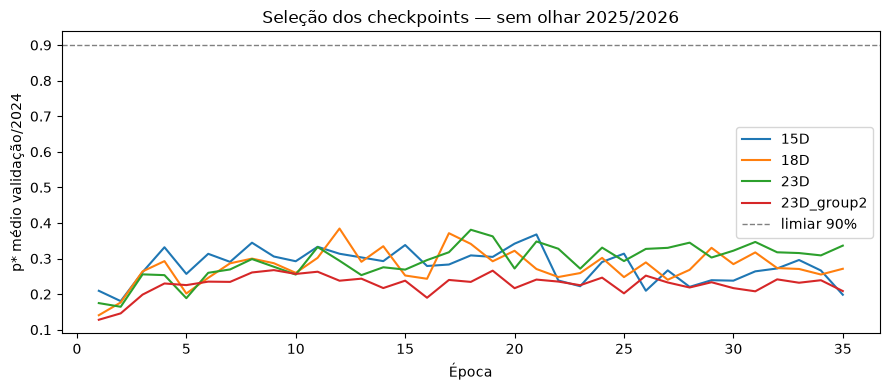

In [8]:
# A8 — Treino supervisionado real (sem SPSA).
torch.set_num_threads(min(torch.get_num_threads(),4))
G539_MODELOS={}
G539_HISTORY=[]

def g539_val_pstar(net,key,exemplos):
    net.eval();vals=[]
    with torch.no_grad():
        for r in exemplos:
            d=net(g539_input(r,key)).cpu().numpy()
            c=G539_CIRCUITOS[r['k']]
            vals.append(float(c.probs(c.phiD+d)[r['mask_opt']].sum()))
    return float(np.mean(vals)) if vals else np.nan

for key,indices in G539_FEATURES.items():
    torch.manual_seed(20261021)  # semente fixa para repetir a configuração do experimento
    net=G539Transformer(len(indices),group_size=2 if key.endswith('group2') else 1)
    opt=torch.optim.AdamW(net.parameters(),lr=G539_LR,weight_decay=1e-4)
    rng=np.random.default_rng(G539_SEED)
    best_score=-float('inf');best_state=None;best_epoch=None
    for epoch in range(1,G539_EPOCHS+1):
        net.train(); losses=[]
        for idx in rng.permutation(len(G539_TRAIN)):
            r=G539_TRAIN[int(idx)]
            pred=net(g539_input(r,key))
            loss=g539_loss_multiple(pred,r['targets'])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(),1.)
            opt.step()
            losses.append(float(loss.detach()))
        val=g539_val_pstar(net,key,G539_VAL)
        G539_HISTORY.append(dict(modelo=key,epoca=epoch,loss_treino=float(np.mean(losses)),
                                 pstar_validacao=val))
        if val>best_score+1e-12:
            best_score,best_epoch,best_state=val,epoch,copy.deepcopy(net.state_dict())
    net.load_state_dict(best_state);net.eval()
    G539_MODELOS[key]=net
    torch.save(best_state,G539_BASE/f'transformer_{key}_train_2024.pt')
    print(f'{key}: melhor época {best_epoch}, p*(val/2024)={best_score:.4f}',flush=True)

pd.DataFrame(G539_HISTORY).to_csv(G539_BASE/'curvas_treino_supervisionado_2024.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4))
for key,table in pd.DataFrame(G539_HISTORY).groupby('modelo'):
    ax.plot(table['epoca'],table['pstar_validacao'],label=key)
ax.axhline(G539_THRESHOLD,color='gray',ls='--',lw=1,label='limiar 90%')
ax.set(xlabel='Época',ylabel='p* médio validação/2024',title='Seleção dos checkpoints — sem olhar 2025/2026')
ax.legend();plt.tight_layout();plt.show()

## A9 — Congelar a rede e testar em 2025/2026, com datas diferentes

As previsões abaixo são feitas com pesos já congelados e **sem qualquer otimização**. Os melhores bitstrings de cada $H$ são enumerados somente para auditoria da probabilidade $p_*$, nunca repassados à rede. Comparamos as quatro arquiteturas contra o Dicke $1/\binom6k$ nas datas futuras. Além disso, desenhamos os ângulos $\theta_j$ previstos por data, mantendo a topologia fixa para cada gráfico; linhas tracejadas representam $\theta_D$.

modelo                      15D     18D     23D  23D_group2
grupo      data       k                                    
teste_2025 2025-06-30 2  0.2858  0.2923  0.7320      0.3590
                      3  0.2009  0.0478  0.2247      0.1062
                      4  0.1338  0.0031  0.0649      0.1491
           2025-12-30 2  0.4040  0.6851  0.3524      0.1106
                      3  0.7090  0.3604  0.5334      0.4501
                      4  0.8004  0.2175  0.8274      0.3630
teste_2026 2026-06-30 2  0.0803  0.3417  0.0234      0.1511
                      3  0.4536  0.2836  0.7081      0.1237
                      4  0.4043  0.0469  0.3118      0.2946
           2026-09-30 2  0.5873  0.3864  0.7970      0.6283
                      3  0.1687  0.2470  0.3551      0.1626
                      4  0.0395  0.3176  0.3291      0.1235

Taxa de aprovação de 90% por modelo (somente testes):


,instancias,aprovadas,p_medio
modelo,,,
15D,12,0,0.3556
18D,12,0,0.2691
23D,12,0,0.4383
23D_group2,12,0,0.2518


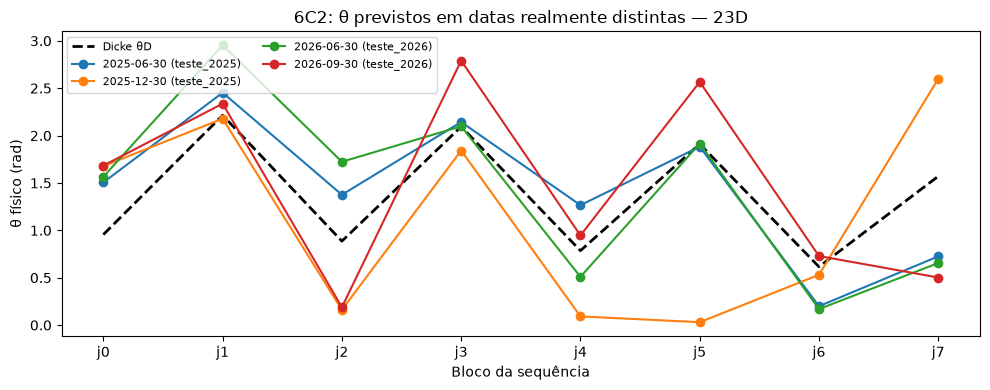

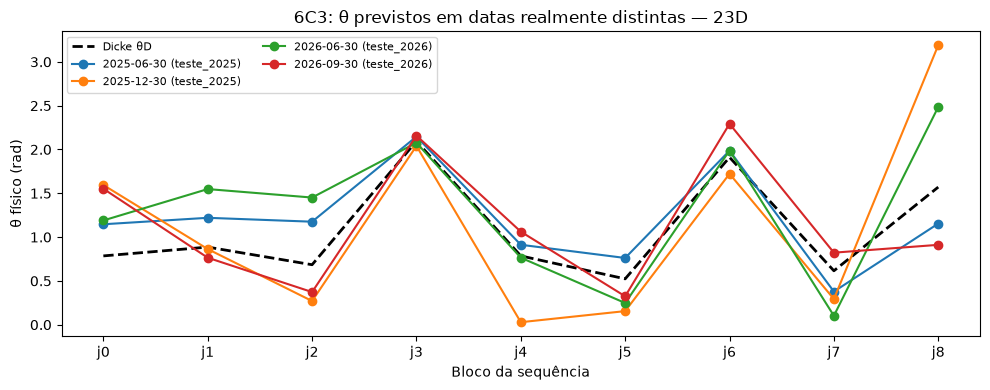

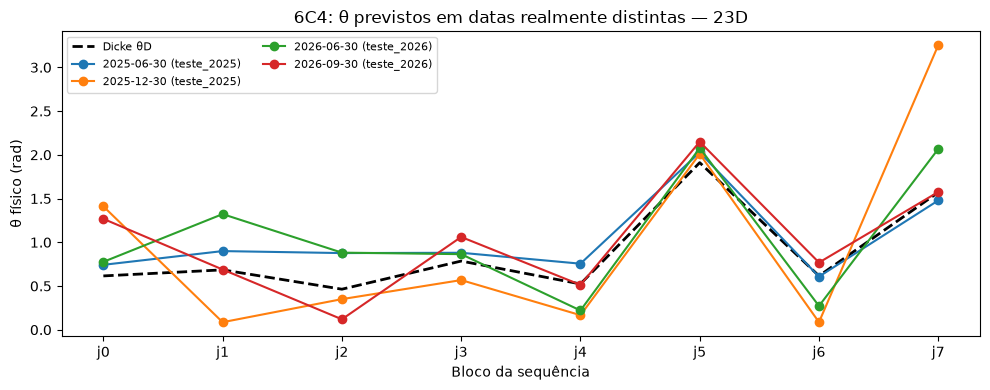

In [9]:
# A9 — Avaliação estritamente após congelamento; nenhuma escolha de arquitetura pelo teste.
G539_TEST_INSTANCIAS=[]
for split in ('teste_2025','teste_2026'):
    for date in G539_DATES[split]:
        for k in G539_KS:
            r=g539_instancia(date,k,G539_ID,split)
            r['tokens']=g539_tokens(r)
            G539_TEST_INSTANCIAS.append(r)

G539_TEST_SCORES=[]
for key,net in G539_MODELOS.items():
    net.eval()
    with torch.no_grad():
        for r in G539_TEST_INSTANCIAS:
            d=net(g539_input(r,key)).cpu().numpy()
            c=G539_CIRCUITOS[r['k']]
            p=float(c.probs(c.phiD+d)[r['mask_opt']].sum())
            G539_TEST_SCORES.append(dict(modelo=key,grupo=r['grupo'],data=r['data'],
                                   k=r['k'],p_star=p,passou90=bool(p>=G539_THRESHOLD),
                                   baseline_dicke=float(1/math.comb(6,r['k']))))
G539_TEST_DF=pd.DataFrame(G539_TEST_SCORES)
G539_TEST_DF.to_csv(G539_BASE/'comparacao_datas_futuras.csv',index=False)
display(G539_TEST_DF.pivot_table(index=['grupo','data','k'],columns='modelo',values='p_star').round(4))
print('Taxa de aprovação de 90% por modelo (somente testes):')
display(G539_TEST_DF.groupby('modelo').agg(instancias=('passou90','size'),
          aprovadas=('passou90','sum'),p_medio=('p_star','mean')).round(4))

for k in G539_KS:
    c=G539_CIRCUITOS[k]
    fig,ax=plt.subplots(figsize=(10,4))
    x=np.arange(c.g)
    ax.plot(x,c.phiD*c.periodo/(2*np.pi),color='black',ls='--',lw=2,label='Dicke θD')
    net=G539_MODELOS['23D'];net.eval()
    with torch.no_grad():
        for r in G539_TEST_INSTANCIAS:
            if r['k']!=k:continue
            d=net(g539_input(r,'23D')).numpy()
            ax.plot(x,(c.phiD+d)*c.periodo/(2*np.pi),marker='o',
                    label=f"{r['data']} ({r['grupo']})")
    ax.set(xticks=x,xticklabels=[f'j{j}' for j in x],xlabel='Bloco da sequência',
           ylabel='θ físico (rad)',title=f'6C{k}: θ previstos em datas realmente distintas — 23D')
    ax.legend(fontsize=8,ncol=2);plt.tight_layout();plt.show()

## A10 — Gráfico pedido: **não mudar absolutamente nada** e repetir a busca

Agora congelamos para cada 6C2/6C3/6C4: **a data, os seis ativos, a ordem, o Hamiltoniano e o bitstring ótimo**. Só mudamos a semente/ponto de partida do otimizador que constrói targets. Desenhamos:

- Linhas **tracejadas** de $\theta_j$ de todas as soluções com $p_*\geq0{,}90$; Dicke como linha preta; resultados abaixo de 90% não são rotulados como targets.
- A evolução real por iteração de uma trajetória de otimização, com $\theta_{D,j}$ horizontal tracejado.
- Uma tabela de distância angular circular entre targets do MESMO problema; ângulos diferentes com a mesma resposta revelam **não unicidade**, não necessariamente um erro.

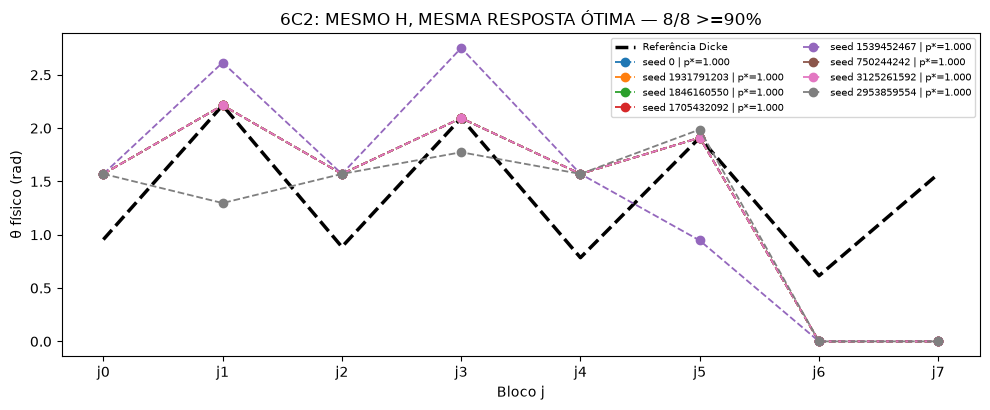

6C2: aprovações 8/8; respostas financeiras ótimas: ['MSFT JPM ']


,seed,p_star,dist_angular_Dicke,dist_angular_primeiro
0,0,1.0,1.56849,0.00000
1,1931791203,1.0,1.56849,0.00000
2,1846160550,1.0,1.56849,0.00000
3,1705432092,1.0,1.56849,0.00000
4,1539452467,1.0,1.68546,0.61694
5,750244242,1.0,1.56849,0.00000
6,3125261592,1.0,1.56849,0.00000
7,2953859554,1.0,1.64239,0.48710


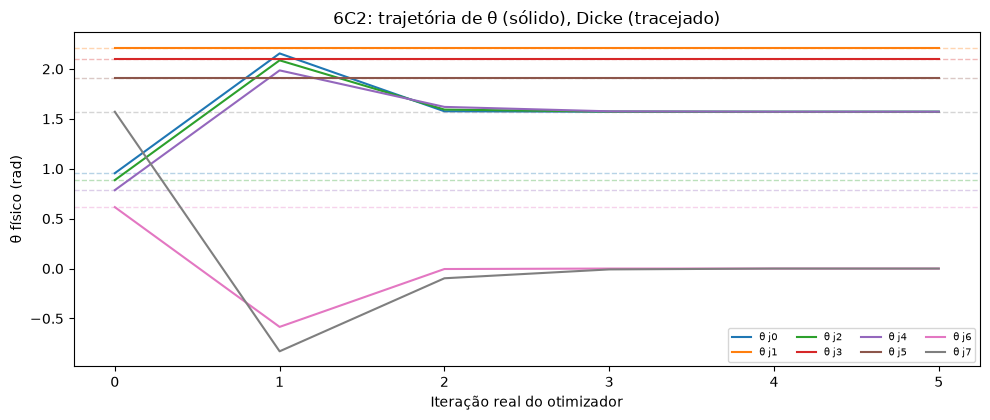

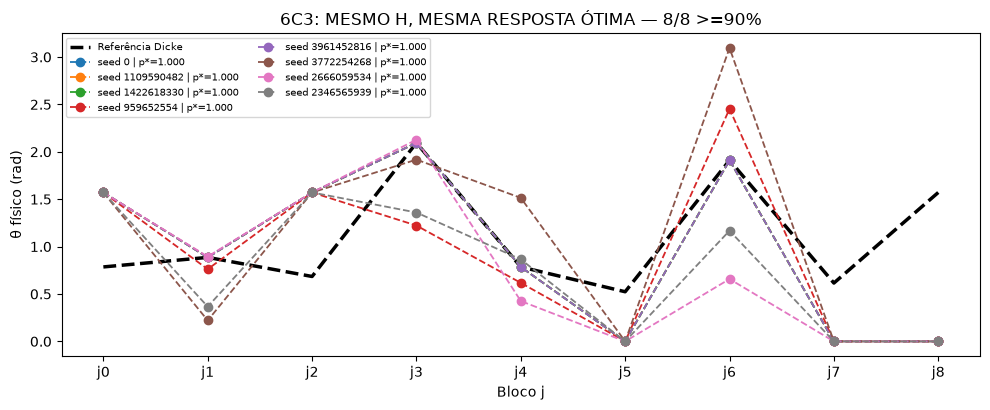

6C3: aprovações 8/8; respostas financeiras ótimas: ['MSFT JPM JNJ ']


,seed,p_star,dist_angular_Dicke,dist_angular_primeiro
0,0,1.0,1.63457,0.00000
1,1109590482,1.0,1.63457,0.00000
2,1422618330,1.0,1.63457,0.00000
3,959652554,1.0,1.72605,0.55449
4,3961452816,1.0,1.63457,0.00000
5,3772254268,1.0,2.00082,1.15390
6,2666059534,1.0,1.78719,0.72267
7,2346565939,1.0,1.79476,0.74118


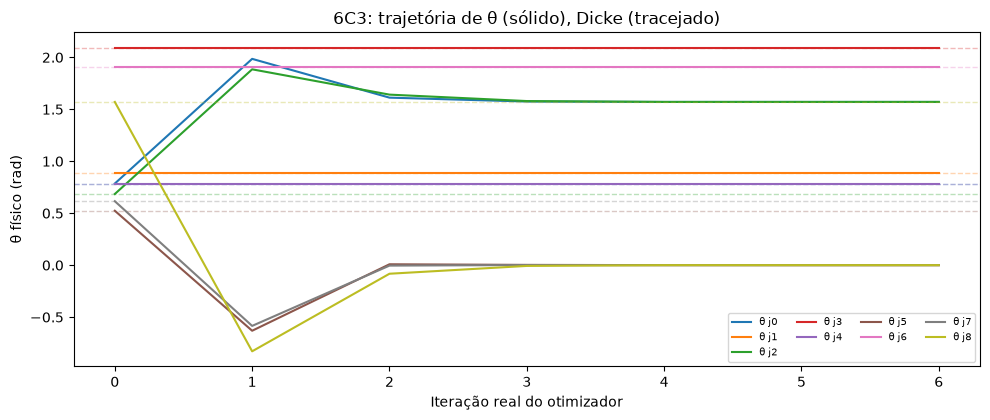

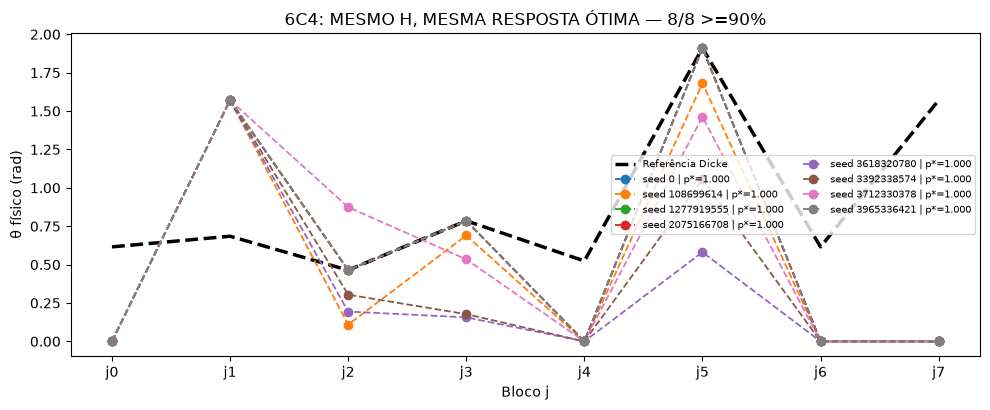

6C4: aprovações 8/8; respostas financeiras ótimas: ['MSFT JPM JNJ PG ']


,seed,p_star,dist_angular_Dicke,dist_angular_primeiro
0,0,1.0,1.56005,0.00000
1,108699614,1.0,1.60673,0.38447
2,1277919555,1.0,1.56005,0.00000
3,2075166708,1.0,1.56005,0.00000
4,3618320780,1.0,1.82865,0.95404
5,3392338574,1.0,1.73541,0.76019
6,3712330378,1.0,1.64798,0.53110
7,3965336421,1.0,1.56005,0.00000


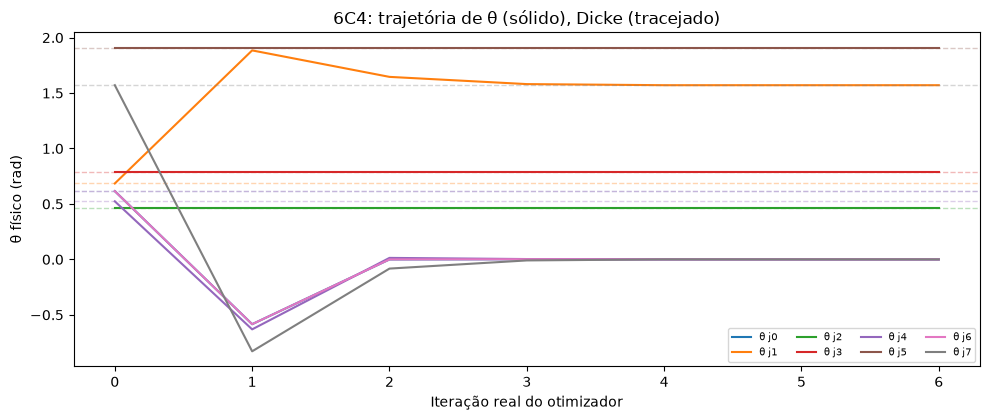

In [10]:
# A10 — Repetições idênticas: mesmo Hamiltoniano e mesmo bitstring ótimo.
G539_REPETICOES_LOG=[]
for k in G539_KS:
    r=g539_instancia(G539_PROBE_DATE,k,G539_ID,'teste_2025_auditoria')
    runs=g539_multistart(r,G539_REPETICOES_IDENTICAS,'repeat_exato',trajectorias=True)
    G539_REPETICOES_LOG+=g539_resumo_targets(runs,r,'mesmo_H_mesma_ordem')
    c=G539_CIRCUITOS[k];x=np.arange(c.g)
    fig,ax=plt.subplots(figsize=(10,4.2))
    ax.plot(x,c.phiD*c.periodo/(2*np.pi),'k--',lw=2.5,label='Referência Dicke')
    good=[]
    for z,res in enumerate(runs):
        if res['accepted']:
            good.append(res)
            ax.plot(x,res['theta'],ls='--',marker='o',lw=1.3,
                    label=f"seed {res['seed']} | p*={res['p_star']:.3f}")
    ax.set(xticks=x,xticklabels=[f'j{j}' for j in x],xlabel='Bloco j',ylabel='θ físico (rad)',
       title=f'6C{k}: MESMO H, MESMA RESPOSTA ÓTIMA — {len(good)}/{len(runs)} >=90%')
    ax.legend(fontsize=7,ncol=2);plt.tight_layout();plt.show()
    print(f'6C{k}: aprovações {len(good)}/{len(runs)}; respostas financeiras ótimas:',r['ref_labels'])
    if len(good)>=2:
        df=pd.DataFrame([dict(seed=z['seed'],p_star=z['p_star'],
             dist_angular_Dicke=float(np.linalg.norm(g539_wrap(z['phi']-c.phiD))),
             dist_angular_primeiro=float(np.linalg.norm(g539_wrap(z['phi']-good[0]['phi']))))
             for z in good])
        display(df.round(5))
    else: print('Número insuficiente de targets aceitos para estimar degenerescência angular.')
    # Trajetória REAL (callback) do primeiro restart, sem interpolação.
    first=runs[0]; trajectory=pd.DataFrame(first['tr'])
    trajectory.to_csv(G539_BASE/f'trajetoria_mesmo_H_6C{k}.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,4.3))
    for j in range(c.g):
        ax.plot(trajectory['iteracao'],trajectory[f'theta_j{j}'],label=f'θ j{j}',lw=1.5)
        ax.axhline(c.phiD[j]*c.periodo[j]/(2*np.pi),color=f'C{j%10}',ls='--',alpha=0.32,lw=1)
    ax.set(xlabel='Iteração real do otimizador',ylabel='θ físico (rad)',
           title=f'6C{k}: trajetória de θ (sólido), Dicke (tracejado)')
    ax.legend(fontsize=7,ncol=4);plt.tight_layout();plt.show()

pd.DataFrame(G539_REPETICOES_LOG).to_csv(G539_BASE/'mesmo_H_multiplas_sementes.csv',index=False)

## A11 — Gráfico pedido: permutar as seis ações, mas preservar $H$ físico

Para cada 6C2/3/4, usamos uma **única data** e uma lista explícita de permutações das mesmas seis séries. Calculamos $P\mu$, $P\Sigma P^\top$, geramos targets e desenhamos as curvas $\theta_j$ aprovadas em **linhas tracejadas**. Também apresentamos um mapa da diferença angular circular em relação ao Dicke. **Comparar o gate $j$ entre permutações não equivale a comparar o mesmo conjunto de ativos**, pois os qubits mudaram de rótulo: reportamos as duas coisas separadamente.

As soluções com $p_*<90\%$ são identificadas como não aprovadas. Não inventamos uma curva aprovada quando o otimizador falhar.

6C2, perm 0: ('AAPL', 'MSFT', 'JPM', 'JNJ', 'XOM', 'PG'): 2/2 >=90%
6C2, perm 1: ('PG', 'JNJ', 'JPM', 'AAPL', 'MSFT', 'XOM'): 1/2 >=90%
6C2, perm 2: ('PG', 'MSFT', 'JNJ', 'JPM', 'AAPL', 'XOM'): 2/2 >=90%
6C2, perm 3: ('JNJ', 'XOM', 'JPM', 'AAPL', 'PG', 'MSFT'): 2/2 >=90%
6C2, perm 4: ('AAPL', 'PG', 'MSFT', 'JPM', 'XOM', 'JNJ'): 2/2 >=90%
6C2, perm 5: ('JNJ', 'AAPL', 'XOM', 'JPM', 'MSFT', 'PG'): 2/2 >=90%
6C2, perm 6: ('AAPL', 'MSFT', 'XOM', 'PG', 'JPM', 'JNJ'): 2/2 >=90%
6C2, perm 7: ('JPM', 'JNJ', 'PG', 'XOM', 'AAPL', 'MSFT'): 2/2 >=90%


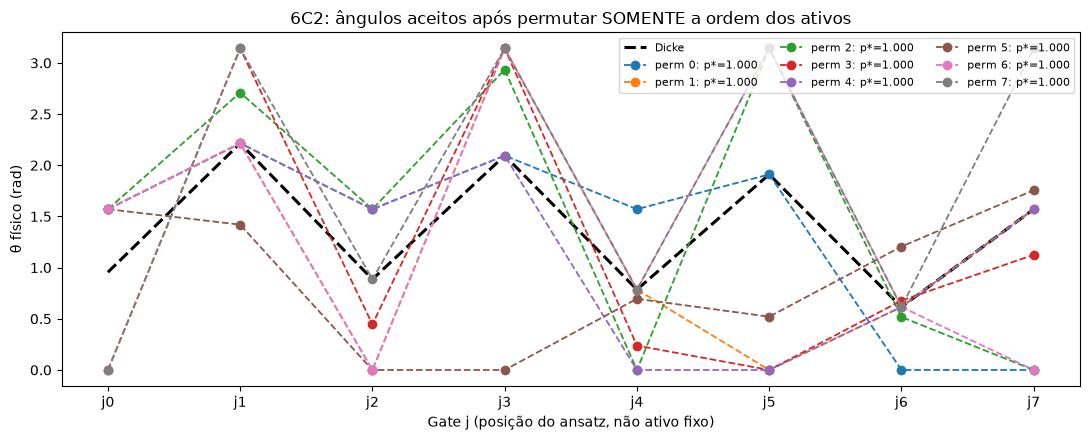

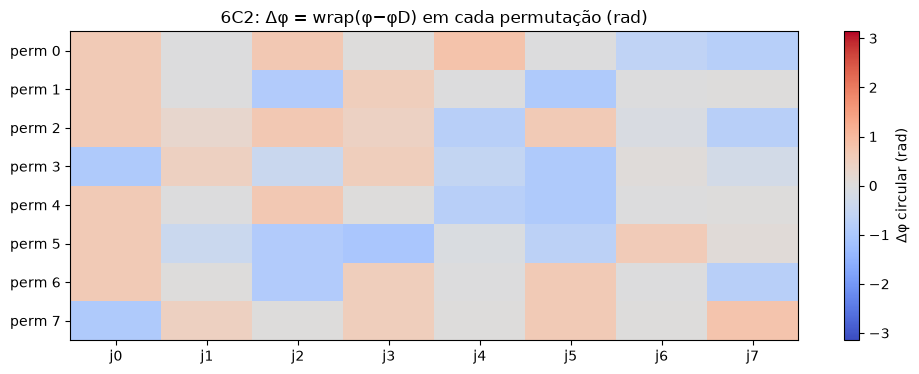

6C3, perm 0: ('AAPL', 'MSFT', 'JPM', 'JNJ', 'XOM', 'PG'): 2/2 >=90%
6C3, perm 1: ('PG', 'JNJ', 'JPM', 'AAPL', 'MSFT', 'XOM'): 2/2 >=90%
6C3, perm 2: ('PG', 'MSFT', 'JNJ', 'JPM', 'AAPL', 'XOM'): 2/2 >=90%
6C3, perm 3: ('JNJ', 'XOM', 'JPM', 'AAPL', 'PG', 'MSFT'): 2/2 >=90%
6C3, perm 4: ('AAPL', 'PG', 'MSFT', 'JPM', 'XOM', 'JNJ'): 1/2 >=90%
6C3, perm 5: ('JNJ', 'AAPL', 'XOM', 'JPM', 'MSFT', 'PG'): 2/2 >=90%
6C3, perm 6: ('AAPL', 'MSFT', 'XOM', 'PG', 'JPM', 'JNJ'): 2/2 >=90%
6C3, perm 7: ('JPM', 'JNJ', 'PG', 'XOM', 'AAPL', 'MSFT'): 1/2 >=90%


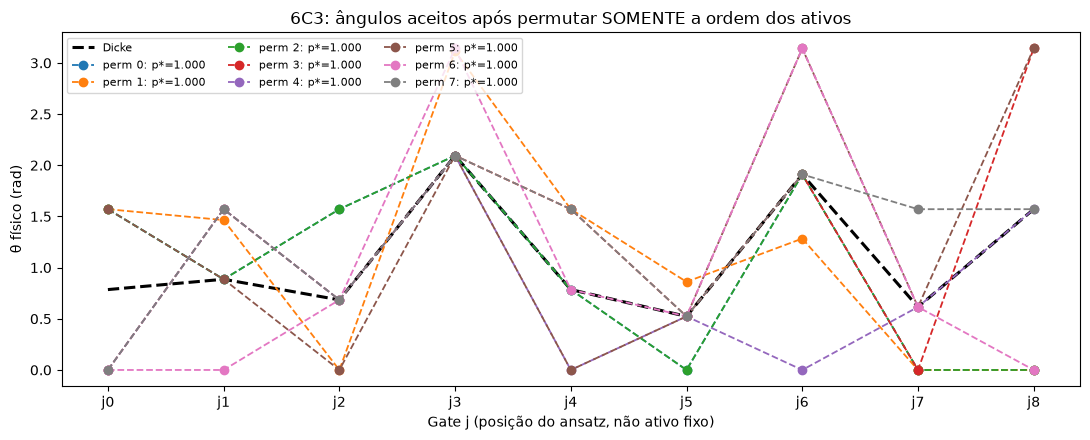

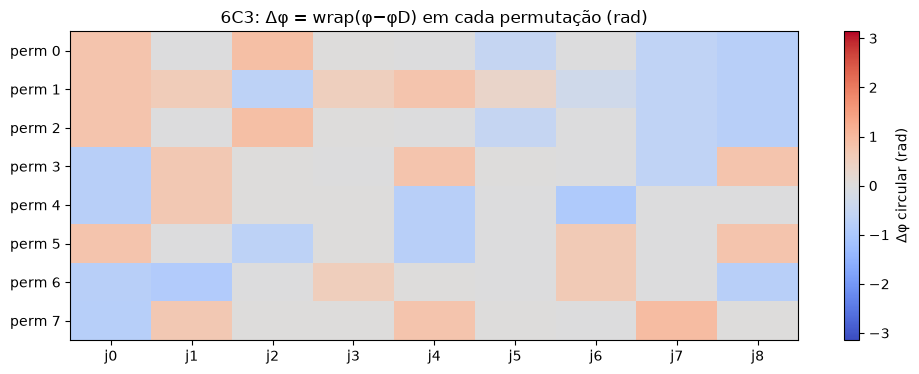

6C4, perm 0: ('AAPL', 'MSFT', 'JPM', 'JNJ', 'XOM', 'PG'): 2/2 >=90%
6C4, perm 1: ('PG', 'JNJ', 'JPM', 'AAPL', 'MSFT', 'XOM'): 2/2 >=90%
6C4, perm 2: ('PG', 'MSFT', 'JNJ', 'JPM', 'AAPL', 'XOM'): 1/2 >=90%
6C4, perm 3: ('JNJ', 'XOM', 'JPM', 'AAPL', 'PG', 'MSFT'): 2/2 >=90%
6C4, perm 4: ('AAPL', 'PG', 'MSFT', 'JPM', 'XOM', 'JNJ'): 2/2 >=90%
6C4, perm 5: ('JNJ', 'AAPL', 'XOM', 'JPM', 'MSFT', 'PG'): 2/2 >=90%
6C4, perm 6: ('AAPL', 'MSFT', 'XOM', 'PG', 'JPM', 'JNJ'): 2/2 >=90%
6C4, perm 7: ('JPM', 'JNJ', 'PG', 'XOM', 'AAPL', 'MSFT'): 2/2 >=90%


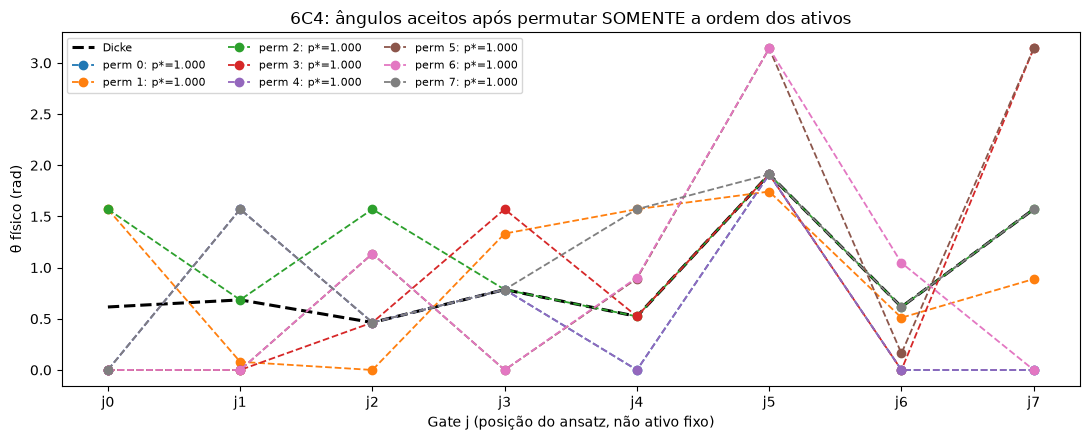

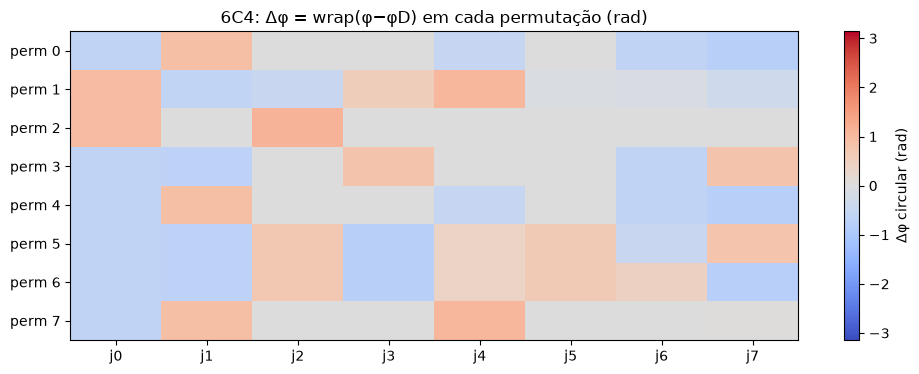

,tentativas,aprovadas,media_pstar
k,,,
2,16,15,0.9565
3,16,14,0.9130
4,16,15,0.9657


In [11]:
# A11 — Permutações reais: nunca substituir o Hamiltoniano por outra amostra de mercado.
G539_PERM_LOG=[]
for k in G539_KS:
    c=G539_CIRCUITOS[k]
    curvas=[]
    for nperm,perm in enumerate(G539_ALL_PERMS[:G539_N_PERMS_GRAFICO]):
        r=g539_instancia(G539_PROBE_DATE,k,perm,'teste_2025_auditoria')
        assert np.isclose(r['E_opt'],g539_instancia(G539_PROBE_DATE,k,G539_ID)['E_opt'])
        runs=g539_multistart(r,G539_PERM_RESTARTS,'permuta_grafico',trajectorias=False)
        G539_PERM_LOG+=g539_resumo_targets(runs,r,'mesmo_H_ordem_permutada')
        good=[v for v in runs if v['accepted']]
        if good:
            best=max(good,key=lambda x:x['p_star'])
            curvas.append((nperm,r,best))
        print(f'6C{k}, perm {nperm}: {r["assets"]}: {len(good)}/{len(runs)} >=90%',flush=True)
    fig,ax=plt.subplots(figsize=(11,4.5));x=np.arange(c.g)
    ax.plot(x,c.phiD*c.periodo/(2*np.pi),'k--',lw=2.2,label='Dicke')
    for i,r,res in curvas:
        ax.plot(x,res['theta'],ls='--',marker='o',lw=1.3,
                label=f'perm {i}: p*={res["p_star"]:.3f}')
    ax.set(xticks=x,xticklabels=[f'j{j}' for j in x],xlabel='Gate j (posição do ansatz, não ativo fixo)',
       ylabel='θ físico (rad)',title=f'6C{k}: ângulos aceitos após permutar SOMENTE a ordem dos ativos')
    ax.legend(fontsize=8,ncol=3);plt.tight_layout();plt.show()
    if curvas:
        delta=np.stack([g539_wrap(res['phi']-c.phiD) for _,_,res in curvas])
        fig,ax=plt.subplots(figsize=(10, max(2.6,len(curvas)*0.48)))
        im=ax.imshow(delta,aspect='auto',vmin=-np.pi,vmax=np.pi,cmap='coolwarm')
        ax.set(xticks=np.arange(c.g),xticklabels=[f'j{i}' for i in range(c.g)],
               yticks=np.arange(len(curvas)),yticklabels=[f'perm {i}' for i,_,_ in curvas],
               title=f'6C{k}: Δφ = wrap(φ−φD) em cada permutação (rad)')
        fig.colorbar(im,ax=ax,label='Δφ circular (rad)');plt.tight_layout();plt.show()
    else:print('Não há targets aprovados nesta topologia; nenhum gráfico de aprovação foi fabricado.')

G539_PERM_DF=pd.DataFrame(G539_PERM_LOG)
G539_PERM_DF.to_csv(G539_BASE/'permutacoes_angulos_todas_tentativas.csv',index=False)
display(G539_PERM_DF.groupby('k').agg(tentativas=('accepted','size'),aprovadas=('accepted','sum'),
                                        media_pstar=('p_star','mean')).round(4))

## A12 — Decisão sobre redução de atributos e redução dos tokens de atenção

O comparativo 23D/18D/15D testa redução de **features**; `23D_group2` testa redução de **tokens processados na autoatenção** (8→4 para 6C2/6C4, 9→5 para 6C3). Nos dois casos a saída sempre possui $g$ ângulos e o circuito permanece intacto.

**Critério decisório:** comparar a probabilidade do ótimo e a taxa de $p_*\geq90\%$ na validação de 2024 e nos testes fechados de 2025/2026. Reduzir a dimensão interna ou os tokens pode prejudicar a informação contextual; por isso não reivindicamos ganho antes da execução. A comparação é preliminar porque poucas datas e um único treino por configuração não permitem inferência estatística robusta.

### Auditoria adicional sugerida

É recomendável ampliar posteriormente o número de datas de treino de 2024, usar várias sementes para cada arquitetura, registrar curvas com budgets fixos e comparar com um otimizador **sem oráculo** (energia média ou CVaR) para evitar confundir a qualidade do professor com a capacidade de generalização do Transformer.

In [12]:
# A12 — Sumário final, com um quadro de cobertura dos targets e critérios auditáveis.
G539_RESULTS=[]
for key,model in G539_MODELOS.items():
    G539_RESULTS.append(dict(modelo=key,features=len(G539_FEATURES[key]),
        tokens_atencao_6C2=(8+1)//2 if key.endswith('group2') else 8,
        tokens_atencao_6C3=(9+1)//2 if key.endswith('group2') else 9,
        tokens_atencao_6C4=(8+1)//2 if key.endswith('group2') else 8,
        p_validacao=g539_val_pstar(model,key,G539_VAL),
        p_testes=float(G539_TEST_DF.loc[G539_TEST_DF.modelo==key,'p_star'].mean()),
        pass90_testes=int(G539_TEST_DF.loc[G539_TEST_DF.modelo==key,'passou90'].sum()),
        n_testes=int((G539_TEST_DF.modelo==key).sum())))
G539_SUMARIO=pd.DataFrame(G539_RESULTS).sort_values('p_validacao',ascending=False)
display(G539_SUMARIO.round(4))
G539_SUMARIO.to_csv(G539_BASE/'sumario_ablações.csv',index=False)
with open(G539_BASE/'protocolo_experimental.json','w',encoding='utf-8') as f:
    json.dump({'data_source':G539_ORIGEM,'tickers':G539_TICKERS,'split_dates':G539_DATES,
               'optimization': 'L-BFGS-B teacher oracle pstar, bounded residual +/-1.2',
               'threshold_pstar':G539_THRESHOLD,'maxiter':G539_OPT_MAXITER,
               'restarts':G539_RESTARTS,'epochs':G539_EPOCHS,'seed':G539_SEED,
               'validation_only_checkpoint':True,'tests_never_used_to_fit_weights':True,
               'label_warning':'O alvo usa oracle exato de carteiras pequenas; não confundir com VQE sem oracle'},
              f,ensure_ascii=False,indent=2)
print('Saídas gravadas em:',G539_BASE)
print('Nenhum resultado 2025/2026 foi usado para treino ou escolha de checkpoint.')

,modelo,features,tokens_atencao_6C2,tokens_atencao_6C3,tokens_atencao_6C4,p_validacao,p_testes,pass90_testes,n_testes
1,18D,18,8,9,8,0.3843,0.2691,0,12
0,23D,23,8,9,8,0.3809,0.4383,0,12
2,15D,15,8,9,8,0.3678,0.3556,0,12
3,23D_group2,23,4,5,4,0.2675,0.2518,0,12


Saídas gravadas em: C:\Users\Marlon\Downloads\g539_dicke_6ativos_alvos_23d
Nenhum resultado 2025/2026 foi usado para treino ou escolha de checkpoint.


## A13 — Diagnóstico obrigatório: professor, treinamento neural e generalização

**Não misturar três resultados diferentes:**

1. **Cobertura dos targets:** taxa de tentativas do otimizador professor que atingem $p_*\geq0.90$, e fração de instâncias com pelo menos um target aprovado.
2. **Aprendizado no treino de 2024:** após treinar, a rede deve conseguir reproduzir aproximações úteis de configurações angulares aprovadas; comparar $p_*$, taxa de aprovação e distância aos targets.
3. **Generalização:** nas datas de validação 2024 e de teste 2025–2026, reportar separadamente $p_*$ médio, mediano, mínimo, máximo e a porcentagem de instâncias aprovadas. **A métrica que seleciona os checkpoints é apenas a validação de 2024.** Os testes futuros servem só para auditoria.

O painel abaixo mostrará **por topologia** a diferença entre os ângulos do professor, os ângulos previstos pelo estudante e a referência de Dicke. As curvas tracejadas são referências; soluções diferentes podem representar a mesma carteira ótima, por isso erro angular não equivale necessariamente a erro físico.

**Interpretação dos resultados originalmente salvos:** 194/198 e 59/60 foram **tentativas aprovadas pelo professor**, enquanto os estudantes tiveram **0/12 aprovações nos testes por arquitetura**. O objetivo deste diagnóstico é localizar onde a aprendizagem deixa de reproduzir o professor — não elevar artificialmente o desempenho selecionando resultados de teste.


PROFESSOR — cobertura das tentativas de geração dos targets:


,grupo,k,tentativas,aprovadas,p_mediano,p_min,taxa_pass90
0,treino_2024,2,66,63,1.0,0.3044,0.9545
1,treino_2024,3,66,66,1.0,1.0000,1.0000
2,treino_2024,4,66,65,1.0,0.3044,0.9848
3,validacao_2024,2,20,20,1.0,1.0000,1.0000
4,validacao_2024,3,20,20,1.0,1.0000,1.0000
5,validacao_2024,4,20,19,1.0,0.2427,0.9500


ESTUDANTE — desempenho por topologia e partição temporal:


,modelo,grupo,k,instancias,aprovadas,p_medio,p_mediano,p_min,p_max,taxa_aprovacao
0,15D,teste_2025,2,2,0,0.3449,0.3449,0.2858,0.4040,0.0000
1,15D,teste_2025,3,2,0,0.4550,0.4550,0.2009,0.7090,0.0000
2,15D,teste_2025,4,2,0,0.4671,0.4671,0.1338,0.8004,0.0000
3,15D,teste_2026,2,2,0,0.3338,0.3338,0.0803,0.5873,0.0000
4,15D,teste_2026,3,2,0,0.3112,0.3112,0.1687,0.4536,0.0000
5,15D,teste_2026,4,2,0,0.2219,0.2219,0.0395,0.4043,0.0000
6,15D,treino_2024,2,33,31,0.9639,0.9817,0.7435,0.9993,0.9394
7,15D,treino_2024,3,33,26,0.9118,0.9635,0.1686,0.9984,0.7879
8,15D,treino_2024,4,33,31,0.9730,0.9842,0.8154,0.9954,0.9394
9,15D,validacao_2024,2,10,1,0.4107,0.3612,0.0000,0.9693,0.1000


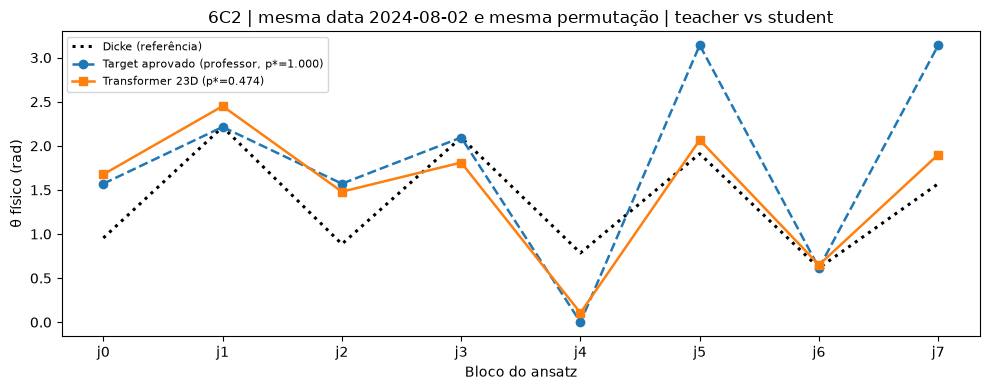

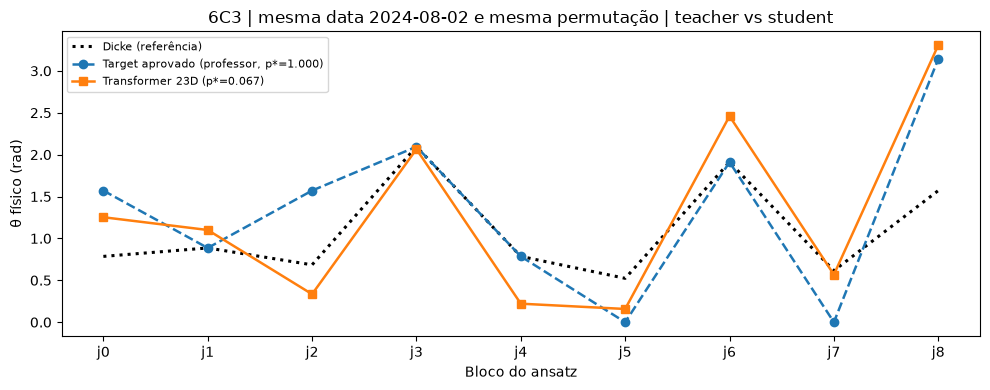

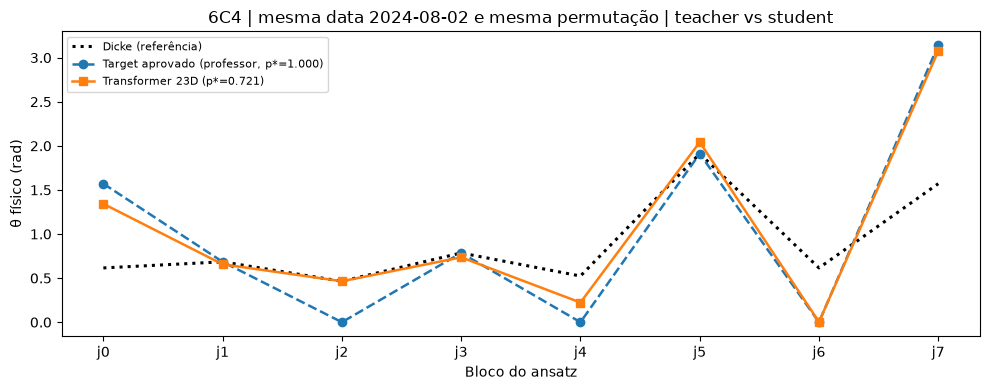

Leitura correta: o professor pode ter targets >=90% e o aluno NÃO atingir 90%.
Nenhum valor de teste foi usado para modificar os pesos do Transformer neste diagnóstico.


In [13]:
# A13 — Painel após executar A1-A12: nenhuma atualização de pesos.
# Distinguir a cobertura do teacher da capacidade de reprodução pelo estudante.
G539_TAXA_TEACHER=(G539_LOG_DF.groupby(['grupo','k'],as_index=False)
    .agg(tentativas=('accepted','size'),aprovadas=('accepted','sum'),
         p_mediano=('p_star','median'),p_min=('p_star','min')))
G539_TAXA_TEACHER['taxa_pass90']=G539_TAXA_TEACHER['aprovadas']/G539_TAXA_TEACHER['tentativas']
print('PROFESSOR — cobertura das tentativas de geração dos targets:')
display(G539_TAXA_TEACHER.round(4))

# Aluno avaliado nos MESMOS Hamiltonianos de treino, validação e teste.
G539_AVALIACOES_DIAGNOSTICO=[]
for key,net in G539_MODELOS.items():
    net.eval()
    with torch.no_grad():
        for grupo,lista in [('treino_2024',G539_TRAIN),('validacao_2024',G539_VAL),
                            ('teste_2025',[r for r in G539_TEST_INSTANCIAS if r['grupo']=='teste_2025']),
                            ('teste_2026',[r for r in G539_TEST_INSTANCIAS if r['grupo']=='teste_2026'])]:
            for r in lista:
                c=G539_CIRCUITOS[r['k']]
                delta=net(g539_input(r,key)).cpu().numpy()
                p_star=float(c.probs(c.phiD+delta)[r['mask_opt']].sum())
                G539_AVALIACOES_DIAGNOSTICO.append({
                    'modelo':key,'grupo':grupo,'data':r['data'],'k':r['k'],
                    'p_star':p_star,'passou90':p_star>=G539_THRESHOLD,
                    'p_dicke':1/math.comb(6,r['k'])})
G539_DIAG_DF=pd.DataFrame(G539_AVALIACOES_DIAGNOSTICO)
G539_DIAG_RESUMO=(G539_DIAG_DF.groupby(['modelo','grupo','k'])
    .agg(instancias=('p_star','size'),aprovadas=('passou90','sum'),
         p_medio=('p_star','mean'),p_mediano=('p_star','median'),
         p_min=('p_star','min'),p_max=('p_star','max'))
    .reset_index())
G539_DIAG_RESUMO['taxa_aprovacao']=G539_DIAG_RESUMO['aprovadas']/G539_DIAG_RESUMO['instancias']
print('ESTUDANTE — desempenho por topologia e partição temporal:')
display(G539_DIAG_RESUMO.round(4))
G539_DIAG_DF.to_csv(G539_BASE/'diagnostico_aluno_por_instancia.csv',index=False)
G539_DIAG_RESUMO.to_csv(G539_BASE/'diagnostico_aluno_agregado.csv',index=False)

# Curvas comparativas: MESMO Hamiltoniano de validação, teacher aprovado vs student 23D.
for k in G539_KS:
    r=next(rr for rr in G539_VAL if rr['k']==k and rr['targets'])
    c=G539_CIRCUITOS[k]
    teacher_delta=r['targets'][0]
    net=G539_MODELOS['23D'].eval()
    with torch.no_grad():
        student_delta=net(g539_input(r,'23D')).cpu().numpy()
    pt=float(c.probs(c.phiD+teacher_delta)[r['mask_opt']].sum())
    ps=float(c.probs(c.phiD+student_delta)[r['mask_opt']].sum())
    theta_d=c.phiD*c.periodo/(2*np.pi)
    theta_t=(c.phiD+teacher_delta)*c.periodo/(2*np.pi)
    theta_s=(c.phiD+student_delta)*c.periodo/(2*np.pi)
    j=np.arange(c.g)
    fig,ax=plt.subplots(figsize=(10,4))
    ax.plot(j,theta_d,'k:',lw=2.2,label='Dicke (referência)')
    ax.plot(j,theta_t,'--o',lw=1.8,label=f'Target aprovado (professor, p*={pt:.3f})')
    ax.plot(j,theta_s,'-s',lw=1.8,label=f'Transformer 23D (p*={ps:.3f})')
    ax.set(xticks=j,xticklabels=[f'j{x}' for x in j],
           xlabel='Bloco do ansatz',ylabel='θ físico (rad)',
           title=f'6C{k} | mesma data {r["data"]} e mesma permutação | teacher vs student')
    ax.legend(fontsize=8);plt.tight_layout();plt.show()

# Relatório agregado sem selecionar pelo teste.
print('Leitura correta: o professor pode ter targets >=90% e o aluno NÃO atingir 90%.')
print('Nenhum valor de teste foi usado para modificar os pesos do Transformer neste diagnóstico.')


## A14 — Hipótese isolada: Hamiltoniano completo e perda no espaço de probabilidades

**Esta seção continua o MESMO G5.38** (A1–A13 preservados, com outputs históricos). **Execução mais econômica:** execute A1–A7 para preparar dados, targets e scalers; pule A8–A13 (resultados históricos); execute A15–A22. A20 reconstrói as instâncias de teste caso A9 não tenha sido executado. **Não altera o treinamento anterior.** Desenvolvemos uma ablação fatorial 2×2 com a mesma arquitetura-base (*d_model*=48, 2 encoders, 4 cabeças, 23 atributos locais por gate), mesmas datas e mesmos targets aprovados:

| Identificador | 23 tokens locais | Contexto global $H=(\mu,\Sigma)$ | Perda de treinamento |
|:--|:--:|:--:|:--|
| `LOC_ANG` | sim | não | distância angular circular ao melhor target |
| `FULL_ANG` | sim | sim | distância angular circular ao melhor target |
| `LOC_PROB` | sim | não | distância entre distribuições quânticas |
| `FULL_PROB` | sim | sim | distância entre distribuições quânticas |

Para $n=6$, o vetor global contém **6 retornos** e **21 elementos independentes** da matriz $\Sigma$ simétrica, totalizando **27 atributos**. Seu normalizador é ajustado **apenas no treino de 2024**, nunca nos dados de validação/teste. A mesma arquitetura possui a projeção global nas quatro configurações: no controle *LOC* sua entrada é zero (controle de capacidade com pesos de mesma forma).

**Perda de distribuição, não de ângulos.** Para cada Hamiltoniano com uma ou mais soluções aprovadas $\phi^{*(m)}$, definimos a distribuição do *teacher* $q_H(x)=\frac1M\sum_m P_{\phi^{*(m)}}(x)$ e a prevista $p_H(x)=P_{\phi_D+f_w(T_H,H)}(x)$. A perda é a distância de Hellinger quadrática:

$$\mathcal L_{\rm prob}(w;H)=1-\sum_{x:|x|=k}\sqrt{p_H(x)\,q_H(x)}\,.$$

Como as distribuições somam 1, a perda é não negativa, é zero quando $p=q$ e não exige que ângulos diferentes sejam iguais. **Não há SPSA e não há execução de Qiskit dentro do `backward()`:** o próprio circuito é simulado de forma diferenciável em PyTorch (somente 6 qubits). Os *teachers*, contudo, ainda foram obtidos com a máscara da carteira ótima enumerada: trata-se de *aprendizado supervisionado com oráculo offline*, não de otimização quantum variacional livre de oráculo.

A seleção de checkpoints usa **somente a validação de 2024**. Os anos 2025–2026 serão consultados apenas depois de congelar cada rede. Nenhum ganho é assumido previamente. *Atenção:* a pequena quantidade de datas distintas, as janelas de retornos sobrepostas e os problemas de identidade permutada permanecem limitações de generalização.

## A15 — Evolução exata e diferenciável do circuito de Dicke em PyTorch

Cada `CX`/`CCX` é uma **permutação fixa dos 64 elementos** do vetor de amplitudes; cada $R_y$ é uma transformação linear em pares de amplitudes. Usamos indexação diferenciável, sem aproximação por shots nem diferenças finitas no treino. Todos os sinais e ordens das portas são preservados conforme `G539Circuito.amplitudes` da etapa A3. Primeiro será obrigatório demonstrar concordância numérica entre os dois simuladores para $6C2$, $6C3$ e $6C4$.

In [14]:
# A15 — Circuito quântico diferenciável (exato, 6 qubits) para perda de distribuição.
# Paridade numérica com o simulador NumPy de A3 será verificada em A16.
class G540TorchCircuit:
    def __init__(self, circuito):
        self.k, self.n, self.g = circuito.k, circuito.n, circuito.g
        self.phiD = torch.tensor(circuito.phiD, dtype=torch.float64)
        self.periodo = torch.tensor(circuito.periodo, dtype=torch.float64)
        self.indices = torch.tensor(circuito.indices, dtype=torch.long)
        self.initial_index = sum(1 << (self.n-1-j) for j in range(self.k))
        base = np.arange(1 << self.n, dtype=np.int64)
        self.ops = []
        for p in circuito.portas:
            i, l = p['i'], p['l']
            def ctrl_map(controls, target):
                mask = np.ones(len(base), dtype=bool)
                for ctl in controls:
                    mask &= ((base >> ctl) & 1).astype(bool)
                # x -> x XOR target quando todos os controles estão ligados
                return torch.tensor(base ^ (mask.astype(np.int64) << target), dtype=torch.long)
            rot_flip = torch.tensor(base ^ (1 << i), dtype=torch.long)
            rot_sign = torch.tensor(np.where(((base >> i) & 1)==0, -1., 1.), dtype=torch.float64)
            self.ops.append(dict(
                cx=ctrl_map([i],l),
                controlled=ctrl_map([l],i) if p['tipo']=='CY' else ctrl_map([l,i+1],i),
                rot_flip=rot_flip, rot_sign=rot_sign,
                angle_factor=0.5 if p['tipo']=='CY' else 1.0))

    def amplitudes_phi(self, phi):
        if phi.ndim != 1 or phi.shape[0] != self.g:
            raise ValueError(f'Esperava {self.g} ângulos; veio {tuple(phi.shape)}')
        # one-hot fixo, independente dos parâmetros. Sem operações in-place na cadeia de autograd.
        state = torch.nn.functional.one_hot(
            torch.tensor(self.initial_index,device=phi.device),
            num_classes=1 << self.n).to(dtype=phi.dtype,device=phi.device)
        for j,op in enumerate(self.ops):
            cx=op['cx'].to(phi.device)
            cc=op['controlled'].to(phi.device)
            flip=op['rot_flip'].to(phi.device)
            sign=op['rot_sign'].to(device=phi.device,dtype=phi.dtype)
            ang=phi[j]*(self.periodo[j].to(device=phi.device,dtype=phi.dtype)/(2*torch.pi))*op['angle_factor']
            # CX(i,l)
            state=state.index_select(0,cx)
            # RY(+ang): |0> -> c|0>+s|1>; |1> -> -s|0>+c|1>
            state=torch.cos(ang/2)*state+torch.sin(ang/2)*sign*state.index_select(0,flip)
            # CX ou CCX controlado
            state=state.index_select(0,cc)
            # RY(-ang)
            state=torch.cos(ang/2)*state-torch.sin(ang/2)*sign*state.index_select(0,flip)
            state=state.index_select(0,cc)
            state=state.index_select(0,cx)
        return state

    def probs_phi(self, phi):
        state=self.amplitudes_phi(phi)
        return state.index_select(0,self.indices.to(phi.device)).square()

    def probs_delta(self, delta):
        ref=self.phiD.to(device=delta.device,dtype=delta.dtype)
        return self.probs_phi(ref+delta)

G540_CIRCUITOS={k:G540TorchCircuit(G539_CIRCUITOS[k]) for k in G539_KS}

## A16 — Auditoria obrigatória: NumPy × PyTorch e gradiente por diferenças centrais

Estes são testes de unidade **sem utilizar dados simulados como resultados de mercado**. Sorteamos apenas ângulos para verificar a implementação do circuito. Conferimos amplitudes, probabilidades, norma, probabilidade uniforme de Dicke, preservação da cardinalidade, diferença central de alta precisão e propagação de gradiente. Se falhar, o treinamento A19 deve ser interrompido.

In [15]:
# A16 — Cada topologia deve reproduzir exatamente a implementação de A3.
G540_AUDITORIAS=[]
for k in G539_KS:
    cnp=G539_CIRCUITOS[k];ctp=G540_CIRCUITOS[k]
    rng=np.random.default_rng(5420+k)
    for tipo,dnp in [('Dicke',np.zeros(cnp.g)),('aleatorio_1',rng.uniform(-.7,.7,cnp.g)),
                     ('aleatorio_2',rng.uniform(-1.,1.,cnp.g))]:
        phi=cnp.phiD+dnp
        ref=cnp.amplitudes(phi)
        ptor=ctp.amplitudes_phi(torch.tensor(phi,dtype=torch.float64)).detach().numpy()
        erro=float(np.max(np.abs(ref-ptor)))
        assert np.allclose(ref,ptor,atol=2e-11,rtol=1e-11), (k,tipo,erro)
        assert abs(np.sum(ptor**2)-1)<1e-10
        G540_AUDITORIAS.append(dict(k=k,teste=tipo,max_erro_amplitudes=erro))

    # Diferença finita serve SOMENTE para auditar o gradiente, nunca para treinar a rede.
    d_np=rng.uniform(-.4,.4,cnp.g)
    delta=torch.tensor(d_np,dtype=torch.float64,requires_grad=True)
    pesos=torch.linspace(0.1,1.0,len(cnp.indices),dtype=torch.float64)
    loss=(ctp.probs_delta(delta)*pesos).sum()
    grad=torch.autograd.grad(loss,delta)[0].detach().numpy()
    eps=1e-6
    j=1
    dp=d_np.copy();dm=d_np.copy();dp[j]+=eps;dm[j]-=eps
    fd=float(np.dot(cnp.probs(cnp.phiD+dp)-cnp.probs(cnp.phiD+dm),pesos.numpy())/(2*eps))
    assert np.isclose(grad[j],fd,rtol=3e-4,atol=3e-7), (k,grad[j],fd)
    G540_AUDITORIAS.append(dict(k=k,teste='autograd_vs_diferencas',max_erro_amplitudes=abs(grad[j]-fd)))

G540_AUDITORIA_DF=pd.DataFrame(G540_AUDITORIAS)
display(G540_AUDITORIA_DF)
print('A16 OK: amplitudes, norma, Dicke e gradientes PyTorch concordam com o simulador original.')

,k,teste,max_erro_amplitudes
0,2,Dicke,0.000000e+00
1,2,aleatorio_1,2.775558e-16
2,2,aleatorio_2,1.110223e-16
3,2,autograd_vs_diferencas,1.410492e-10
4,3,Dicke,0.000000e+00
5,3,aleatorio_1,1.110223e-16
6,3,aleatorio_2,0.000000e+00
7,3,autograd_vs_diferencas,7.044326e-11
8,4,Dicke,0.000000e+00
9,4,aleatorio_1,3.330669e-16


A16 OK: amplitudes, norma, Dicke e gradientes PyTorch concordam com o simulador original.


## A17 — Contexto global completo ($6\mu+21\Sigma$), normalizado apenas em 2024/treino

A representação local **permanece 23D por bloco**. Somamos ao embedding de cada token um vetor global de tamanho 48 projetado a partir dos 27 atributos do Hamiltoniano. Este contexto pode levar informações de covariâncias **não presentes em nenhum token**. A permutação dos ativos é respeitada: o global é construído a partir da mesma ordem de $\mu,\Sigma$ já usada em `g539_tokens(r)`.

O `LOC` recebe vetor global zerado e o `FULL` recebe o Hamiltoniano completo padronizado; ambos usam a **mesma classe e número de parâmetros**, ajudando a isolar o efeito da informação adicional. O vetor global não inclui $p_*$, a máscara de ótimo nem os ângulos de referência.

In [16]:
# A17 — 6 retornos + 21 entradas superiores da covariância simétrica = 27 números.
G540_TRI=np.triu_indices(G539_N)
G540_GLOBAL_COLUNAS=[f'mu_{j}' for j in range(G539_N)]+[
    f'Sigma_{i}_{j}' for i,j in zip(*G540_TRI)]
assert len(G540_GLOBAL_COLUNAS)==27

def g540_h_global(r):
    mu=np.asarray(r['mu'],dtype=np.float64)
    sigma=np.asarray(r['Sigma'],dtype=np.float64)
    assert mu.shape==(6,) and sigma.shape==(6,6)
    assert np.allclose(sigma,sigma.T,atol=1e-10)
    out=np.concatenate([mu,sigma[G540_TRI]]).astype(np.float32)
    assert out.shape==(27,) and np.isfinite(out).all()
    return out

G540_H_TRAIN=np.stack([g540_h_global(r) for r in G539_TRAIN])
G540_H_MEAN=G540_H_TRAIN.mean(axis=0)
G540_H_STD=np.maximum(G540_H_TRAIN.std(axis=0),1e-5)
G540_H_SCALER=G539_BASE/'scaler_hamiltoniano_27_train2024.npz'
np.savez(G540_H_SCALER,mean=G540_H_MEAN,std=G540_H_STD,
         nomes=np.asarray(G540_GLOBAL_COLUNAS))

def g540_h_input(r,usar_global=True):
    if not usar_global:
        return torch.zeros(27,dtype=torch.float32)
    x=np.clip((g540_h_global(r)-G540_H_MEAN)/G540_H_STD,-10.,10.)
    return torch.tensor(x,dtype=torch.float32)

for k in G539_KS:
    r=next(r for r in G539_TRAIN if r['k']==k)
    assert g540_h_input(r,True).shape==(27,)
    assert g540_h_input(r,False).abs().sum()==0
    # reconstrução exata da matriz a partir dos 21 elementos independentes
    s=np.zeros((6,6));s[G540_TRI]=g540_h_global(r)[6:]
    s[(G540_TRI[1],G540_TRI[0])]=s[G540_TRI]
    assert np.allclose(s,r['Sigma'],rtol=1e-6,atol=1e-7)
print('A17 OK: H completo (27D), simétrico; scaler treinado sem vazamento temporal.')

A17 OK: H completo (27D), simétrico; scaler treinado sem vazamento temporal.


## A18 — Arquitetura idêntica nas quatro condições e duas perdas distintas

O encoder usa **exatamente 48 dimensões, 2 camadas, 4 cabeças e FFN=96** em todos os braços. A nova camada `global_proj` parte de zeros para que o modelo com $H$ completo comece como o controle local; ela aprende somente quando recebe o vetor global. A saída continua **um $\Delta\phi_j$ por token**, limitada por `RHO=1,2`.

As perdas são aplicadas à **mesma saída angular**, diferindo somente no espaço onde ocorre a comparação:

**A)** distância circular aos vetores de referência (A7); **B)** Hellinger entre as distribuições $P(\phi_D+\Delta\phi)$ e $P(\phi_D+\Delta\phi^*)$. Nenhum cálculo de $p_*$ entra diretamente na função de perda de probabilidade; o oráculo é usado somente na construção dos targets e nas avaliações.

In [17]:
# A18 — Mesma capacidade nominal nos braços LOC/FULL, só muda o vetor de contexto.
class G540Transformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed=nn.Sequential(nn.Linear(23,48),nn.LayerNorm(48))
        self.global_proj=nn.Linear(27,48,bias=False)
        nn.init.zeros_(self.global_proj.weight)
        self.fusion_norm=nn.LayerNorm(48)
        layer=nn.TransformerEncoderLayer(d_model=48,nhead=4,dim_feedforward=96,
                                         dropout=0.,activation='gelu',batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        self.angle=nn.Linear(48,1)
        nn.init.zeros_(self.angle.weight);nn.init.zeros_(self.angle.bias)
    def forward(self,tokens,global_h):
        if tokens.ndim!=2 or tokens.shape[1]!=23 or global_h.shape!=(27,):
            raise ValueError(f'Esperado tokens=(g,23), H=(27,); recebido {tokens.shape}, {global_h.shape}')
        h=self.fusion_norm(self.embed(tokens)+self.global_proj(global_h).unsqueeze(0))
        z=self.encoder(h.unsqueeze(0)).squeeze(0)
        return G539_RHO*torch.tanh(self.angle(z).squeeze(-1))

def g540_q_teacher(r):
    if not r.get('targets'):
        raise ValueError('Instância sem target aprovado: não fabricar distribuição teacher.')
    c=G539_CIRCUITOS[r['k']]
    pq=np.stack([c.probs(c.phiD+d) for d in r['targets']],axis=0)
    q=pq.mean(axis=0)
    assert abs(q.sum()-1)<1e-9 and np.all(q>=-1e-12)
    return torch.tensor(q,dtype=torch.float32)

def g540_loss_distribution(delta,r):
    prob=G540_CIRCUITOS[r['k']].probs_delta(delta)
    q=g540_q_teacher(r).to(device=prob.device,dtype=prob.dtype)
    # Fidelidade clássica (Bhattacharyya), Hellinger^2=1-sum sqrt(p*q)
    # torch.clamp previne sqrt em negativos por erros numéricos residuais.
    bc=torch.sqrt(torch.clamp(prob,min=1e-12)*torch.clamp(q,min=1e-12)).sum()
    return torch.clamp(1.-bc,min=0.)

G540_VARIANTES={
    'LOC_ANG':dict(global_h=False,loss='angular'),
    'FULL_ANG':dict(global_h=True,loss='angular'),
    'LOC_PROB':dict(global_h=False,loss='probabilidade'),
    'FULL_PROB':dict(global_h=True,loss='probabilidade'),
}

# Testes de unidade: mesma dimensionalidade, saída zero=Dicke, gradientes finitos.
for chave,cfg in G540_VARIANTES.items():
    torch.manual_seed(20261022)
    m=G540Transformer()
    r=G539_TRAIN[0]
    d=m(g539_input(r,'23D'),g540_h_input(r,cfg['global_h']))
    assert d.shape==(r['k']*(6-r['k']),) and torch.all(d==0)
    loss=(g539_loss_multiple(d,r['targets']) if cfg['loss']=='angular'
          else g540_loss_distribution(d,r))
    assert torch.isfinite(loss)
    loss.backward()
    assert m.angle.weight.grad is not None and torch.isfinite(m.angle.weight.grad).all()
print('A18 OK: todas as perdas diferenciáveis; início em Dicke; mesma arquitetura nas quatro condições.')

A18 OK: todas as perdas diferenciáveis; início em Dicke; mesma arquitetura nas quatro condições.


## A19 — Treinamento pareado dos quatro braços, sem SPSA

Todos os experimentos utilizam os **mesmos exemplos 2024**, `G539_LR`, `G539_EPOCHS`, a mesma ordem de instâncias por época e a mesma semente para pesos iniciais. A diferença de perdas produz atualizações diferentes, como desejado. Um *checkpoint* é selecionado **somente pelo $p_*$ médio de validação de 2024**, com desempate implícito pela primeira época. Isso usa a enumeração em validação; não é uma perda sem oráculo em todo o protocolo.

O ciclo avalia circuitos PyTorch apenas para o braço probabilístico, mas **não chama SciPy, Qiskit ou SPSA no `backward()`**. A avaliação $p_*$ é feita depois de cada época com NumPy e não produz gradientes.

In [18]:
# A19 — Treinamento completo 2x2 no computador local; ajuste épocas se necessário.
G540_EPOCHS=G539_EPOCHS
G540_TREINAR=True
G540_REDUTOR_TESTE=None  # None usa TODAS as instâncias reais; inteiro só para depuração, não ciência
G540_MODELOS={}
G540_HIST=[]
G540_INICIAIS={}

def g540_val_pstar(model,global_h,instancias):
    model.eval();resultado=[]
    with torch.no_grad():
        for r in instancias:
            d=model(g539_input(r,'23D'),g540_h_input(r,global_h)).cpu().numpy()
            c=G539_CIRCUITOS[r['k']]
            resultado.append(float(c.probs(c.phiD+d)[r['mask_opt']].sum()))
    return float(np.mean(resultado)) if resultado else np.nan

if G540_TREINAR:
    exemplo_treino=(G539_TRAIN if G540_REDUTOR_TESTE is None else G539_TRAIN[:G540_REDUTOR_TESTE])
    for chave,cfg in G540_VARIANTES.items():
        torch.manual_seed(20261022)
        net=G540Transformer()
        # Hash apenas para auditar que todos os braços partem dos mesmos pesos.
        inicial=torch.cat([p.detach().flatten() for p in net.parameters()]).cpu().numpy()
        G540_INICIAIS[chave]=hashlib.sha256(inicial.tobytes()).hexdigest()
        opt=torch.optim.AdamW(net.parameters(),lr=G539_LR,weight_decay=1e-4)
        rng=np.random.default_rng(G539_SEED)
        best_score=-float('inf');best_state=None;best_epoca=0
        for epoca in range(1,G540_EPOCHS+1):
            net.train();losses=[]
            for idx in rng.permutation(len(exemplo_treino)):
                r=exemplo_treino[int(idx)]
                delta=net(g539_input(r,'23D'),g540_h_input(r,cfg['global_h']))
                if cfg['loss']=='angular':
                    loss=g539_loss_multiple(delta,r['targets'])
                else:
                    loss=g540_loss_distribution(delta,r)
                opt.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(net.parameters(),1.)
                opt.step()
                losses.append(float(loss.detach().item()))
            val=g540_val_pstar(net,cfg['global_h'],G539_VAL)
            G540_HIST.append(dict(modelo=chave,epoca=epoca,loss_treino=float(np.mean(losses)),p_val2024=val))
            if val>best_score+1e-12:
                best_score,best_epoca,best_state=val,epoca,copy.deepcopy(net.state_dict())
            if epoca==1 or epoca%5==0 or epoca==G540_EPOCHS:
                print(f'{chave} época {epoca:02d}/{G540_EPOCHS}: loss={np.mean(losses):.5f}, '
                      f'p*(val 2024)={val:.4f}',flush=True)
        net.load_state_dict(best_state);net.eval()
        G540_MODELOS[chave]=net
        caminho=G539_BASE/f'G540_{chave}_checkpoint_treino2024.pt'
        torch.save(dict(arquitetura='G540Transformer',variante=chave,
                        checkpoint_epoca=best_epoca,melhor_p_val2024=best_score,
                        state_dict=best_state,features=G539_COLUNAS,
                        global_columns=G540_GLOBAL_COLUNAS),caminho)
        print(f'FINAL {chave}: melhor época {best_epoca}, p*(val)={best_score:.4f}',flush=True)
    assert len(set(G540_INICIAIS.values()))==1, 'Os quatro braços não partiram dos mesmos pesos!'
    G540_HISTORY_DF=pd.DataFrame(G540_HIST)
    G540_HISTORY_DF.to_csv(G539_BASE/'G540_ablation_treino_curvas.csv',index=False)
    print('Hashes de inicialização idênticos: OK')

LOC_ANG época 01/35: loss=0.22369, p*(val 2024)=0.1552
LOC_ANG época 05/35: loss=0.12000, p*(val 2024)=0.1798
LOC_ANG época 10/35: loss=0.07245, p*(val 2024)=0.2692
LOC_ANG época 15/35: loss=0.04742, p*(val 2024)=0.2290
LOC_ANG época 20/35: loss=0.03033, p*(val 2024)=0.2098
LOC_ANG época 25/35: loss=0.01600, p*(val 2024)=0.2404
LOC_ANG época 30/35: loss=0.00940, p*(val 2024)=0.2158
LOC_ANG época 35/35: loss=0.01218, p*(val 2024)=0.2126
FINAL LOC_ANG: melhor época 12, p*(val)=0.2938
FULL_ANG época 01/35: loss=0.22448, p*(val 2024)=0.1462
FULL_ANG época 05/35: loss=0.11161, p*(val 2024)=0.1757
FULL_ANG época 10/35: loss=0.05903, p*(val 2024)=0.2058
FULL_ANG época 15/35: loss=0.03096, p*(val 2024)=0.2163
FULL_ANG época 20/35: loss=0.02081, p*(val 2024)=0.1942
FULL_ANG época 25/35: loss=0.01070, p*(val 2024)=0.1954
FULL_ANG época 30/35: loss=0.00648, p*(val 2024)=0.1891
FULL_ANG época 35/35: loss=0.01774, p*(val 2024)=0.1859
FINAL FULL_ANG: melhor época 12, p*(val)=0.2847
LOC_PROB época 01

## A20 — Avaliação estritamente após congelar: probabilidades, energia e desempenho por data

Avaliamos exatamente as mesmas instâncias dos modelos históricos, sem permutações adicionais ou seleção pelo teste. São relatados: $p_*$, aprovação de $90\%$, energia esperada $\mathbb E_H[E]=\sum_x p(x)E_H(x)$, probabilidades de Dicke e **fidelidade da distribuição à melhor referência de validação**. Para teste 2025/2026, **não calculamos novos targets**; por isso a distância a targets só é computada onde já existem (treino e validação). Cuidado: bons resultados em 12 instâncias retrospectivas não demonstram generalização ampla.

In [19]:
# A20 — NUNCA usar 2025/2026 para escolha de checkpoint nem de hiperparâmetros.
# Independe de executar A8-A13: recria exatamente as instâncias do antigo A9 quando necessário.
if 'G539_TEST_INSTANCIAS' in globals() and G539_TEST_INSTANCIAS:
    G540_TEST_INSTANCIAS=list(G539_TEST_INSTANCIAS)
else:
    G540_TEST_INSTANCIAS=[]
    for split in ('teste_2025','teste_2026'):
        for date in G539_DATES[split]:
            for k in G539_KS:
                r=g539_instancia(date,k,tuple(range(G539_N)),split)
                r['tokens']=g539_tokens(r)
                G540_TEST_INSTANCIAS.append(r)
if not G540_MODELOS:
    raise RuntimeError('Execute A19 primeiro. Não há rede G540 treinada para avaliar.')
G540_AVALIACOES=[]
for chave,cfg in G540_VARIANTES.items():
    net=G540_MODELOS[chave].eval()
    with torch.no_grad():
        for grupo,grupo_r in [('treino_2024',G539_TRAIN),('validacao_2024',G539_VAL),
                              ('teste_2025',[r for r in G540_TEST_INSTANCIAS if r['grupo']=='teste_2025']),
                              ('teste_2026',[r for r in G540_TEST_INSTANCIAS if r['grupo']=='teste_2026'])]:
            for r in grupo_r:
                pred=net(g539_input(r,'23D'),g540_h_input(r,cfg['global_h'])).cpu().numpy()
                c=G539_CIRCUITOS[r['k']]
                p=c.probs(c.phiD+pred)
                pstar=float(p[r['mask_opt']].sum())
                e=float(p@r['E'])
                if r.get('targets'):
                    q=g540_q_teacher(r).numpy()
                    hell=float(max(0.,1.-np.sqrt(np.maximum(p,0)*np.maximum(q,0)).sum()))
                else:hell=float('nan')
                G540_AVALIACOES.append(dict(modelo=chave,grupo=grupo,data=r['data'],k=r['k'],
                  perm='-'.join(map(str,r['perm'])),p_star=pstar,passou90=bool(pstar>=G539_THRESHOLD),
                  energia_esperada=e,excesso_energia=e-r['E_opt'],
                  hellinger2_vs_teacher=hell,baseline_dicke=1/math.comb(6,r['k'])))

G540_AVALIACOES_DF=pd.DataFrame(G540_AVALIACOES)
G540_RESUMO=(G540_AVALIACOES_DF.groupby(['modelo','grupo','k'])
             .agg(n=('p_star','size'),hits90=('passou90','sum'),
                  p_medio=('p_star','mean'),p_min=('p_star','min'),
                  e_excesso_medio=('excesso_energia','mean'),
                  Hellinger2=('hellinger2_vs_teacher','mean')).reset_index())
G540_RESUMO['taxa90']=G540_RESUMO['hits90']/G540_RESUMO['n']
G540_AVALIACOES_DF.to_csv(G539_BASE/'G540_ablation_todos_resultados.csv',index=False)
G540_RESUMO.to_csv(G539_BASE/'G540_ablation_resumo_k_split.csv',index=False)
print('Resumo geral por split, comparação controlada:')
display(G540_AVALIACOES_DF.groupby(['modelo','grupo']).agg(
    instancias=('p_star','size'),aprovadas=('passou90','sum'),p_medio=('p_star','mean'),
    energia_excesso=('excesso_energia','mean')).round(4))
print('Detalhamento separado por topologia:')
display(G540_RESUMO.round(4))
print('Datas futuras — nenhum target produzido e nenhum checkpoint selecionado no teste:')
display(G540_AVALIACOES_DF[G540_AVALIACOES_DF['grupo'].str.startswith('teste')]
  .pivot_table(index=['grupo','data','k'],columns='modelo',values='p_star').round(4))

Resumo geral por split, comparação controlada:


instancias  aprovadas  p_medio  energia_excesso
modelo    grupo                                                          
FULL_ANG  teste_2025               6          0   0.3049           0.5228
          teste_2026               6          0   0.1446           0.5433
          treino_2024             99         71   0.8747           0.0478
          validacao_2024          30          0   0.2847           0.2325
FULL_PROB teste_2025               6          2   0.4137           0.3571
          teste_2026               6          2   0.4326           0.1385
          treino_2024             99         91   0.9255           0.0094
          validacao_2024          30         10   0.5011           0.0767
LOC_ANG   teste_2025               6          0   0.3665           0.4261
          teste_2026               6          0   0.2611           0.4806
          treino_2024             99         69   0.8571           0.0459
          validacao_2024          30          0   0.2938           0.1715
LOC_PROB  teste_2025               6          2   0.4313           0.4013
          teste_2026               6          1   0.4503           0.2389
          treino_2024             99         85   0.8555           0.0182
          validacao_2024          30         15   0.5537           0.0302

Detalhamento separado por topologia:


,modelo,grupo,k,n,hits90,p_medio,p_min,e_excesso_medio,Hellinger2,taxa90
0,FULL_ANG,teste_2025,2,2,0,0.1405,0.1092,0.4970,NaN,0.0000
1,FULL_ANG,teste_2025,3,2,0,0.3675,0.2395,0.5560,NaN,0.0000
2,FULL_ANG,teste_2025,4,2,0,0.4066,0.3181,0.5155,NaN,0.0000
3,FULL_ANG,teste_2026,2,2,0,0.1186,0.1001,0.4933,NaN,0.0000
4,FULL_ANG,teste_2026,3,2,0,0.2130,0.0722,0.5842,NaN,0.0000
5,FULL_ANG,teste_2026,4,2,0,0.1022,0.0842,0.5523,NaN,0.0000
6,FULL_ANG,treino_2024,2,33,25,0.8976,0.4024,0.0491,0.0577,0.7576
7,FULL_ANG,treino_2024,3,33,23,0.8408,0.1155,0.0512,0.0992,0.6970
8,FULL_ANG,treino_2024,4,33,23,0.8858,0.3467,0.0431,0.0637,0.6970
9,FULL_ANG,validacao_2024,2,10,0,0.3458,0.0110,0.1861,0.4597,0.0000


Datas futuras — nenhum target produzido e nenhum checkpoint selecionado no teste:


modelo                   FULL_ANG  FULL_PROB  LOC_ANG  LOC_PROB
grupo      data       k                                        
teste_2025 2025-06-30 2    0.1719     0.1447   0.4836    0.1790
                      3    0.2395     0.1672   0.1091    0.0100
                      4    0.3181     0.0308   0.1369    0.3697
           2025-12-30 2    0.1092     0.2009   0.0264    0.9951
                      3    0.4955     0.9687   0.6334    0.0741
                      4    0.4950     0.9698   0.8094    0.9598
teste_2026 2026-06-30 2    0.1372     0.5217   0.0472    0.0077
                      3    0.0722     0.1052   0.2070    0.0000
                      4    0.0842     0.0643   0.5382    0.7994
           2026-09-30 2    0.1001     0.9689   0.4879    0.9955
                      3    0.3539     0.9115   0.1753    0.8988
                      4    0.1202     0.0243   0.1110    0.0002

## A21 — Gráficos solicitados: convergência, ângulos tracejados e probabilidades da mesma resposta

O painel compara **cada modelo no mesmo Hamiltoniano** e no mesmo ansatz. No gráfico angular, linhas tracejadas distinguem diferentes modelos e as soluções de referência. Diferenças grandes entre ângulos **não implicam** diferenças grandes entre distribuições — este é precisamente o teste da não unicidade. Para uma leitura mais direta, o segundo gráfico mostra toda a distribuição sobre os $\binom6k$ bitstrings, sem colapsar a análise em $p_*$.

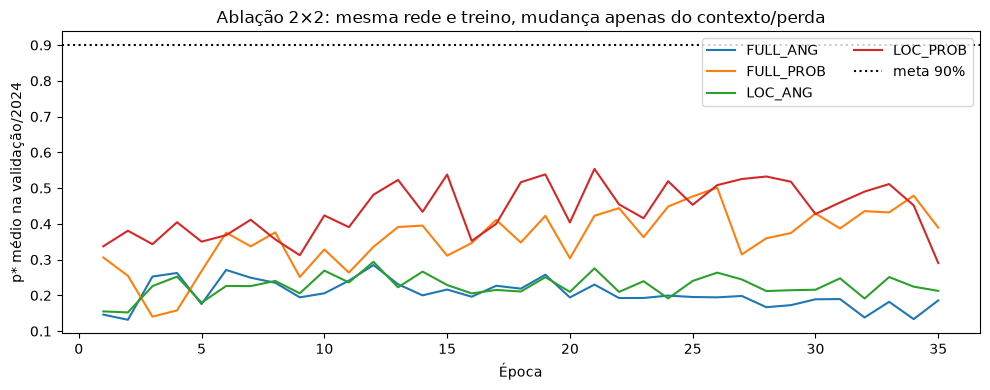

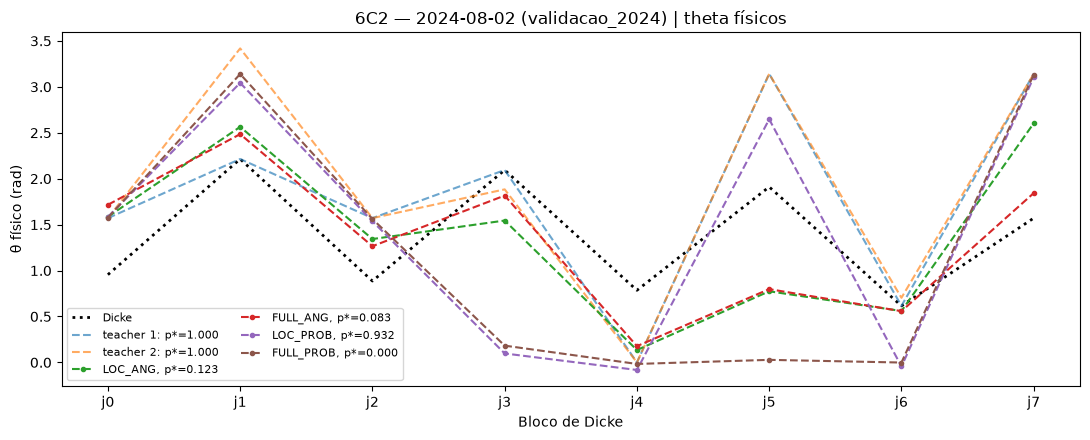

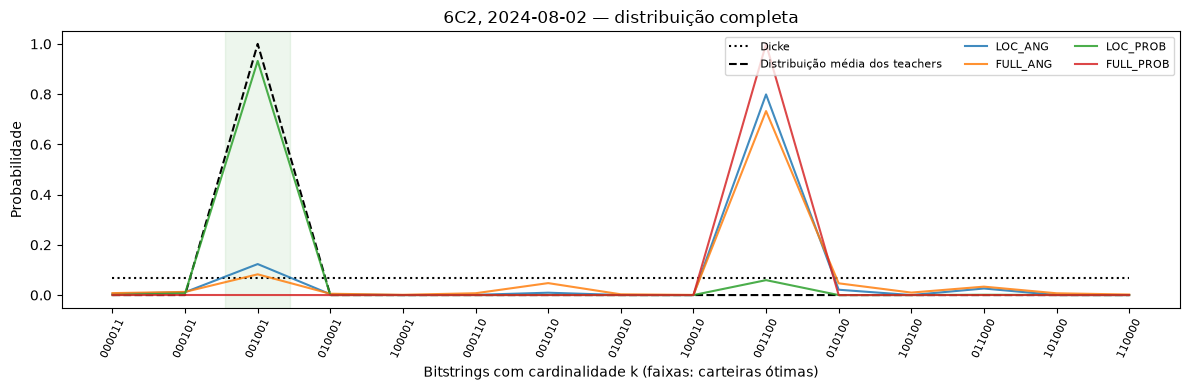

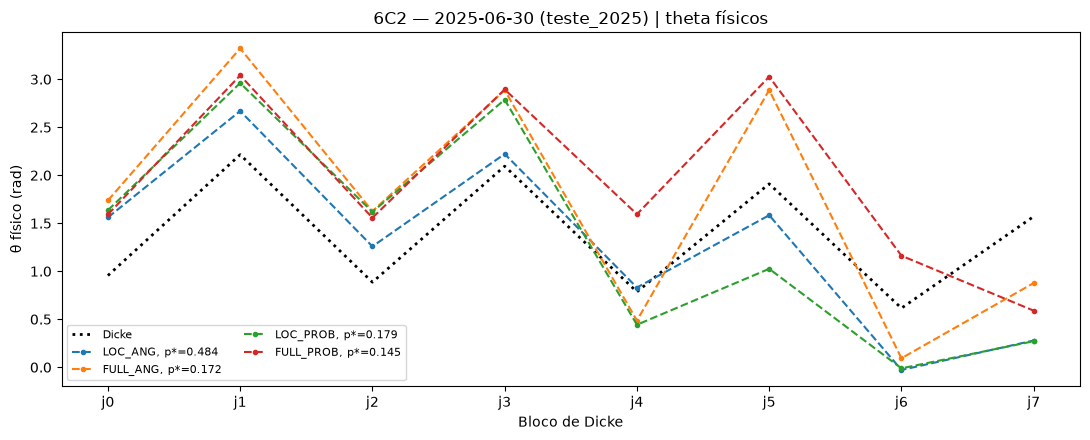

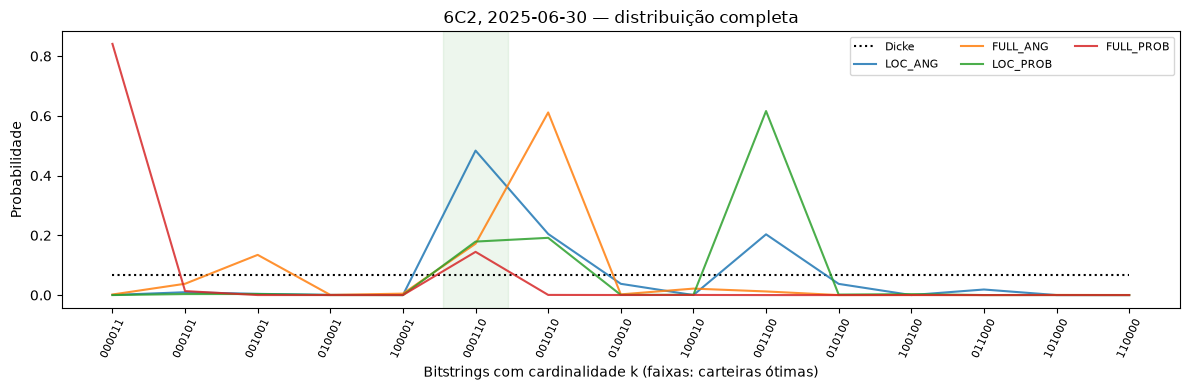

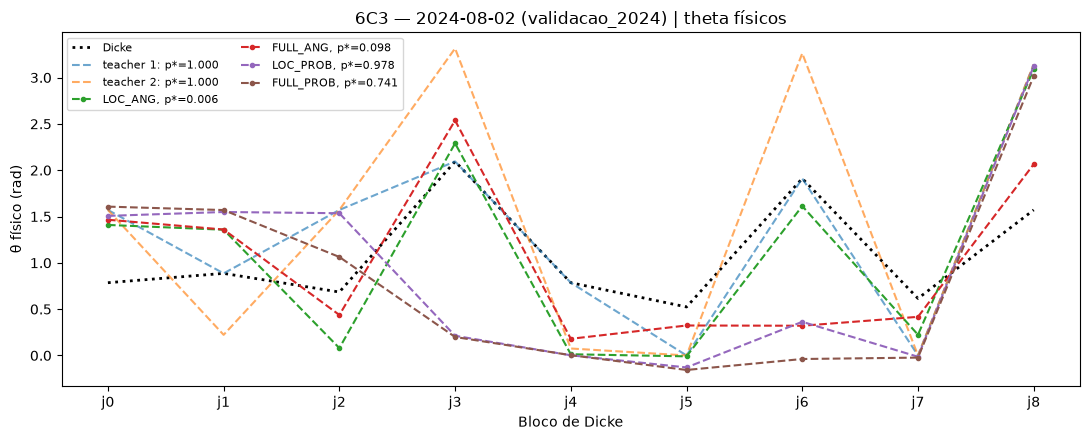

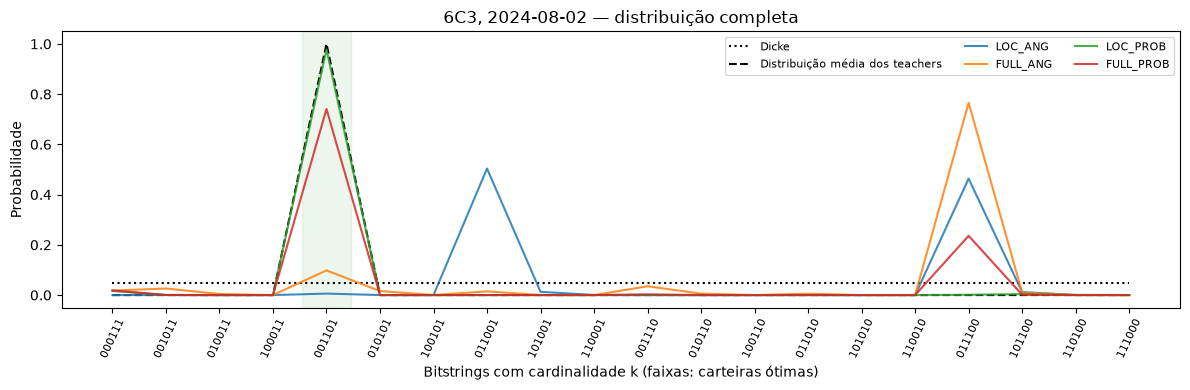

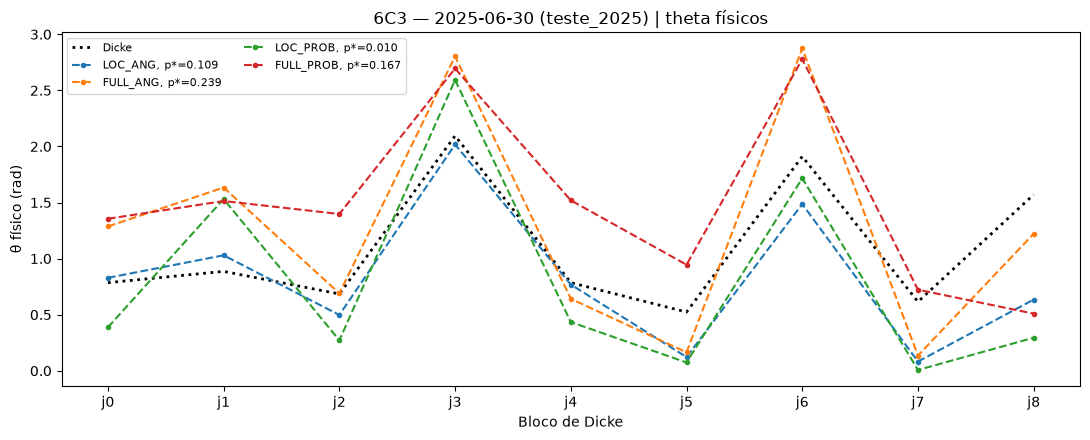

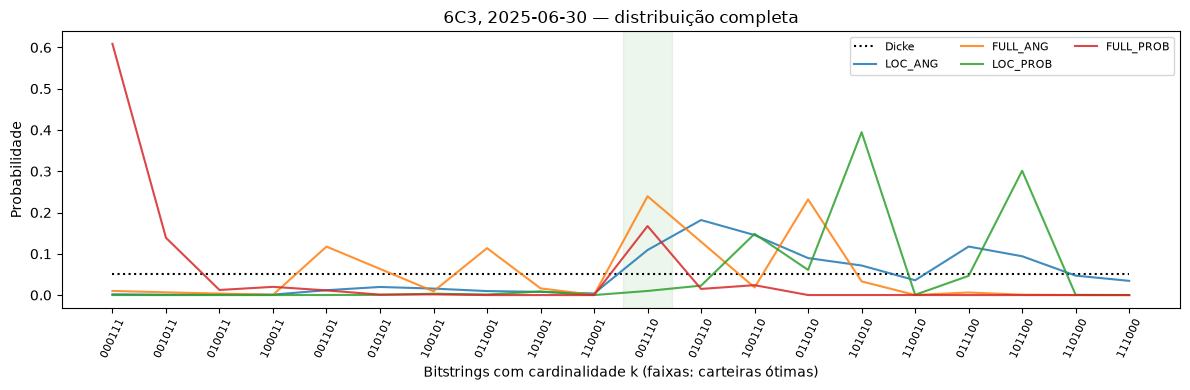

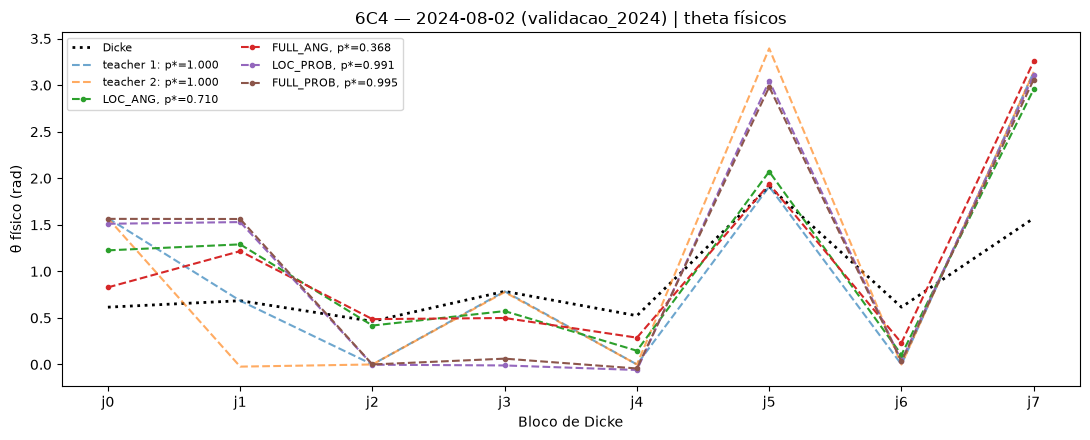

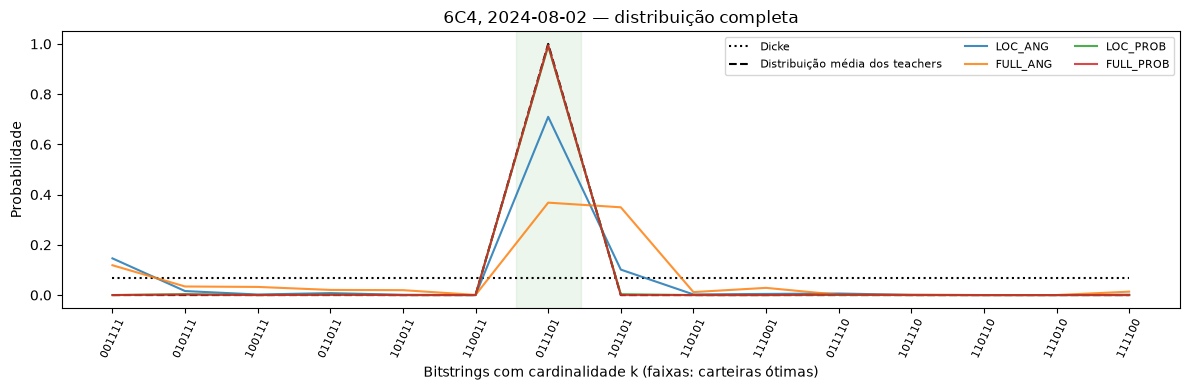

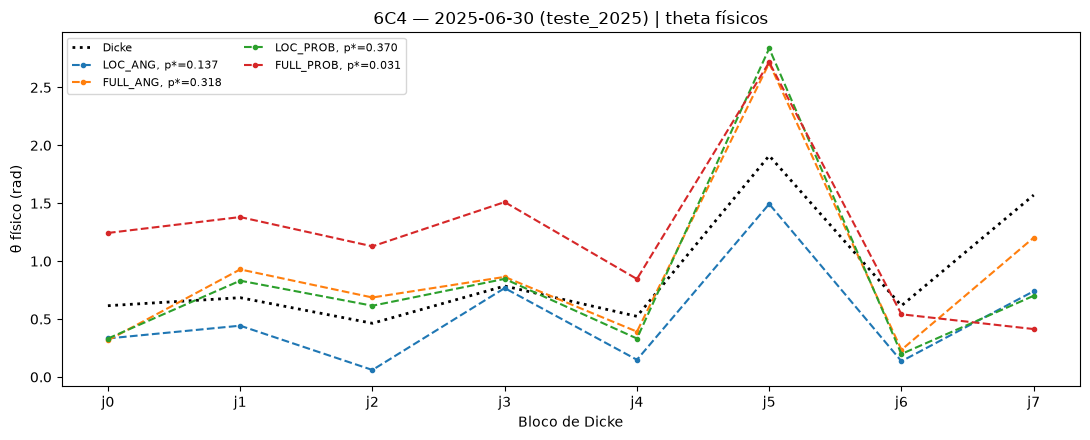

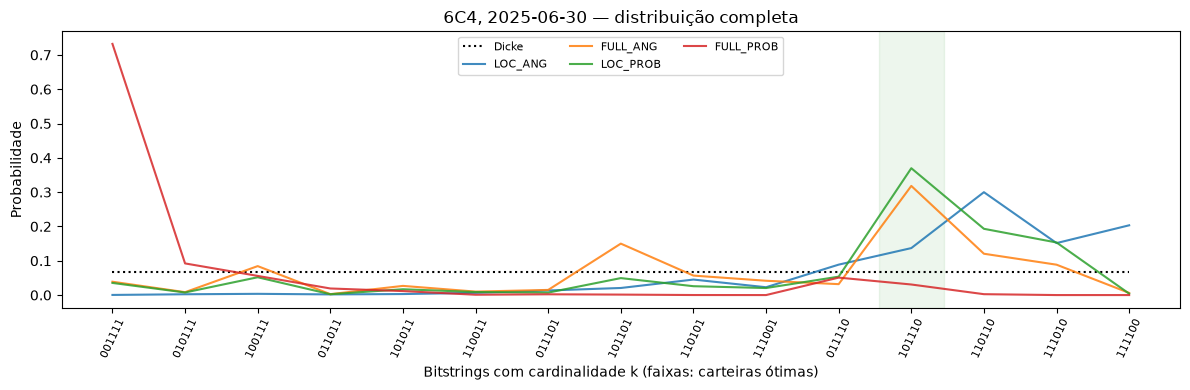

In [20]:
# A21 — Painéis, gráficos tracejados theta e histogramas das distribuições.
assert G540_HIST and G540_MODELOS
hist=pd.DataFrame(G540_HIST)
fig,ax=plt.subplots(figsize=(10,4))
for chave,g in hist.groupby('modelo'):
    ax.plot(g['epoca'],g['p_val2024'],label=chave)
ax.axhline(G539_THRESHOLD,color='black',ls=':',label='meta 90%')
ax.set(xlabel='Época',ylabel='p* médio na validação/2024',
       title='Ablação 2×2: mesma rede e treino, mudança apenas do contexto/perda')
ax.legend(ncol=2);plt.tight_layout();plt.show()

for k in G539_KS:
    # Duas instâncias: validação com teacher existente; teste posterior sem teacher.
    exemplos=[next(r for r in G539_VAL if r['k']==k and r.get('targets')),
              next(r for r in G540_TEST_INSTANCIAS if r['k']==k and r['grupo']=='teste_2025')]
    c=G539_CIRCUITOS[k]
    for r in exemplos:
        x=np.arange(c.g)
        fig,ax=plt.subplots(figsize=(11,4.5))
        ax.plot(x,c.phiD*c.periodo/(2*np.pi),':',color='black',lw=2,label='Dicke')
        if r.get('targets'):
            for it,d in enumerate(r['targets'][:3]):
                ax.plot(x,(c.phiD+d)*c.periodo/(2*np.pi),'--',alpha=.65,
                        label=f'teacher {it+1}: p*={c.probs(c.phiD+d)[r["mask_opt"]].sum():.3f}')
        for chave,cfg in G540_VARIANTES.items():
            net=G540_MODELOS[chave].eval()
            with torch.no_grad():
                d=net(g539_input(r,'23D'),g540_h_input(r,cfg['global_h'])).cpu().numpy()
            pp=c.probs(c.phiD+d)
            ax.plot(x,(c.phiD+d)*c.periodo/(2*np.pi),'--o',ms=3,
                    label=f'{chave}, p*={pp[r["mask_opt"]].sum():.3f}')
        ax.set(xticks=x,xticklabels=[f'j{j}' for j in x],xlabel='Bloco de Dicke',
               ylabel='θ físico (rad)',title=f'6C{k} — {r["data"]} ({r["grupo"]}) | theta físicos')
        ax.legend(fontsize=8,ncol=2);plt.tight_layout();plt.show()

        # Probabilidades por estado válido: duas soluções angulares distintas podem coincidir aqui.
        bitstrings=[''.join(map(str,z[::-1])) for z in c.X]
        fig,ax=plt.subplots(figsize=(12,4))
        pos=np.arange(len(c.X))
        ax.plot(pos,np.full(len(pos),1/len(pos)),':',color='black',label='Dicke')
        if r.get('targets'):
            q=g540_q_teacher(r).numpy()
            ax.plot(pos,q,'k--',label='Distribuição média dos teachers')
        for chave,cfg in G540_VARIANTES.items():
            with torch.no_grad():
                d=G540_MODELOS[chave](g539_input(r,'23D'),g540_h_input(r,cfg['global_h'])).numpy()
            ax.plot(pos,c.probs(c.phiD+d),label=chave,alpha=.85)
        for jopt in np.flatnonzero(r['mask_opt']):ax.axvspan(jopt-.45,jopt+.45,color='green',alpha=.07)
        ax.set(xticks=pos,xticklabels=bitstrings,
               xlabel='Bitstrings com cardinalidade k (faixas: carteiras ótimas)',
               ylabel='Probabilidade',title=f'6C{k}, {r["data"]} — distribuição completa')
        ax.tick_params(axis='x',labelsize=8)
        plt.setp(ax.get_xticklabels(),rotation=65)
        ax.legend(fontsize=8,ncol=3);plt.tight_layout();plt.show()

## A22 — Interpretação sem extrapolação: ablação de informação × função de perda

A tabela abaixo só será produzida **depois da execução local A19–A21**. A leitura deve distinguir: (i) melhora do modelo `FULL_ANG` sobre `LOC_ANG` = ganho devido a $H$ completo sob a *mesma perda*; (ii) `LOC_PROB` sobre `LOC_ANG` = ganho devido à função de perda com o *mesmo contexto*; (iii) `FULL_PROB` sobre os demais = possível interação das duas mudanças. **Não selecione o melhor braço usando o teste 2025/2026**: esta ablação é diagnóstica; seleção final de arquitetura requer uma validação apropriada e um novo teste não utilizado no desenvolvimento. Repetir com diversas sementes e datas realmente independentes é necessário antes de afirmar superioridade.

**Limite específico do método:** a otimização de targets A5 usa as máscaras ótimas exatas, acessíveis neste exemplo de 6 ativos por enumeração. A rede não recebe a máscara diretamente, mas as distribuições-alvo refletem essa escolha. A perda no espaço de probabilidades resolve o problema de penalizar duas parametrizações angulares equivalentes, porém não garante que o mapeamento entre $H$ e probabilidade ótima seja facilmente aprendível ou que $p_*>90\%$ seja atingido em datas futuras.

In [21]:
# A22 — Contrastes numéricos em VALIDAÇÃO para não escolher arquitetura pelo teste.
if 'G540_AVALIACOES_DF' not in globals():
    raise RuntimeError('Execute A20 para calcular o diagnóstico final de forma verificável.')
grp=(G540_AVALIACOES_DF[G540_AVALIACOES_DF['grupo']=='validacao_2024']
     .groupby('modelo')['p_star'].mean())
contrastes={
    'H completo, loss angular':grp['FULL_ANG']-grp['LOC_ANG'],
    'H completo, loss probabilidade':grp['FULL_PROB']-grp['LOC_PROB'],
    'Loss probabilidade, tokens locais':grp['LOC_PROB']-grp['LOC_ANG'],
    'Loss probabilidade, H completo':grp['FULL_PROB']-grp['FULL_ANG'],
}
G540_CONTRASTES=pd.DataFrame([dict(contraste=k,diferenca_pstar_validacao=v,
                                   diferenca_pontos_percentuais=100*v)
                              for k,v in contrastes.items()])
display(G540_CONTRASTES.round(4))
G540_CONTRASTES.to_csv(G539_BASE/'G540_contrastes_validacao_2024.csv',index=False)
print('IMPORTANTE: isto é ablação exploratória, não demonstração de causalidade robusta; '
      'repetir várias sementes e acrescentar datas independentes.')

,contraste,diferenca_pstar_validacao,diferenca_pontos_percentuais
0,"H completo, loss angular",-0.0091,-0.9101
1,"H completo, loss probabilidade",-0.0527,-5.2671
2,"Loss probabilidade, tokens locais",0.2599,25.9910
3,"Loss probabilidade, H completo",0.2163,21.6340


IMPORTANTE: isto é ablação exploratória, não demonstração de causalidade robusta; repetir várias sementes e acrescentar datas independentes.


## A23 — Nova hipótese: treino **pela energia esperada**, não por ângulos ótimos

Este é um **novo ramo experimental acrescentado ao G5.38**, mantendo A1–A22 e seus outputs anteriores (nenhum código histórico é sobrescrito). **Caminho de execução a partir de um kernel vazio:** execute somente os códigos **A1, A2, A3, A4, A15 e A24–A30**. Não execute A5–A14 nem A16–A22 para este experimento; esses blocos são históricos e geram *teachers*/targets. O A15 fornece a evolução do circuito equivalente ao NumPy, já validada por A16 na execução histórica.

Para cada instância financeira $H=(\mu,\Sigma)$ e cada $k\in\{2,3,4\}$:

$$E_H(x)=\tfrac12 x^\top\Sigma x-\mu^\top x,\quad \mathcal E(\phi;H)=\sum_{|x|=k}P_\phi(x)E_H(x).$$

O Transformer 23D continua prevendo $\Delta\phi\in[-1.2,1.2]^g$ em **um forward**, com $g=k(6-k)$. O simulador diferenciável calcula $P_{\phi_D+\Delta\phi}$; a perda é a energia esperada **centrada e dividida pelo desvio de energias do próprio Hamiltoniano**. O ponto de Dicke uniforme tem perda zero; valores negativos são melhores. **Nenhum $E_{\min}$, $p_*$, máscara de ótimo ou $\phi^*$ é fornecido ao modelo ou usado para selecionar o checkpoint.** Essas métricas só aparecem na auditoria *depois* de congelar a rede.

Importante: para 6 qubits, a enumeração de **todas as energias** dos 15 ou 20 bitstrings válidos viabiliza a esperança exata sem Monte Carlo; isso não é o mesmo que utilizar o menor desses valores como oráculo. Para $n$ grande, a soma exata se torna cara, exigindo amostragem, aproximação ou outra estratégia.

Também controlamos a observação sobre *ctx_min*: nas instâncias pequenas, 32 carteiras de contexto quase sempre incluem a ótima. Mantemos os **23 lugares do token**, mas neutralizamos **somente a coluna 18 (índice 17, `ctx_min`)** neste ramo para evitar um sinal indireto quase oracular. Os demais atributos, Dicke, arquitetura com 48 dimensões, 2 camadas e 4 cabeças permanecem como antes.

In [22]:
# A24 — Configuração e instâncias SEM targets e SEM rótulos de ótimo, com embargo temporal.
# Depende de A1–A4 e A15; NÃO depende de A5/A6 (geradores supervisionados).
G541_EPOCHS=35
G541_LR=7e-4
G541_WEIGHT_DECAY=1e-4
G541_SEED=20261022
G541_RHO=G539_RHO
G541_ENABLE_GLOBAL=True   # dois braços LOC_E e FULL_E; sem mudar d_model=48
G541_ENTROPY_WEIGHT=0.0    # zero para isolar inicialmente apenas a energia
G541_VAL_FROM='2024-09-01'  # validação mais tardia, permitindo purgar janelas de 60 retornos
G541_OUT=G539_BASE/'g541_energia_sem_oraculo'
G541_OUT.mkdir(parents=True,exist_ok=True)

# 60 pregões nos cálculos: train[-60:] e val[-60:] NÃO podem compartilhar uma observação.
val_candidates=[d for d in G539_DATES['validacao_2024'] if d>=G541_VAL_FROM]
if not val_candidates: raise RuntimeError('Nenhuma data de validação no intervalo escolhido.')
def g541_last_return_idx(date):
    idx=G539_RET.index.searchsorted(pd.Timestamp(date),side='right')-1
    if idx<59:raise RuntimeError(f'Histórico insuficiente em {date}')
    return int(idx)
val_first_idx=g541_last_return_idx(min(val_candidates))
train_dates=[d for d in G539_DATES['treino_2024']
             if g541_last_return_idx(d)<=val_first_idx-60]
if len(train_dates)<3: raise RuntimeError('Embargo de 60 observações deixou poucas datas de treino.')
assert max(g541_last_return_idx(d) for d in train_dates) < val_first_idx-59

rng_perm=np.random.default_rng(G539_SEED)
perms=[tuple(range(6))]
while len(perms)<5:
    x=tuple(map(int,rng_perm.permutation(6)))
    if x not in perms: perms.append(x)
train_perms,val_perms=perms[:3],perms[3:5]
assert set(train_perms).isdisjoint(val_perms)

def g541_instancia(date,k,perm,split):
    # Não chamar g539_instancia: essa rotina histórica calcula E_opt e mask_opt.
    mu0,sigma0=g539_hamiltoniano(date)
    perm=np.asarray(perm,dtype=int)
    assert sorted(perm.tolist())==list(range(6))
    mu=mu0[perm];sigma=sigma0[np.ix_(perm,perm)]
    c=G539_CIRCUITOS[k]
    energies=g539_energias(c.X,mu,sigma)  # vetor completo, SEM reduzir pelo mínimo
    # Os resumos são computados sem o mínimo, inclusive antes de g539_tokens.
    idx=np.random.default_rng(g539_seed(date,k,'contexto')).integers(0,len(energies),size=32)
    v=energies[idx]
    r=dict(data=str(date),k=int(k),grupo=split,perm=tuple(map(int,perm)),
           mu=mu,Sigma=sigma,E=energies,
           contexto=dict(mean=float(v.mean()),std=float(v.std()),sample_min=0.0))
    tok=g539_tokens(r)
    assert np.allclose(tok[:,17],0.)
    r['tokens']=tok
    assert not any(s in r for s in ('E_opt','mask_opt','targets','target','p_star'))
    return r

G541_SPLITS={}
for split,dates,pp in [
    ('treino_2024',train_dates,train_perms),
    ('validacao_2024',val_candidates,val_perms),
    ('teste_2025',G539_DATES['teste_2025'],[tuple(range(6))]),
    ('teste_2026',G539_DATES['teste_2026'],[tuple(range(6))])]:
    G541_SPLITS[split]=[g541_instancia(d,k,p,split) for d in dates for k in G539_KS for p in pp]
    print(split,'datas',len(dates),'instâncias',len(G541_SPLITS[split]))
G541_TRAIN=G541_SPLITS['treino_2024'];G541_VAL=G541_SPLITS['validacao_2024']
G541_TRI=np.triu_indices(6)
def g541_hglobal(r):
    v=np.r_[r['mu'],r['Sigma'][G541_TRI]].astype(np.float32)
    assert v.shape==(27,)
    return v

token_data=np.concatenate([r['tokens'] for r in G541_TRAIN],axis=0)
G541_TOKEN_MEAN=token_data.mean(0); G541_TOKEN_STD=np.maximum(token_data.std(0),1e-5)
global_data=np.stack([g541_hglobal(r) for r in G541_TRAIN])
G541_H_MEAN=global_data.mean(0);G541_H_STD=np.maximum(global_data.std(0),1e-5)
def g541_tok(r):
    x=np.clip((r['tokens']-G541_TOKEN_MEAN)/G541_TOKEN_STD,-10,10)
    return torch.tensor(x,dtype=torch.float32)
def g541_h(r,global_on):
    if not global_on:return torch.zeros(27,dtype=torch.float32)
    v=np.clip((g541_hglobal(r)-G541_H_MEAN)/G541_H_STD,-10,10)
    return torch.tensor(v,dtype=torch.float32)

np.savez(G541_OUT/'scalers_treino_purgado.npz',token_mean=G541_TOKEN_MEAN,
         token_std=G541_TOKEN_STD,global_mean=G541_H_MEAN,global_std=G541_H_STD,
         columns=np.asarray(G539_COLUNAS),train_dates=np.asarray(train_dates),
         validation_dates=np.asarray(val_candidates))
print('Embargo efetivo entre última data treino e primeira validação:',
      val_first_idx-max(g541_last_return_idx(d) for d in train_dates),'pregões.')
print('O campo ctx_min está presente (23D) mas neutralizado; os targets não são usados.')

treino_2024 datas 8 instâncias 72
validacao_2024 datas 2 instâncias 12
teste_2025 datas 2 instâncias 6
teste_2026 datas 2 instâncias 6
Embargo efetivo entre última data treino e primeira validação: 67 pregões.
O campo ctx_min está presente (23D) mas neutralizado; os targets não são usados.


## A25 — Energia esperada diferenciável e controle de ausência de oráculo

A função de treino recebe **somente** $r[\text{E}]$, a lista das energias permitidas pelo Hamiltoniano, e $P_\phi$. Define $\overline E=\mathrm{mean}_x E_H(x)$ e $s_E=\max(\mathrm{std}_x E_H(x),10^{-4})$. A perda $[\mathcal E-\overline E]/s_E$ é zero no estado de Dicke ideal e **não precisa conhecer a energia mínima**. A normalização é apenas para comparabilidade entre datas; documentamos o piso numérico. O gradiente se propaga até os pesos do Transformer passando pelo simulador exato.

O conjunto de validação (2024, com embargo real de 60 retornos em relação ao treino) escolhe checkpoints **unicamente pelo menor valor dessa perda**. É intencionalmente diferente do protocolo histórico, que selecionava por $p_*$. Não há regularização por $\|\nabla_\theta\mathcal E\|^2$ neste teste inicial: Hessiana e gradiente serão **diagnósticos posteriores**, para não confundir os fatores experimentais.

In [23]:
# A25 — Exatamente a arquitetura 23D/48D/4 cabeças do G5.38; professor não é acessado.
class G541Transformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed=nn.Sequential(nn.Linear(23,48),nn.LayerNorm(48))
        self.global_proj=nn.Linear(27,48,bias=False)
        nn.init.zeros_(self.global_proj.weight)
        self.fusion_norm=nn.LayerNorm(48)
        layer=nn.TransformerEncoderLayer(d_model=48,nhead=4,dim_feedforward=96,
                                          dropout=0.,activation='gelu',batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        self.angle=nn.Linear(48,1)
        nn.init.zeros_(self.angle.weight);nn.init.zeros_(self.angle.bias)
    def forward(self,tokens,hglobal):
        assert tokens.ndim==2 and tokens.shape[1]==23 and hglobal.shape==(27,)
        h=self.fusion_norm(self.embed(tokens)+self.global_proj(hglobal).unsqueeze(0))
        z=self.encoder(h.unsqueeze(0)).squeeze(0)
        return G541_RHO*torch.tanh(self.angle(z).squeeze(-1))

def g541_expected_loss(delta,r):
    assert not any(key in r for key in ('E_opt','mask_opt','targets','p_star'))
    p=G540_CIRCUITOS[r['k']].probs_delta(delta)
    energies=torch.as_tensor(r['E'],dtype=p.dtype,device=p.device)
    assert energies.shape==p.shape
    ebar=energies.mean()
    scale=energies.std(unbiased=False).clamp_min(1e-4)
    expected=(p*energies).sum()
    return (expected-ebar)/scale,expected,p

# Verificação que o simulador preserva norma e gera gradientes ANTES do treino.
for k in G539_KS:
    r=next(r for r in G541_TRAIN if r['k']==k)
    d=torch.zeros(G539_CIRCUITOS[k].g,dtype=torch.float64,requires_grad=True)
    l,e,p=g541_expected_loss(d,r)
    assert torch.isfinite(l) and torch.allclose(l,torch.zeros_like(l),atol=1e-10)
    assert torch.isclose(p.sum(),torch.ones_like(p.sum()),atol=1e-10)
    grad=torch.autograd.grad(l,d)[0]
    assert torch.isfinite(grad).all()
    print(f'6C{k}: Dicke loss={l.item():+.3e}, grad-norm={grad.norm().item():.4e}, estados={len(p)}')

# Smoke test de backward nos pesos sem usar targets.
torch.manual_seed(G541_SEED)
r=G541_TRAIN[0];probe=G541Transformer()
d=probe(g541_tok(r),g541_h(r,True))
loss,_,_=g541_expected_loss(d,r)
loss.backward()
assert torch.isfinite(probe.angle.weight.grad).all() and probe.angle.weight.grad.norm()>1e-12
print('Backward sem SPSA, teacher, E_min ou p* passou.')

6C2: Dicke loss=+0.000e+00, grad-norm=1.4361e+00, estados=15
6C3: Dicke loss=+0.000e+00, grad-norm=1.4575e+00, estados=20
6C4: Dicke loss=-2.739e-15, grad-norm=1.4423e+00, estados=15
Backward sem SPSA, teacher, E_min ou p* passou.


## A26 — Aprendizado por energia: LOC_E × FULL_E (checkpoint sem oráculo)

Comparação com mesma inicialização e mesmo orçamento: ambos recebem 23 características por bloco, têm 48 canais latentes, duas camadas e quatro cabeças. O braço `FULL_E` recebe, além disso, 6 retornos e 21 covariâncias independentes. O braço `LOC_E` injeta vetor global nulo **com a mesma arquitetura e número de pesos nominais**. A variável-alvo é a energia esperada normalizada, e não $\theta^*$, $p_*$ ou $E_{\min}$. O resultado principal é o desempenho em períodos posteriores, calculado apenas depois de congelar o checkpoint.

In [24]:
# A26 — Treinar com o circuito diferenciável, sem SPSA e sem soluções angulares professoras.
G541_VARIANTES={'LOC_E':False,'FULL_E':True} if G541_ENABLE_GLOBAL else {'LOC_E':False}
G541_MODELOS={};G541_HIST=[];G541_HASH_INICIAIS={};G541_BEST={}
def g541_val_loss(net,global_on,examples):
    net.eval();z=[]
    with torch.no_grad():
        for r in examples:
            delta=net(g541_tok(r),g541_h(r,global_on))
            score,_,_=g541_expected_loss(delta,r)
            z.append(float(score))
    return float(np.mean(z))

for label,global_on in G541_VARIANTES.items():
    torch.manual_seed(G541_SEED)
    net=G541Transformer()
    ini=torch.cat([p.detach().flatten() for p in net.parameters()]).numpy()
    G541_HASH_INICIAIS[label]=hashlib.sha256(ini.tobytes()).hexdigest()
    opt=torch.optim.AdamW(net.parameters(),lr=G541_LR,weight_decay=G541_WEIGHT_DECAY)
    rng=np.random.default_rng(G541_SEED)
    best_loss=g541_val_loss(net,global_on,G541_VAL)
    best_epoch=0;best_state=copy.deepcopy(net.state_dict())
    G541_HIST.append(dict(modelo=label,epoca=0,loss_treino=np.nan,loss_val=best_loss))
    for epoch in range(1,G541_EPOCHS+1):
        net.train();cost=[]
        for ii in rng.permutation(len(G541_TRAIN)):
            r=G541_TRAIN[int(ii)]
            delta=net(g541_tok(r),g541_h(r,global_on))
            loss,expected,p=g541_expected_loss(delta,r)
            if G541_ENTROPY_WEIGHT:
                loss=loss+G541_ENTROPY_WEIGHT*(p*torch.log(p.clamp_min(1e-12))).sum()
            opt.zero_grad(set_to_none=True);loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(),1.0)
            opt.step();cost.append(float(loss.detach()))
        val=g541_val_loss(net,global_on,G541_VAL)
        G541_HIST.append(dict(modelo=label,epoca=epoch,
                             loss_treino=float(np.mean(cost)),loss_val=val))
        if val<best_loss-1e-9:
            best_loss=val;best_epoch=epoch;best_state=copy.deepcopy(net.state_dict())
        if epoch in (1,5,10,15,20,25,30,35) or epoch==G541_EPOCHS:
            print(f'{label} ep {epoch:02d}/{G541_EPOCHS}: '
                  f'energia_norm(treino)={np.mean(cost):+.4f}, '
                  f'energia_norm(val)={val:+.4f}',flush=True)
    net.load_state_dict(best_state);net.eval()
    G541_MODELOS[label]=net
    G541_BEST[label]=dict(epoca=best_epoch,val_norm=best_loss)
    torch.save(dict(state_dict=best_state,modelo=label,epoch=best_epoch,
                    criterio='energia_esperada_normalizada_val2024',
                    valor_validacao=best_loss,sem_oraculo=True,
                    atributos=G539_COLUNAS,global_h=global_on),
               G541_OUT/f'{label}_energy_checkpoint.pt')
    print('CHECKPOINT',label, G541_BEST[label])
assert len(set(G541_HASH_INICIAIS.values()))==1
pd.DataFrame(G541_HIST).to_csv(G541_OUT/'curvas_treino_energia.csv',index=False)
print('Pesos iniciais idênticos: OK. Modelo congelado; a auditoria p* só começa em A27.')

LOC_E ep 01/35: energia_norm(treino)=-1.0091, energia_norm(val)=-0.9131
LOC_E ep 05/35: energia_norm(treino)=-1.6467, energia_norm(val)=-0.9249
LOC_E ep 10/35: energia_norm(treino)=-1.6799, energia_norm(val)=-1.0159
LOC_E ep 15/35: energia_norm(treino)=-1.6720, energia_norm(val)=-1.0667
LOC_E ep 20/35: energia_norm(treino)=-1.6810, energia_norm(val)=-1.0543
LOC_E ep 25/35: energia_norm(treino)=-1.6860, energia_norm(val)=-1.1913
LOC_E ep 30/35: energia_norm(treino)=-1.6803, energia_norm(val)=-0.9026
LOC_E ep 35/35: energia_norm(treino)=-1.6663, energia_norm(val)=-0.8659
CHECKPOINT LOC_E {'epoca': 28, 'val_norm': -1.2213012675444286}
FULL_E ep 01/35: energia_norm(treino)=-1.0032, energia_norm(val)=-1.1070
FULL_E ep 05/35: energia_norm(treino)=-1.6530, energia_norm(val)=-1.0038
FULL_E ep 10/35: energia_norm(treino)=-1.6754, energia_norm(val)=-1.0188
FULL_E ep 15/35: energia_norm(treino)=-1.6788, energia_norm(val)=-1.0831
FULL_E ep 20/35: energia_norm(treino)=-1.6810, energia_norm(val)=-0.

## A27 — Auditoria *após* o treinamento: energia, excesso sobre o mínimo, $p_*$ e 90%

**Somente aqui** a auditoria enumera o menor nível de energia para medir a qualidade do modelo. Esse mínimo **não foi consultado** no treino, no `backward` ou na seleção do checkpoint. Relatamos $p_*$ para todas as datas e cardinalidades — inclusive falhas — e comparamos a energia esperada contra Dicke e contra o ótimo enumerado. A probabilidade de medir uma ótima solução é separada da condição de estacionariedade da energia; uma solução pode ter energia esperada relativamente baixa sem atingir $p_*\geq0.90$.

In [25]:
# A27 — Avaliação sem gradientes nem atualização de pesos.
G541_ROWS=[];G541_PRED={}
for key,net in G541_MODELOS.items():
    glob=G541_VARIANTES[key]
    with torch.no_grad():
        for grupo,rr in G541_SPLITS.items():
            for r in rr:
                delta=net(g541_tok(r),g541_h(r,glob)).cpu().numpy()
                c=G539_CIRCUITOS[r['k']]
                prob=c.probs(c.phiD+delta)
                E=r['E'];emin=E.min(); mask=np.isclose(E,emin,atol=1e-10,rtol=0)
                e_pred=float(prob@E);e_dicke=float(E.mean())
                pstar=float(prob[mask].sum())
                key_r=(key,grupo,r['data'],r['k'],r['perm'])
                G541_PRED[key_r]=dict(delta=delta,prob=prob)
                G541_ROWS.append(dict(modelo=key,grupo=grupo,data=r['data'],k=r['k'],
                  perm=str(r['perm']),energia=e_pred,energia_dicke=e_dicke,
                  energia_min=float(emin),excesso=float(e_pred-emin),
                  melhoria_energia=float(e_dicke-e_pred),p_star=pstar,
                  passou90=bool(pstar>=G539_THRESHOLD)))
G541_AUDIT=pd.DataFrame(G541_ROWS)
G541_AUDIT.to_csv(G541_OUT/'auditoria_pos_treino_todas_instancias.csv',index=False)
res=(G541_AUDIT.groupby(['modelo','grupo','k']).agg(n=('p_star','size'),
  hits90=('passou90','sum'),p_medio=('p_star','mean'),
  excesso_energia=('excesso','mean'),melhoria_sobre_dicke=('melhoria_energia','mean'))
  .reset_index())
res.to_csv(G541_OUT/'resumo_por_k_split.csv',index=False)
print('Resumo por período e modelo; somente relatório, sem retreinar:')
display(G541_AUDIT.groupby(['modelo','grupo']).agg(n=('p_star','size'),
    hits90=('passou90','sum'),p_medio=('p_star','mean'),
    excesso=('excesso','mean'),melhoria_dicke=('melhoria_energia','mean')).round(5))
print('Resultados detalhados por 6C2 / 6C3 / 6C4:')
display(res.round(5))

Resumo por período e modelo; somente relatório, sem retreinar:


n  hits90  p_medio  excesso  melhoria_dicke
modelo grupo                                                       
FULL_E teste_2025       6       1  0.20903  0.50760         0.47222
       teste_2026       6       1  0.27134  0.18398         0.77402
       treino_2024     72      64  0.88470  0.00569         0.71200
       validacao_2024  12       2  0.23262  0.11519         0.33911
LOC_E  teste_2025       6       2  0.65127  0.16027         0.81955
       teste_2026       6       3  0.59368  0.14235         0.81565
       treino_2024     72      64  0.88887  0.00469         0.71300
       validacao_2024  12       3  0.26015  0.09924         0.35506

Resultados detalhados por 6C2 / 6C3 / 6C4:


,modelo,grupo,k,n,hits90,p_medio,excesso_energia,melhoria_sobre_dicke
0,FULL_E,teste_2025,2,2,0,0.01897,0.49433,0.51255
1,FULL_E,teste_2025,3,2,0,0.06784,0.50669,0.51574
2,FULL_E,teste_2025,4,2,1,0.54029,0.52179,0.38838
3,FULL_E,teste_2026,2,2,1,0.65835,0.19028,0.79032
4,FULL_E,teste_2026,3,2,0,0.11822,0.23829,0.79153
5,FULL_E,teste_2026,4,2,0,0.03744,0.12337,0.74021
6,FULL_E,treino_2024,2,24,24,0.99585,0.00087,0.65950
7,FULL_E,treino_2024,3,24,19,0.78640,0.00777,0.73919
8,FULL_E,treino_2024,4,24,21,0.87186,0.00843,0.73732
9,FULL_E,validacao_2024,2,4,1,0.44569,0.01450,0.43541


## A28 — Gradientes, Hessianas e condições de estacionariedade

**Interpretação geométrica local:** para cada Hamiltoniano, mediremos a Hessiana exata $\partial^2\mathcal E/(\partial\theta_i\partial\theta_j)$ nos **ângulos físicos** $\theta_j=(T_j/2\pi)\phi_j$, e seu espectro $\lambda_i$. Autovalores de pequena magnitude sugerem direções localmente pouco sensíveis; sinais positivos e negativos distinguem curvaturas locais. Isso **não demonstra** que o conjunto de soluções tenha uma topologia específica, nem implica uma conexão com curvatura do espaço-tempo.

Verificaremos três pontos por topologia: Dicke inicial, previsão do Transformer congelado e referência obtida com **otimização independente da energia esperada, sem usar a carteira ótima** (L-BFGS-B). Esta última é um *baseline* físico de otimização direta, **não um teacher** do treinamento neural. Repetições do otimizador são registradas, inclusive não convergências; não se descarta silenciosamente um caso ruim.

Como cada correção interna é limitada por $\Delta\phi\in[-1.2,1.2]$, a condição $\nabla_\theta\mathcal E=0$ só é necessária para mínimos interiores. Na fronteira, registraremos também o **resíduo projetado de primeira ordem/KKT**: gradientes de sinal permitido na borda não são penalizados. Autovalores da Hessiana irrestrita na fronteira também não são teste suficiente de mínimo restrito.

In [26]:
# A28 — Diagnóstico exato de derivadas e referência L-BFGS-B SEM oráculo.
from scipy.optimize import minimize
G541_HESS_PROBE_SPLIT='validacao_2024'   # nunca participa da seleção dos checkpoints já congelados
G541_HESS_PROBE_DATE=G541_SPLITS[G541_HESS_PROBE_SPLIT][0]['data']
G541_HESS_MAXITER=220
G541_HESS_RESTARTS=3
G541_FLAT_REL_TOL=1e-3   # limiar relativo exploratório, não propriedade topológica invariável

def g541_energy_physical(theta,r):
    c=G539_CIRCUITOS[r['k']]
    factor=torch.tensor(2*np.pi/c.periodo,dtype=theta.dtype,device=theta.device)
    phi=theta*factor
    p=G540_CIRCUITOS[r['k']].probs_phi(phi)
    E=torch.tensor(r['E'],dtype=theta.dtype,device=theta.device)
    return (p*E).sum()

def g541_hessian_diagnostico(phi,r):
    c=G539_CIRCUITOS[r['k']]
    theta=np.asarray(phi,dtype=float)*c.periodo/(2*np.pi)
    t=torch.tensor(theta,dtype=torch.float64,requires_grad=True)
    e=g541_energy_physical(t,r)
    grad=torch.autograd.grad(e,t)[0].detach().numpy()
    hess=torch.autograd.functional.hessian(lambda x:g541_energy_physical(x,r),t)
    matrix=hess.detach().numpy();matrix=.5*(matrix+matrix.T)
    eig=np.linalg.eigvalsh(matrix)
    scale=max(float(np.max(np.abs(eig))),1e-12)
    flat=int(np.sum(np.abs(eig)<G541_FLAT_REL_TOL*scale))
    # Resíduo de KKT projetado no intervalo permitido para delta_phi.
    delta=np.asarray(phi)-c.phiD
    kkt=grad.copy()
    lower=delta <= -G541_RHO+1e-6;upper=delta>=G541_RHO-1e-6
    kkt[lower]=np.minimum(kkt[lower],0.) # min constrained: grad >=0 em lower
    kkt[upper]=np.maximum(kkt[upper],0.) # min constrained: grad <=0 em upper
    return dict(energia=float(e.detach()), grad_norm=float(np.linalg.norm(grad)),
        kkt_norm=float(np.linalg.norm(kkt)), num_borda=int(np.sum(lower|upper)),
        lambda_min=float(eig[0]),lambda_max=float(eig[-1]),
        num_neg=int(np.sum(eig < -G541_FLAT_REL_TOL*scale)),
        num_flat=flat, eig=eig, H=matrix,theta=theta,grad=grad)

# Checagem pontual das derivadas FÍSICAS por diferenças finitas (independente do autograd).
for _k in G539_KS:
    _r=next(r for r in G541_VAL if r['k']==_k)
    _c=G539_CIRCUITOS[_k]
    _theta=_c.phiD*_c.periodo/(2*np.pi)+0.09
    _v=torch.tensor(_theta,dtype=torch.float64,requires_grad=True)
    _e=g541_energy_physical(_v,_r)
    _grad=torch.autograd.grad(_e,_v)[0].detach().numpy()
    _h=torch.autograd.functional.hessian(lambda t:g541_energy_physical(t,_r),_v).detach().numpy()
    _eps=1e-4
    _v1=_theta.copy();_v2=_theta.copy();_v1[0]+=_eps;_v2[0]-=_eps
    def _energy_np(theta):
        return float(g541_energy_physical(torch.tensor(theta,dtype=torch.float64),_r))
    _g_fd=(_energy_np(_v1)-_energy_np(_v2))/(2*_eps)
    _g1=torch.autograd.functional.jacobian(lambda t:g541_energy_physical(t,_r),
                                             torch.tensor(_v1,dtype=torch.float64)).numpy()
    _g2=torch.autograd.functional.jacobian(lambda t:g541_energy_physical(t,_r),
                                             torch.tensor(_v2,dtype=torch.float64)).numpy()
    _h_fd=(_g1-_g2)/(2*_eps)
    assert abs(_grad[0]-_g_fd)<2e-5 and np.max(np.abs(_h[:,0]-_h_fd))<5e-5
    print(f'6C{_k} derivadas físicas verificadas: |erro grad|={abs(_grad[0]-_g_fd):.2e}; '
          f'|erro Hess coluna|={np.max(np.abs(_h[:,0]-_h_fd)):.2e}')

def g541_ref_direta(r,restarts=G541_HESS_RESTARTS,maxiter=G541_HESS_MAXITER):
    # L-BFGS-B minimiza E(phiD+delta) com jacobiano calculado pelo autograd.
    c=G539_CIRCUITOS[r['k']];logs=[];best=None
    gen=np.random.default_rng(g539_seed('G541_ref',r['data'],r['k'],r['perm']))
    for tentativa in range(restarts):
        start=np.zeros(c.g) if tentativa==0 else gen.uniform(-0.7,0.7,c.g)
        traj=[start.copy()]
        def eval_fn(delta):
            d=torch.tensor(delta,dtype=torch.float64,requires_grad=True)
            en=g541_expected_loss(d,r)[1]
            gradient=torch.autograd.grad(en,d)[0]
            return float(en.detach()),gradient.detach().numpy().astype(float)
        ans=minimize(eval_fn,start,method='L-BFGS-B',jac=True,
            bounds=[(-G541_RHO,G541_RHO)]*c.g,
            options=dict(maxiter=maxiter,ftol=1e-12,gtol=1e-9),
            callback=lambda x:traj.append(np.asarray(x).copy()))
        logs.append(dict(tentativa=tentativa+1,energia=float(ans.fun),
                         sucesso=bool(ans.success),mensagem=str(ans.message),
                         avaliacoes=int(ans.nfev),iteracoes=int(ans.nit),
                         delta=np.asarray(ans.x).copy(),traj=np.asarray(traj)))
        if best is None or ans.fun<best['energia']:
            best=logs[-1]
    return best,logs

G541_HESS_ROWS=[];G541_HESS_DATA={}
for k in G539_KS:
    r=next(r for r in G541_SPLITS[G541_HESS_PROBE_SPLIT]
           if r['k']==k and r['data']==G541_HESS_PROBE_DATE)
    c=G539_CIRCUITOS[k]
    ref,attempts=g541_ref_direta(r)
    points={'Dicke':c.phiD,'Direta_sem_oraculo':c.phiD+ref['delta']}
    for label,net in G541_MODELOS.items():
        with torch.no_grad():
            d=net(g541_tok(r),g541_h(r,G541_VARIANTES[label])).cpu().numpy()
        points[label]=c.phiD+d
    G541_HESS_DATA[k]=dict(instancia=r,points=points,direta=ref,tentativas=attempts)
    for label,phi in points.items():
        diag=g541_hessian_diagnostico(phi,r)
        G541_HESS_DATA[k].setdefault('diagnosticos',{})[label]=diag
        G541_HESS_ROWS.append(dict(k=k,data=r['data'],ponto=label,
            energia=diag['energia'],grad_norm=diag['grad_norm'],
            kkt_norm=diag['kkt_norm'],n_borda=diag['num_borda'],
            eig_min=diag['lambda_min'],eig_max=diag['lambda_max'],
            n_autovalores_negativos=diag['num_neg'],n_direcoes_quase_planas=diag['num_flat']))
    print(f'6C{k}: direta sem oráculo: '+', '.join(
        f"{v['energia']:.5f}({v['sucesso']}, {v['avaliacoes']} aval)" for v in attempts))
G541_HESS_RESUMO=pd.DataFrame(G541_HESS_ROWS)
G541_HESS_RESUMO.to_csv(G541_OUT/'hessiana_resumo_fisico.csv',index=False)
display(G541_HESS_RESUMO.round(7))

6C2 derivadas físicas verificadas: |erro grad|=2.28e-09; |erro Hess coluna|=2.61e-09
6C3 derivadas físicas verificadas: |erro grad|=2.47e-09; |erro Hess coluna|=9.00e-10
6C4 derivadas físicas verificadas: |erro grad|=2.40e-09; |erro Hess coluna|=7.76e-10
6C2: direta sem oráculo: -0.74342(True, 23 aval), -0.74342(True, 22 aval), -0.74342(True, 25 aval)
6C3: direta sem oráculo: -0.90848(True, 26 aval), -0.90848(True, 24 aval), -0.82862(True, 20 aval)
6C4: direta sem oráculo: -1.06795(True, 17 aval), -1.06795(True, 28 aval), -1.06795(True, 25 aval)


,k,data,ponto,energia,grad_norm,kkt_norm,n_borda,eig_min,eig_max,n_autovalores_negativos,n_direcoes_quase_planas
0,2,2024-09-13,Dicke,-0.338272,0.390130,0.390130,0,-0.157804,0.293909,3,0
1,2,2024-09-13,Direta_sem_oraculo,-0.743416,0.000000,0.000000,0,0.000000,0.701670,0,3
2,2,2024-09-13,LOC_E,-0.737835,0.037921,0.037921,0,-0.009010,0.612171,1,1
3,2,2024-09-13,FULL_E,-0.734114,0.058076,0.058076,0,-0.011379,0.605959,1,1
4,3,2024-09-13,Dicke,-0.501915,0.423956,0.423956,0,-0.190866,0.172918,5,0
5,3,2024-09-13,Direta_sem_oraculo,-0.908483,0.000000,0.000000,0,-0.000000,0.666320,0,4
6,3,2024-09-13,LOC_E,-0.891406,0.048386,0.048386,0,-0.030836,0.628227,2,4
7,3,2024-09-13,FULL_E,-0.883227,0.101333,0.101333,0,-0.033910,0.606962,2,2
8,4,2024-09-13,Dicke,-0.661897,0.404308,0.404308,0,-0.298827,0.209834,5,1
9,4,2024-09-13,Direta_sem_oraculo,-1.067947,0.000000,0.000000,0,-0.000000,0.693542,0,3


## A29 — Gráficos: energia por época, $\theta_j$, Hessiana e autovalores

Os painéis de ângulos mostram valores físicos $\theta_j$, não $\phi_j$, com a referência de Dicke pontilhada e as previsões da rede e a solução direta em linhas tracejadas. O espectro da Hessiana é calculado **nos mesmos ângulos**, para identificar se as diferenças entre perfis angulares ocorrem em direções de pequena curvatura. Energia pequena, $\|\nabla E\|$ pequeno, $p_*\geq90\%$ e compressibilidade por polinômios são propriedades **distintas**, que devem ser reportadas separadamente.

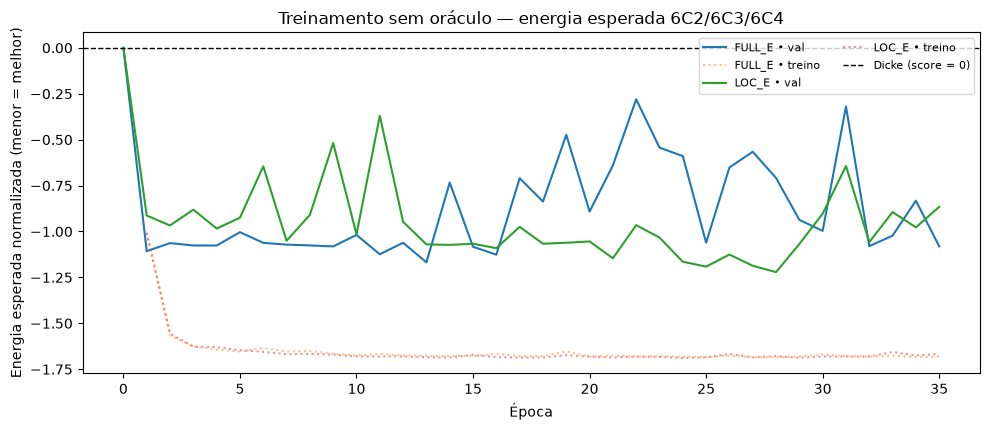

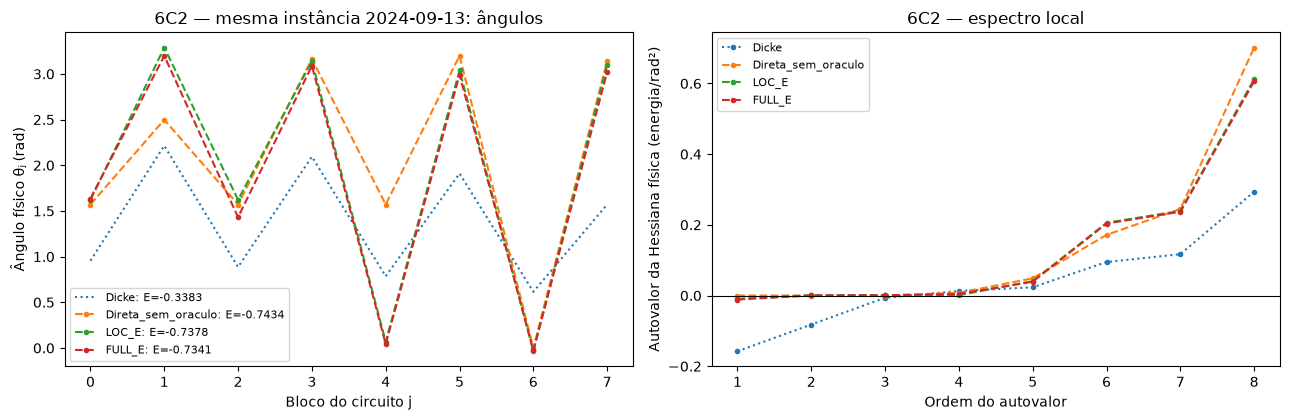

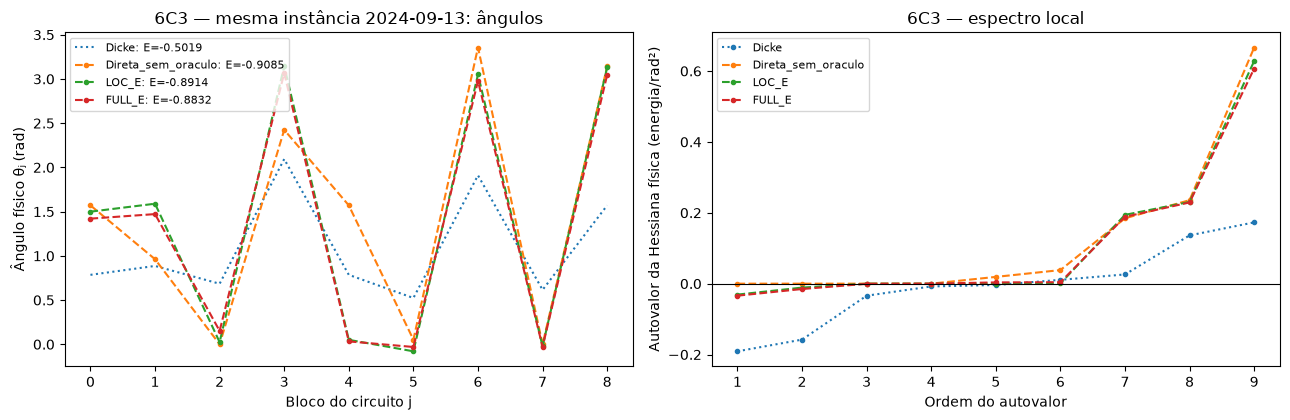

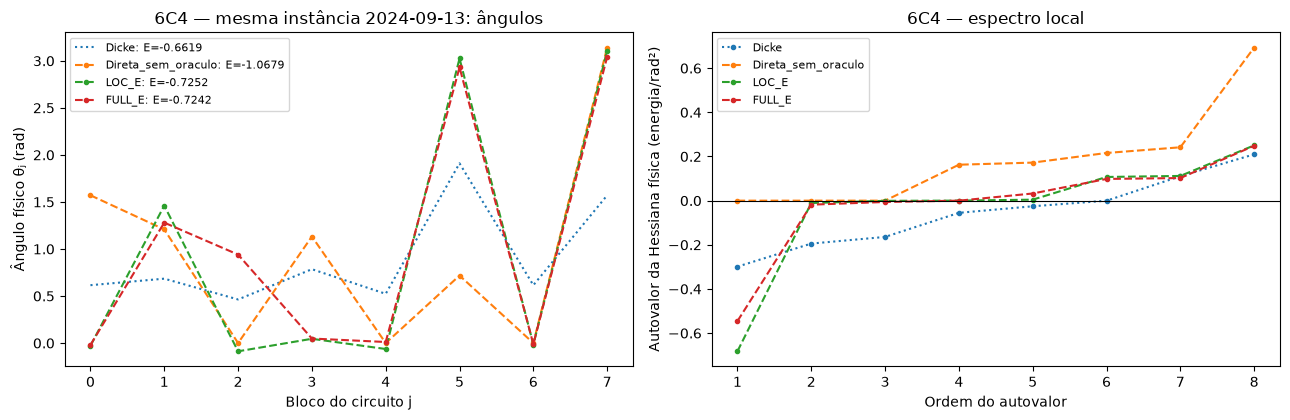

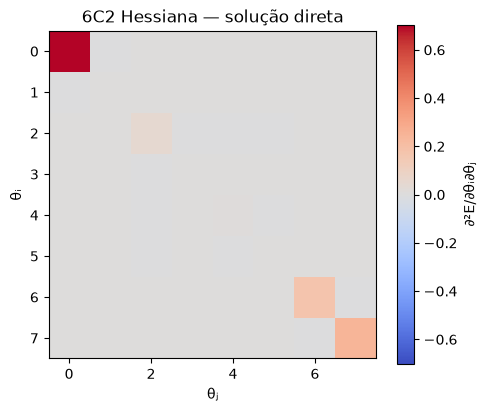

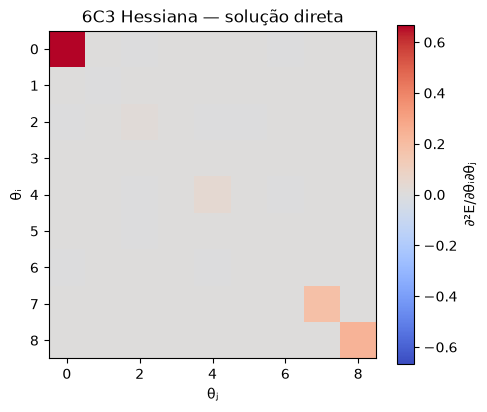

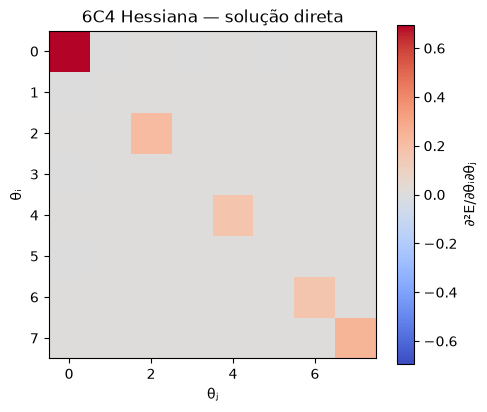

In [27]:
# A29 — Figuras em arquivos PNG para comparar o treino e a geometria local.
import matplotlib.pyplot as plt
hist=pd.DataFrame(G541_HIST)
fig,ax=plt.subplots(figsize=(10,4.4))
for label,g in hist.groupby('modelo'):
    ax.plot(g['epoca'],g['loss_val'],label=f'{label} • val')
    ax.plot(g['epoca'],g['loss_treino'],ls=':',alpha=.5,label=f'{label} • treino')
ax.axhline(0,ls='--',color='black',lw=1,label='Dicke (score = 0)')
ax.set(xlabel='Época',ylabel='Energia esperada normalizada (menor = melhor)',
       title='Treinamento sem oráculo — energia esperada 6C2/6C3/6C4')
ax.legend(ncol=2,fontsize=8);plt.tight_layout()
fig.savefig(G541_OUT/'A29_energia_treino_val_purgada.png',dpi=150);plt.show()

for k,registro in G541_HESS_DATA.items():
    r=registro['instancia'];c=G539_CIRCUITOS[k]
    fig,axs=plt.subplots(1,2,figsize=(13,4.3))
    for label,phi in registro['points'].items():
        d=registro['diagnosticos'][label]
        axs[0].plot(np.arange(c.g),d['theta'],linestyle=':' if label=='Dicke' else '--',
                    marker=None if label=='Dicke' else 'o',ms=3,
                    label=f"{label}: E={d['energia']:.4f}")
        axs[1].plot(range(1,c.g+1),np.sort(d['eig']),marker='o',ms=3,
                    linestyle=':' if label=='Dicke' else '--',label=label)
    axs[0].set(xticks=range(c.g),xlabel='Bloco do circuito j',ylabel='Ângulo físico θⱼ (rad)',
               title=f'6C{k} — mesma instância {r["data"]}: ângulos')
    axs[1].axhline(0,color='black',lw=.8)
    axs[1].set(xlabel='Ordem do autovalor',ylabel='Autovalor da Hessiana física (energia/rad²)',
               title=f'6C{k} — espectro local')
    axs[0].legend(fontsize=8);axs[1].legend(fontsize=8)
    fig.tight_layout();fig.savefig(G541_OUT/f'A29_6C{k}_angulos_hessiana.png',dpi=150);plt.show()

# Hessiana na melhor solução encontrada sem oráculo, sem inferir uma topologia do espaço-tempo.
for k,dados in G541_HESS_DATA.items():
    h=dados['diagnosticos']['Direta_sem_oraculo']['H']
    fig,ax=plt.subplots(figsize=(5.0,4.2))
    im=ax.imshow(h,cmap='coolwarm',vmin=-np.max(np.abs(h)),vmax=np.max(np.abs(h)))
    ax.set(xlabel='θⱼ',ylabel='θᵢ',title=f'6C{k} Hessiana \u2014 solução direta')
    fig.colorbar(im,ax=ax,label='∂²E/∂θᵢ∂θⱼ')
    fig.tight_layout();fig.savefig(G541_OUT/f'A29_6C{k}_hessian_heatmap.png',dpi=150);plt.show()

## A30 — Legendre/Fourier como **diagnóstico**, não como nova arquitetura

Sem mudar os 23 tokens ou treinar outra rede, projetamos **a correção interna** $\Delta\phi_j$ prevista para cada gate em bases menores: Legendre de grau 3 (4 coeficientes) e Fourier com um harmônico (3 coeficientes). A projeção é feita **após o treinamento** e comparada quanto à energia e às probabilidades — não apenas erro de ângulo. É um teste descritivo, e o índice do gate não é coordenada espacial física. Se as projeções forem boas de modo consistente em 2025/2026, poderemos testar uma cabeça de rede comprimida em outra versão.

In [28]:
# A30 — Legendre/Fourier: compressão experimental pós-treino sem ajuste por dados de teste.
from numpy.polynomial.legendre import legfit,legval
G541_COMP=[]
for label,net in G541_MODELOS.items():
    glob=G541_VARIANTES[label]
    for split,rs in G541_SPLITS.items():
        for r in rs:
            c=G539_CIRCUITOS[r['k']];g=c.g
            with torch.no_grad():
                original=net(g541_tok(r),g541_h(r,glob)).cpu().numpy()
            s=np.linspace(-1,1,g)
            leg=legval(s,legfit(s,original,deg=3))
            phase=2*np.pi*np.arange(g)/g
            F=np.column_stack([np.ones(g),np.cos(phase),np.sin(phase)])
            four=F@np.linalg.lstsq(F,original,rcond=None)[0]
            for tipo,d in [('LIVRE',original),('LEG3',leg),('FOURIER1',four)]:
                # Atenção: projeção não tem obrigação de respeitar limite [-1.2,+1.2].
                # Registramos violação, sem cortes artificiais que esconderiam a aproximação.
                pp=c.probs(c.phiD+d)
                E=r['E'];emin=E.min();mask=np.isclose(E,emin,atol=1e-10,rtol=0.)
                G541_COMP.append(dict(modelo=label,grupo=split,data=r['data'],k=r['k'],
                    metodo=tipo,energia=float(pp@E),pstar=float(pp[mask].sum()),
                    acima90=bool(pp[mask].sum()>=G539_THRESHOLD),
                    maior_delta=float(np.max(np.abs(d))),
                    RMSE_angular=float(np.sqrt(np.mean((original-d)**2)))))
G541_COMP_DF=pd.DataFrame(G541_COMP)
G541_COMP_DF.to_csv(G541_OUT/'compressao_angular_legendre_fourier.csv',index=False)
print('Comparação por período e arquitetura; resultados exploratórios, sem ajuste adicional:')
display(G541_COMP_DF.groupby(['modelo','grupo','metodo']).agg(n=('pstar','size'),
    pmedio=('pstar','mean'),hits90=('acima90','sum'),
    energia=('energia','mean'),RMSE_delta=('RMSE_angular','mean')).round(5))
print('NOTA: a escala de energia entre datas difere; diferenças dentro da mesma instância são mais informativas.')

Comparação por período e arquitetura; resultados exploratórios, sem ajuste adicional:


n   pmedio  hits90  energia  RMSE_delta
modelo grupo          metodo                                            
FULL_E teste_2025     FOURIER1   6  0.18771       0 -0.62547     0.43669
                      LEG3       6  0.29939       0 -0.81869     0.36821
                      LIVRE      6  0.20903       1 -0.77181     0.00000
       teste_2026     FOURIER1   6  0.06882       0 -0.95634     0.33069
                      LEG3       6  0.20376       0 -1.24606     0.19800
                      LIVRE      6  0.27134       1 -1.38628     0.00000
       treino_2024    FOURIER1  72  0.18485       1 -0.84192     0.59250
                      LEG3      72  0.26493       1 -0.91688     0.53065
                      LIVRE     72  0.88470      64 -1.32979     0.00000
       validacao_2024 FOURIER1  12  0.11164       0 -0.57067     0.49538
                      LEG3      12  0.13140       0 -0.63645     0.44859
                      LIVRE     12  0.23262       2 -0.75320     0.00000
LOC_E  teste_2025     FOURIER1   6  0.18002       0 -0.68266     0.44761
                      LEG3       6  0.29572       0 -0.92611     0.39551
                      LIVRE      6  0.65127       2 -1.11914     0.00000
       teste_2026     FOURIER1   6  0.14098       0 -0.97972     0.47187
                      LEG3       6  0.27790       0 -1.24766     0.36186
                      LIVRE      6  0.59368       3 -1.42791     0.00000
       treino_2024    FOURIER1  72  0.19047       2 -0.84821     0.59205
                      LEG3      72  0.26752       4 -0.92123     0.53383
                      LIVRE     72  0.88887      64 -1.33079     0.00000
       validacao_2024 FOURIER1  12  0.13823       0 -0.53922     0.49614
                      LEG3      12  0.20193       0 -0.67956     0.40445
                      LIVRE     12  0.26015       3 -0.76916     0.00000

NOTA: a escala de energia entre datas difere; diferenças dentro da mesma instância são mais informativas.


## A31 — Auditoria geométrica longitudinal (sem alterar o treinamento)

**Hipóteses:** (i) mudar a ordem dos ativos não altera o Hamiltoniano financeiro, mas pode alterar o desempenho do ansatz/Transformer; (ii) mínimos com energia semelhante podem apresentar diferentes vetores de ângulos e direções de baixa curvatura; (iii) pequenas alterações angulares em direções da Hessiana podem afetar diferentemente a energia e a probabilidade do ótimo.

**Origem de \(\langle H\rangle\):** as energias \(E_H(x)=\frac12x^\top\Sigma x-\mu^\top x\) são calculadas classicamente para \(\binom6k\) carteiras; o estado de Dicke modificado é simulado **classicamente**, em NumPy ou em PyTorch diferenciável, sem hardware quântico nem shots. Logo, \(\mathcal E=\sum_xP_\theta(x)E_H(x)\) é a **esperança exata calculada numericamente**, não o valor mínimo conhecido. O valor \(E_{\min}\) aparece **somente nas métricas de auditoria**, após o treinamento.

**Execução com o kernel limpo:** executar as células de código de **A1, A2, A3, A4, A15, A24 e A25**, depois **A32–A37**. Em A32, os checkpoints LOC_E/FULL_E anteriormente treinados em A26 serão carregados automaticamente, se os modelos não estiverem na memória. Caso ainda não existam, executar **A26 uma vez** antes de A32. Não é necessário repetir SPSA nem teacher supervisionado. Nenhuma métrica de auditoria altera os pesos. Caso já tenha A1–A30 executados, basta rodar A32–A37.

**Saídas:** arquivos CSV e PNG em `g539_dicke_6ativos_alvos_23d/g541_energia_sem_oraculo/g542_geometria_multidata`. Os resultados antigos são preservados. Limiar de curvatura e proximidade entre soluções são **critérios exploratórios**; não demonstram topologia universal ou analogia gravitacional.

In [29]:
# A32 — Configuração reprodutível e utilidades isoladas (somente auditoria pós-treinamento).
G542_OUT=G541_OUT/'g542_geometria_multidata'
G542_OUT.mkdir(parents=True,exist_ok=True)
G542_PERMUTACOES=8
G542_DATES_POR_SPLIT={'validacao_2024':2,'teste_2025':1,'teste_2026':1}
G542_RESTARTS=3
G542_MAXITER=180
G542_AMPLITUDES_RAD=[0.03,0.10]
G542_FLAT_TOL=1e-3 # relativo ao raio espectral, não invariante por reparametrização
G542_ENERGY_EQUAL_RTOL=0.01  # fração do espalhamento de energias do próprio problema
G542_PSTAR_EQUAL_ATOL=0.02
assert set(G542_DATES_POR_SPLIT).issubset(G541_SPLITS)
# Reutilizar pesos já treinados sem repetir todo o treinamento A26 após reiniciar o Jupyter.
if 'G541_MODELOS' not in globals() or not G541_MODELOS:
    G541_MODELOS={}
    G541_VARIANTES={'LOC_E':False,'FULL_E':True} if G541_ENABLE_GLOBAL else {'LOC_E':False}
    for label in G541_VARIANTES:
        ckpt=G541_OUT/f'{label}_energy_checkpoint.pt'
        if not ckpt.is_file():
            raise FileNotFoundError(f'Checkpoint ausente: {ckpt}. Execute A26 uma vez antes de A32.')
        content=torch.load(ckpt,map_location='cpu',weights_only=True)
        assert content['modelo']==label and content['atributos']==G539_COLUNAS
        net=G541Transformer()
        net.load_state_dict(content['state_dict'],strict=True)
        net.eval()
        G541_MODELOS[label]=net
    print('A32: checkpoints congelados recuperados sem retreinar:',list(G541_MODELOS))
assert 'LOC_E' in G541_MODELOS
for _net in G541_MODELOS.values(): _net.eval()

def g542_selecionar_instancias():
    for grupo,n_datas in G542_DATES_POR_SPLIT.items():
        datas=list(dict.fromkeys(r['data'] for r in G541_SPLITS[grupo]))[:n_datas]
        for data in datas:
            for k in G539_KS:
                # Identidade canônica: a mesma carteira financeira pode ser remapeada em A33.
                yield g541_instancia(data,k,tuple(range(6)),grupo)

G542_CASOS=list(g542_selecionar_instancias())
assert len(G542_CASOS)==len(G539_KS)*sum(G542_DATES_POR_SPLIT.values())

def g542_predizer(r,label):
    net=G541_MODELOS[label];glob=G541_VARIANTES[label]
    with torch.no_grad():
        delta=net(g541_tok(r),g541_h(r,glob)).detach().cpu().numpy().astype(float)
    c=G539_CIRCUITOS[r['k']]
    assert delta.shape==(c.g,)
    return delta,c.probs(c.phiD+delta)

def g542_prob_canonica(prob,r):
    # r['perm'][j] informa qual ativo canônico ocupa a posição local j.
    c=G539_CIRCUITOS[r['k']]
    idx={tuple(row):z for z,row in enumerate(c.X)}
    perm=np.asarray(r['perm'],dtype=int)
    destino=[idx[tuple(row[np.argsort(perm)])] for row in c.X]
    assert len(set(destino))==len(destino)
    out=np.empty_like(prob)
    out[np.asarray(destino,dtype=int)]=prob
    assert np.isclose(out.sum(),1,atol=1e-9)
    return out

def g542_metricas(r,p):
    en=np.asarray(r['E'],float)
    optmask=np.isclose(en,en.min(),atol=1e-10,rtol=0)
    return dict(energia=float(p@en),excesso=float(p@en-en.min()),
                pstar=float(p[optmask].sum()),hits90=bool(p[optmask].sum()>=.90))

G542_MANIFEST=pd.DataFrame([dict(grupo=r['grupo'],data=r['data'],k=r['k'],
                                  n_estados=len(r['E']),g=G539_CIRCUITOS[r['k']].g)
                             for r in G542_CASOS])
G542_MANIFEST.to_csv(G542_OUT/'casos_multidatas.csv',index=False)
display(G542_MANIFEST)

,grupo,data,k,n_estados,g
0,validacao_2024,2024-09-13,2,15,8
1,validacao_2024,2024-09-13,3,20,9
2,validacao_2024,2024-09-13,4,15,8
3,validacao_2024,2024-09-27,2,15,8
4,validacao_2024,2024-09-27,3,20,9
5,validacao_2024,2024-09-27,4,15,8
6,teste_2025,2025-06-30,2,15,8
7,teste_2025,2025-06-30,3,20,9
8,teste_2025,2025-06-30,4,15,8
9,teste_2026,2026-06-30,2,15,8


## A33 — Permutação dos ativos: comparar **a mesma carteira financeira**

Para cada Hamiltoniano \(H=(\mu,\Sigma)\), permutamos **juntos** os vetores e matrizes, sem alterar a função objetivo. Reconvertemos **todas as probabilidades** à ordenação canônica dos tickers antes de calcular a distância de variação total \(\mathrm{TV}(P,Q)=\frac12\sum_x|P(x)-Q(x)|\). Medimos também \(p_*\) e a energia esperada, os quais não dependem da representação quando \(P\) é corretamente remapeada. Se variarem, é a inferência (não a carteira ou seu Hamiltoniano) que está sensível à permutação. Não faz sentido comparar \(\theta_j\) de duas permutações como se \(j\) representasse sempre o mesmo conjunto de ativos; registramos essa comparação apenas como diagnóstico de coordenadas.

In [30]:
# A33 — Vários reordenamentos por mesmo H; sem reotimizar nem modificar os pesos do Transformer.
G542_PERM_ROWS=[];G542_PERM_ANGLES={};G542_PERM_DISTS={}
for base in G542_CASOS:
    ident=tuple(range(6))
    gen=np.random.default_rng(g539_seed('G542_perm',base['data'],base['k']))
    pp=[ident]
    # Incluir permutações já utilizadas no treino/validação, se disponíveis, para auditá-las.
    for p in list(globals().get('train_perms',[]))+list(globals().get('val_perms',[])):
        pt=tuple(map(int,p))
        if pt not in pp and len(pp)<G542_PERMUTACOES: pp.append(pt)
    while len(pp)<G542_PERMUTACOES:
        pt=tuple(map(int,gen.permutation(6)))
        if pt not in pp:pp.append(pt)
    for label in G541_MODELOS:
        _,p0=g542_predizer(base,label)
        for pi,perm in enumerate(pp):
            r=g541_instancia(base['data'],base['k'],perm,base['grupo'])
            # Comparar energias por bitstring depois da inversão da permutação.
            c=G539_CIRCUITOS[r['k']]
            perm_idx=np.asarray(perm,int)
            mapping={tuple(row):j for j,row in enumerate(c.X)}
            rE_canon=np.empty_like(r['E'])
            for ii,row in enumerate(c.X):
                rE_canon[mapping[tuple(row[np.argsort(perm_idx)])]]=r['E'][ii]
            assert np.allclose(rE_canon,base['E'],atol=2e-10,rtol=1e-10), 'Hamiltoniano alterado!'
            delta,p=g542_predizer(r,label)
            can=g542_prob_canonica(p,r)
            met=g542_metricas(r,p)
            met_base=g542_metricas(base,p0)
            tv=float(0.5*np.abs(can-p0).sum())
            dphi=np.arctan2(np.sin(delta-g542_predizer(base,label)[0]),
                            np.cos(delta-g542_predizer(base,label)[0]))
            G542_PERM_ROWS.append(dict(modelo=label,grupo=base['grupo'],data=base['data'],
                k=base['k'],perm_indice=pi,perm=str(perm),**met,
                delta_energia_identidade=met['energia']-met_base['energia'],
                delta_pstar_identidade=met['pstar']-met_base['pstar'],
                TV_canonico=tv,RMSE_phi_posicao=float(np.sqrt(np.mean(dphi**2)))))
            G542_PERM_ANGLES[(label,base['grupo'],base['data'],base['k'],pi)]=(
                c.phiD+delta)*c.periodo/(2*np.pi)
            G542_PERM_DISTS[(label,base['grupo'],base['data'],base['k'],pi)]=can
G542_PERM_DF=pd.DataFrame(G542_PERM_ROWS)
G542_PERM_DF.to_csv(G542_OUT/'permutacoes_mesmo_H.csv',index=False)
summary=G542_PERM_DF.loc[G542_PERM_DF.perm_indice>0].groupby(['modelo','k']).agg(
    n=('TV_canonico','size'),TV_medio=('TV_canonico','mean'),
    TV_max=('TV_canonico','max'),delta_E_medio_abs=('delta_energia_identidade',lambda x:np.abs(x).mean()),
    delta_pstar_medio_abs=('delta_pstar_identidade',lambda x:np.abs(x).mean()),
    hits90=('hits90','sum')).reset_index()
summary.to_csv(G542_OUT/'permutacoes_resumo.csv',index=False)
display(summary.round(6))

,modelo,k,n,TV_medio,TV_max,delta_E_medio_abs,delta_pstar_medio_abs,hits90
0,FULL_E,2,28,0.799951,0.998494,0.197521,0.541768,9
1,FULL_E,3,28,0.735364,0.999293,0.208646,0.365086,5
2,FULL_E,4,28,0.867841,0.999990,0.246902,0.166849,0
3,LOC_E,2,28,0.530545,0.999706,0.137312,0.401030,6
4,LOC_E,3,28,0.769671,0.998795,0.150867,0.547669,13
5,LOC_E,4,28,0.693300,0.999113,0.148497,0.334707,3


## A34 — Hessiana em **várias datas e múltiplas soluções** para o mesmo Hamiltoniano

Repetimos minimizações **da energia esperada**, com inicializações distintas e limite \(\Delta\phi\in[-1.2,1.2]\). Guardamos **todas** as tentativas, inclusive aquelas que pararam longe do melhor resultado; não chamamos a referência encontrada de mínimo global. Para cada resultado, calculamos gradiente, Hessiana nas coordenadas físicas \(\theta\), autovalores e \(p_*\) somente como auditoria. A proporção de autovalores quase nulos é um **indicador local e dependente da parametrização**. Para comparar perfis angulares, exibimos a linha analítica de Dicke e curvas tracejadas dos diferentes reinícios.

In [31]:
# A34 — Otimização sem acesso a E_min ou identidade da melhor carteira.
G542_HESS_ROWS=[];G542_HESS_PONTOS={};G542_HESS_ARR={};G542_MULTI=[]

def g542_expected_theta(theta,r):
    c=G539_CIRCUITOS[r['k']]
    f=torch.as_tensor(2*np.pi/c.periodo,dtype=theta.dtype,device=theta.device)
    probs=G540_CIRCUITOS[r['k']].probs_phi(theta*f)
    energies=torch.as_tensor(r['E'],dtype=theta.dtype,device=theta.device)
    return torch.sum(probs*energies)

def g542_diagnosticar(theta,r):
    theta=np.asarray(theta,float)
    t=torch.tensor(theta,dtype=torch.float64,requires_grad=True)
    E=g542_expected_theta(t,r)
    grad=torch.autograd.grad(E,t)[0].detach().numpy()
    H=torch.autograd.functional.hessian(lambda z:g542_expected_theta(z,r),t).detach().numpy()
    H=(H+H.T)*0.5
    eig,Q=np.linalg.eigh(H)
    scale=max(float(np.max(np.abs(eig))),1e-12)
    c=G539_CIRCUITOS[r['k']]
    phi=theta*2*np.pi/c.periodo
    d=phi-c.phiD
    at_lo=d<=-G541_RHO+1e-6
    at_up=d>=G541_RHO-1e-6
    kg=grad.copy();kg[at_lo]=np.minimum(kg[at_lo],0);kg[at_up]=np.maximum(kg[at_up],0)
    p=c.probs(phi)
    return dict(energia=float(E.detach()),pstar=g542_metricas(r,p)['pstar'],
                grad_norm=float(np.linalg.norm(grad)),kkt_norm=float(np.linalg.norm(kg)),
                n_borda=int((at_lo|at_up).sum()),
                eig_min=float(eig.min()),eig_max=float(eig.max()),
                n_neg=int((eig<-G542_FLAT_TOL*scale).sum()),
                n_flat=int((np.abs(eig)<=G542_FLAT_TOL*scale).sum()),
                frac_flat=float((np.abs(eig)<=G542_FLAT_TOL*scale).mean()),
                H=H,eig=eig,Q=Q,grad=grad,theta=theta)

def g542_otimizar_direto(r):
    c=G539_CIRCUITOS[r['k']]
    gen=np.random.default_rng(g539_seed('G542_ref_multidata',r['grupo'],r['data'],r['k']))
    resultados=[]
    for attempt in range(G542_RESTARTS):
        start=np.zeros(c.g) if attempt==0 else gen.uniform(-0.7,0.7,c.g)
        def val_grad(d):
            dtorch=torch.tensor(d,dtype=torch.float64,requires_grad=True)
            en=g542_expected_theta((torch.as_tensor(c.phiD,dtype=torch.float64)+dtorch)*
                 torch.as_tensor(c.periodo/(2*np.pi),dtype=torch.float64),r)
            gd=torch.autograd.grad(en,dtorch)[0]
            return float(en.detach()),gd.detach().numpy()
        out=minimize(val_grad,start,method='L-BFGS-B',jac=True,
                     bounds=[(-G541_RHO,G541_RHO)]*c.g,
                     options={'maxiter':G542_MAXITER,'ftol':1e-12,'gtol':1e-9})
        resultados.append(dict(attempt=attempt,delta=np.asarray(out.x,float),
                               E=float(out.fun),success=bool(out.success),
                               message=str(out.message),nfev=int(out.nfev)))
    return resultados

for idx,r in enumerate(G542_CASOS):
    c=G539_CIRCUITOS[r['k']]
    ident=(r['grupo'],r['data'],r['k'])
    candidates={'Dicke':np.zeros(c.g)}
    for label in G541_MODELOS:
        candidates[label]=g542_predizer(r,label)[0]
    refs=g542_otimizar_direto(r)
    for ref in refs: candidates[f'Direta_{ref["attempt"]}']=ref['delta']
    G542_HESS_PONTOS[ident]={}
    for name,delta in candidates.items():
        theta=(c.phiD+delta)*c.periodo/(2*np.pi)
        dd=g542_diagnosticar(theta,r)
        G542_HESS_PONTOS[ident][name]=dd
        # Não salvar matrizes/eigenvetores em CSV: separar metadados de tensores completos.
        G542_HESS_ROWS.append(dict(grupo=r['grupo'],data=r['data'],k=r['k'],ponto=name,
             tentativa=(int(name.split('_')[-1]) if name.startswith('Direta_') else -1),
             energia=dd['energia'],pstar=dd['pstar'],grad_norm=dd['grad_norm'],
             kkt_norm=dd['kkt_norm'],n_borda=dd['n_borda'],eig_min=dd['eig_min'],
             eig_max=dd['eig_max'],n_neg=dd['n_neg'],n_flat=dd['n_flat'],
             frac_flat=dd['frac_flat'],convergiu=(refs[int(name.split('_')[-1])]['success']
                    if name.startswith('Direta_') else None)))
        G542_HESS_ARR[(ident,name)]=dd
    Erefs=np.array([x['E'] for x in refs])
    esc=max(np.ptp(r['E']),1e-12)
    for z in range(len(refs)):
        for w in range(z+1,len(refs)):
            a=G542_HESS_PONTOS[ident][f'Direta_{z}']
            b=G542_HESS_PONTOS[ident][f'Direta_{w}']
            phia=a['theta']*2*np.pi/c.periodo
            phib=b['theta']*2*np.pi/c.periodo
            circular=np.arctan2(np.sin(phia-phib),np.cos(phia-phib))
            pA=c.probs(phia);pB=c.probs(phib)
            sameE=abs(a['energia']-b['energia'])<=G542_ENERGY_EQUAL_RTOL*esc
            sameP=abs(a['pstar']-b['pstar'])<=G542_PSTAR_EQUAL_ATOL
            G542_MULTI.append(dict(grupo=r['grupo'],data=r['data'],k=r['k'],
                refA=z,refB=w,delta_E=abs(a['energia']-b['energia']),
                delta_pstar=abs(a['pstar']-b['pstar']),equivalencia_aproximada=bool(sameE and sameP),
                rmse_fase=float(np.sqrt(np.mean(circular**2))),
                TV_dist=float(.5*np.abs(pA-pB).sum()),
                flatA=a['n_flat'],flatB=b['n_flat']))
    print(f'{idx+1:02d}/{len(G542_CASOS)} {ident}: energia direta = '+
          ', '.join(f'{x["E"]:+.5f}' for x in refs),flush=True)
G542_HESS_DF=pd.DataFrame(G542_HESS_ROWS)
G542_HESS_DF.to_csv(G542_OUT/'hessiana_multidatas_restarts.csv',index=False)
G542_MULTI_DF=pd.DataFrame(G542_MULTI)
G542_MULTI_DF.to_csv(G542_OUT/'equivalencia_multiplas_solucoes.csv',index=False)
display(G542_HESS_DF.groupby(['ponto','k']).agg(n=('energia','size'),
    flat_medio=('n_flat','mean'),kkt_medio=('kkt_norm','mean'),
    pct_curvatura_negativa=('n_neg',lambda x:100*np.mean(np.asarray(x)>0))).round(5))
print('Pares de reinícios com energia e p* semelhantes:',
      int(G542_MULTI_DF.equivalencia_aproximada.sum()),'de',len(G542_MULTI_DF))

01/12 ('validacao_2024', '2024-09-13', 2): energia direta = -0.74342, -0.74342, -0.71939
02/12 ('validacao_2024', '2024-09-13', 3): energia direta = -0.90848, -0.90848, -0.90848
03/12 ('validacao_2024', '2024-09-13', 4): energia direta = -1.06795, -1.06795, -1.06795
04/12 ('validacao_2024', '2024-09-27', 2): energia direta = -0.71753, -0.71753, -0.71753
05/12 ('validacao_2024', '2024-09-27', 3): energia direta = -0.85541, -0.78663, -0.85541
06/12 ('validacao_2024', '2024-09-27', 4): energia direta = -0.91758, -0.91158, -0.91158
07/12 ('teste_2025', '2025-06-30', 2): energia direta = -1.75276, -1.75276, -1.75276
08/12 ('teste_2025', '2025-06-30', 3): energia direta = -1.70052, -1.47673, -0.78765
09/12 ('teste_2025', '2025-06-30', 4): energia direta = -1.39377, -1.39377, -1.39377
10/12 ('teste_2026', '2026-06-30', 2): energia direta = -0.98509, -0.58863, -0.98509
11/12 ('teste_2026', '2026-06-30', 3): energia direta = -1.18884, -1.09284, -1.18884
12/12 ('teste_2026', '2026-06-30', 4): en

n  flat_medio  kkt_medio  pct_curvatura_negativa
ponto    k                                                  
Dicke    2  4        0.00    0.50465                   100.0
         3  4        0.00    0.56785                   100.0
         4  4        0.00    0.55340                   100.0
Direta_0 2  4        3.75    0.00000                     0.0
         3  4        4.25    0.00000                     0.0
         4  4        3.00    0.00000                     0.0
Direta_1 2  4        3.75    0.00000                    25.0
         3  4        4.50    0.00000                     0.0
         4  4        3.00    0.00000                     0.0
Direta_2 2  4        4.00    0.00000                     0.0
         3  4        4.50    0.00000                    25.0
         4  4        3.50    0.00000                     0.0
FULL_E   2  4        1.25    0.22043                    75.0
         3  4        3.25    0.26273                    75.0
         4  4        2.00    0.31927                   100.0
LOC_E    2  4        2.00    0.23153                     0.0
         3  4        2.00    0.22973                    75.0
         4  4        1.25    0.30618                   100.0

Pares de reinícios com energia e p* semelhantes: 21 de 36


## A35 — Sensibilidade: perturbar um ângulo ou um autovetor da Hessiana

A partir de Dicke, da previsão LOC_E e da melhor das **soluções diretas obtidas**, alteramos cada ângulo físico por \(\pm\delta\theta\) e também aplicamos deslocamentos nas direções dos autovetores de menor/maior autovalor. Registramos \(\Delta\mathcal E\), mudança em \(p_*\), norma da perturbação física **realmente aplicada** e aproximação quadrática \(\Delta\mathcal E\approx g^\top d\theta+\frac12d\theta^\top\mathcal Hd\theta\). Ângulos nos limites do ansatz podem sofrer *clipping*; nesse caso não interpretamos o experimento como derivada central perfeita. **Os autovetores são definidos na parametrização física \(\theta\)**, não em parâmetros arbitrariamente normalizados.

In [32]:
# A35 — Perturbações de ângulos físicos e direções espectrais (sem treino novo).
G542_SENS=[]
for r in G542_CASOS:
    case=(r['grupo'],r['data'],r['k']);c=G539_CIRCUITOS[r['k']]
    diags=G542_HESS_PONTOS[case]
    direct_names=[n for n in diags if n.startswith('Direta_')]
    best_ref=min(direct_names,key=lambda n:diags[n]['energia'])
    names=['Dicke','LOC_E',best_ref]
    for name in names:
        dd=diags[name];base_theta=dd['theta'];base_phi=base_theta*(2*np.pi/c.periodo)
        baseline_p=c.probs(base_phi);base_p=g542_metricas(r,baseline_p)['pstar']
        lo=(c.phiD-G541_RHO)*c.periodo/(2*np.pi)
        hi=(c.phiD+G541_RHO)*c.periodo/(2*np.pi)
        assert (base_theta>=lo-1e-5).all() and (base_theta<=hi+1e-5).all()
        dirs=[(f'angulo_j{j}',np.eye(c.g)[j]) for j in range(c.g)]
        dirs.extend([('eig_min',dd['Q'][:,0]),('eig_max',dd['Q'][:,-1])])
        for dn,v in dirs:
            for rho in G542_AMPLITUDES_RAD:
                for s in (-1,+1):
                    moved=np.clip(base_theta+s*rho*v,lo,hi)
                    actual=moved-base_theta
                    if np.linalg.norm(actual)<1e-10:continue
                    prob=c.probs(moved*(2*np.pi/c.periodo))
                    e=float(prob@r['E'])
                    theory=float(dd['grad']@actual+0.5*actual@dd['H']@actual)
                    G542_SENS.append(dict(grupo=r['grupo'],data=r['data'],k=r['k'],
                        ponto=name,direcao=dn,nominal_rho=rho,sinal=s,
                        norma_aplicada=float(np.linalg.norm(actual)),
                        clipped=bool(np.linalg.norm(actual-s*rho*v)>1e-10),
                        dE=float(e-dd['energia']),dE_quadratico=theory,
                        erro_aprox=float((e-dd['energia'])-theory),
                        dpstar=float(g542_metricas(r,prob)['pstar']-base_p)))
G542_SENS_DF=pd.DataFrame(G542_SENS)
G542_SENS_DF.to_csv(G542_OUT/'sensibilidade_angulos_e_autovetores.csv',index=False)
display(G542_SENS_DF.groupby(['ponto','direcao']).agg(n=('dE','size'),
   dE_abs_medio=('dE',lambda x:np.abs(x).mean()),
   dpstar_abs_medio=('dpstar',lambda x:np.abs(x).mean()),
   frac_clipped=('clipped','mean')).head(26).round(7))

n  dE_abs_medio  dpstar_abs_medio  frac_clipped
ponto    direcao                                                    
Dicke    angulo_j0  48      0.009470          0.006727           0.0
         angulo_j1  48      0.011831          0.004287           0.0
         angulo_j2  48      0.013492          0.003080           0.0
         angulo_j3  48      0.006002          0.001343           0.0
         angulo_j4  48      0.012111          0.004477           0.0
         angulo_j5  48      0.003113          0.001387           0.0
         angulo_j6  48      0.004635          0.003114           0.0
         angulo_j7  48      0.010112          0.002926           0.0
         angulo_j8  16      0.013511          0.002434           0.0
         eig_max    48      0.011717          0.001271           0.0
         eig_min    48      0.011199          0.009606           0.0
Direta_0 angulo_j0  36      0.000984          0.005433           0.0
         angulo_j1  36      0.000651          0.003170           0.0
         angulo_j2  36      0.000862          0.001811           0.0
         angulo_j3  36      0.000303          0.000755           0.0
         angulo_j4  36      0.001573          0.003018           0.0
         angulo_j5  36      0.000485          0.001510           0.0
         angulo_j6  36      0.000913          0.001510           0.0
         angulo_j7  36      0.001309          0.001661           0.0
         angulo_j8  16      0.000837          0.001021           0.0
         eig_max    36      0.003470          0.005433           0.0
         eig_min    36      0.000000          0.000000           0.0
Direta_1 angulo_j0   8      0.004985          0.005433           0.0
         angulo_j1   8      0.002217          0.002717           0.0
         angulo_j2   8      0.004039          0.002717           0.0
         angulo_j3   8      0.000000          0.000000           0.0

## A36 — Painéis científicos: mudanças de permutação, perfis de \(\theta\), curvatura e sensibilidade

As curvas tracejadas são **resultados efetivos** do otimizador para o **mesmo Hamiltoniano** com diferentes inicializações, não ângulos arbitrariamente inventados. Os gráficos mostram também a linha de Dicke e as previsões LOC_E/FULL_E, o espectro de autovalores por data/topologia e a resposta em energia/probabilidade a pequenas perturbações. Diferenças nas curvas de \(\theta\) após permutar ativos devem ser interpretadas como mudanças das coordenadas do ansatz, e não como rotações de uma mesma porta física fixa.

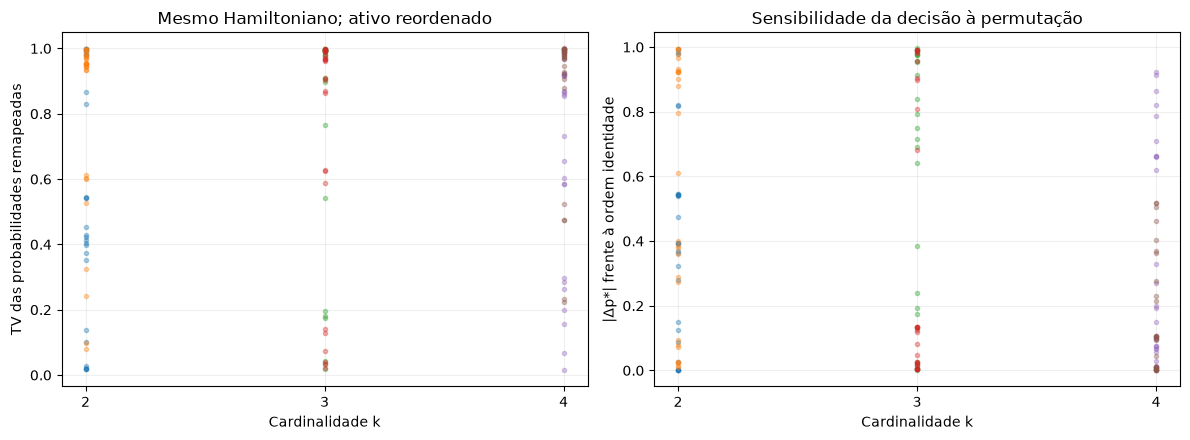

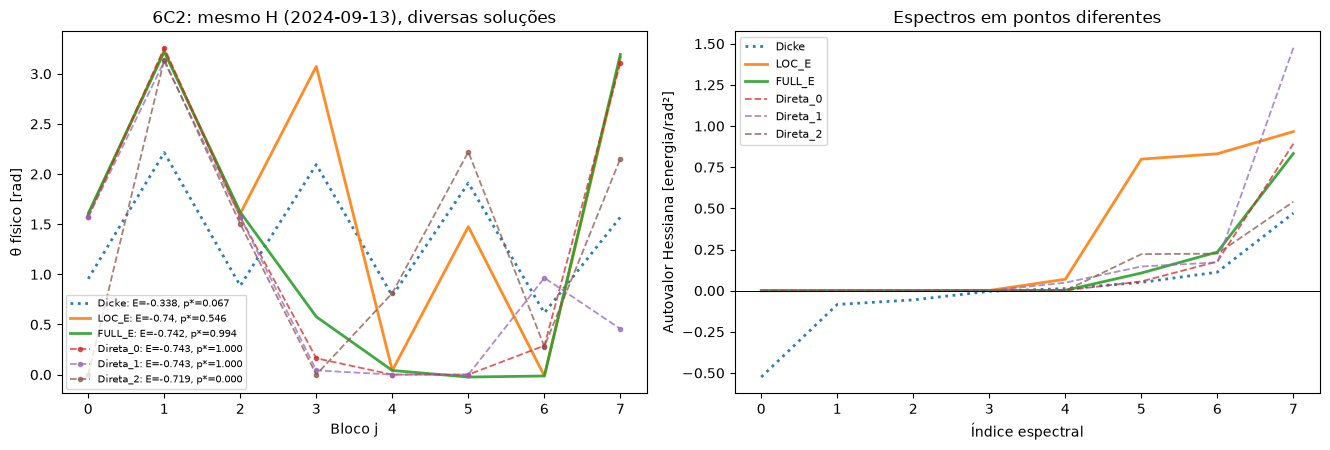

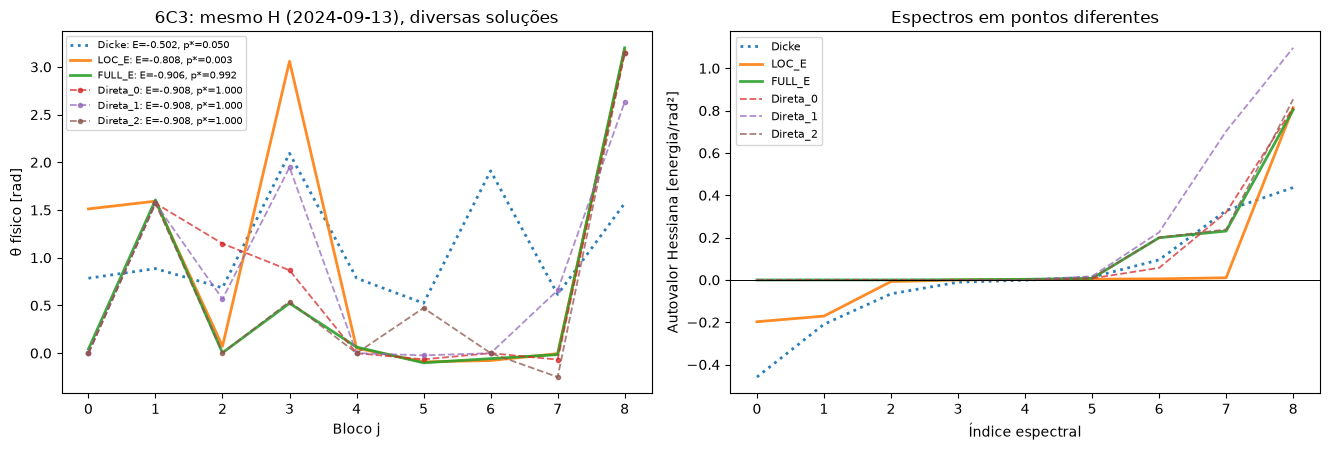

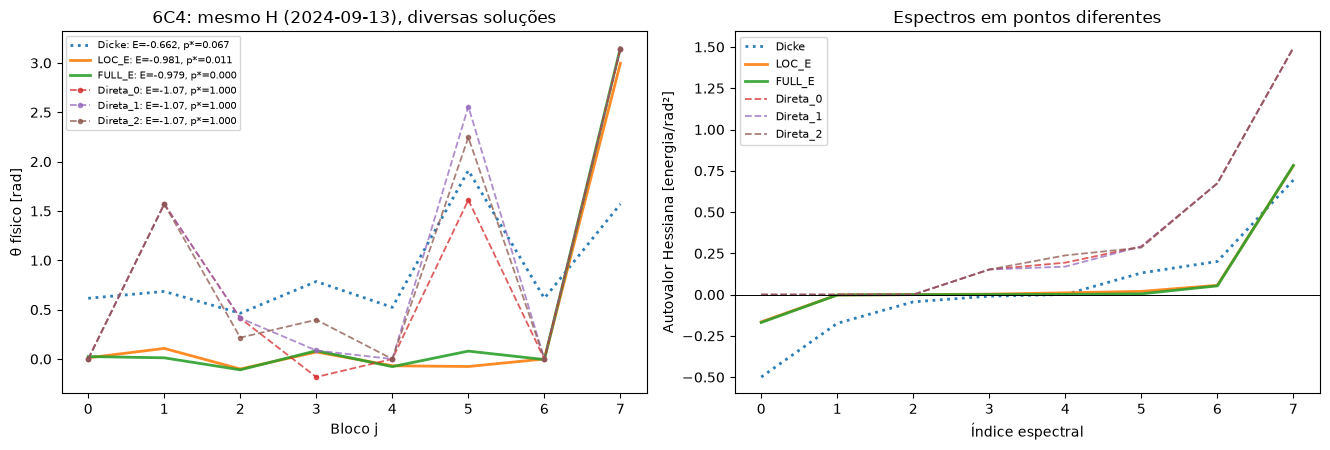

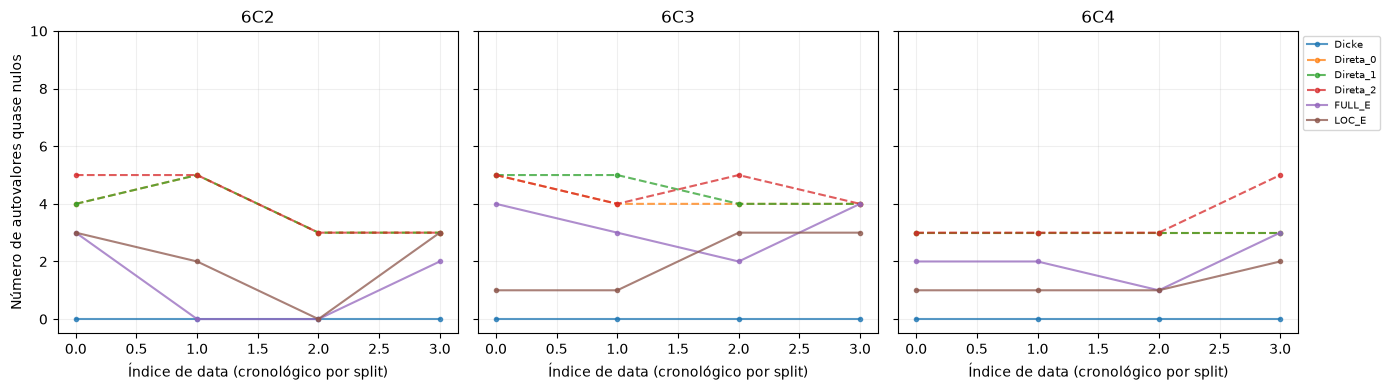

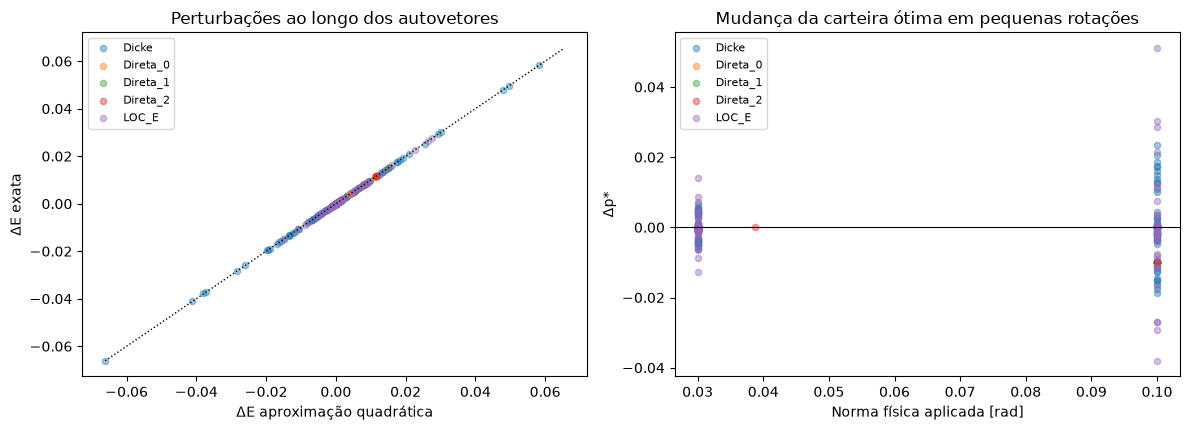

Gráficos salvos em C:\Users\Marlon\Downloads\g539_dicke_6ativos_alvos_23d\g541_energia_sem_oraculo\g542_geometria_multidata


In [33]:
# A36 — Visualizações e arquivos persistentes.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Invariância: boxplots das diferenças sob permutação (identidade excluída).
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
for k in G539_KS:
    for label in G541_MODELOS:
        dat=G542_PERM_DF[(G542_PERM_DF.k==k)&(G542_PERM_DF.modelo==label)&(G542_PERM_DF.perm_indice>0)]
        style='-' if label=='LOC_E' else '--'
        axs[0].plot([k]*len(dat),dat.TV_canonico,'.',alpha=.35)
        axs[1].plot([k]*len(dat),np.abs(dat.delta_pstar_identidade),'.',alpha=.35)
axs[0].set(xlabel='Cardinalidade k',ylabel='TV das probabilidades remapeadas',
           title='Mesmo Hamiltoniano; ativo reordenado')
axs[1].set(xlabel='Cardinalidade k',ylabel='|Δp*| frente à ordem identidade',
           title='Sensibilidade da decisão à permutação')
for ax in axs:ax.set_xticks(G539_KS);ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(G542_OUT/'A36_permutacoes_energia_distribuicao.png',dpi=155);plt.show()

# Múltiplos perfis físicos: a primeira data de cada topologia.
for k in G539_KS:
    r=next(r for r in G542_CASOS if r['k']==k)
    case=(r['grupo'],r['data'],k);diags=G542_HESS_PONTOS[case];c=G539_CIRCUITOS[k]
    fig,axs=plt.subplots(1,2,figsize=(13.4,4.6))
    for n,d in diags.items():
        if n.startswith('Direta_'):st='--';alpha=.75;lw=1.3
        elif n=='Dicke':st=':';alpha=.95;lw=2
        else:st='-';alpha=.9;lw=2
        axs[0].plot(range(c.g),d['theta'],linestyle=st,alpha=alpha,linewidth=lw,
                    marker='.' if n.startswith('Direta_') else None,
                    label=f'{n}: E={d["energia"]:.3g}, p*={d["pstar"]:.3f}')
        axs[1].plot(np.arange(c.g),d['eig'],linestyle=st,linewidth=lw,alpha=alpha,label=n)
    axs[0].set(xlabel='Bloco j',ylabel='θ físico [rad]',
                title=f'6C{k}: mesmo H ({r["data"]}), diversas soluções')
    axs[1].axhline(0,color='black',linewidth=.7)
    axs[1].set(xlabel='Índice espectral',ylabel='Autovalor Hessiana [energia/rad²]',
                title='Espectros em pontos diferentes')
    axs[0].legend(fontsize=7);axs[1].legend(fontsize=8)
    fig.tight_layout();fig.savefig(G542_OUT/f'A36_6C{k}_angulos_mesmo_H_multistart.png',dpi=155);plt.show()

# Estabilidade das direções planas em todas as datas: número de autovalores por caso.
fig,axs=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,k in zip(axs,G539_KS):
    dd=G542_HESS_DF[G542_HESS_DF.k==k]
    for name,g in dd.groupby('ponto'):
        ax.plot(range(len(g)),g.n_flat,'.-' if not name.startswith('Direta_') else '.--',
                alpha=.75,label=name)
    ax.set(xlabel='Índice de data (cronológico por split)',title=f'6C{k}',ylim=(-.5,10))
    ax.grid(alpha=.2)
axs[0].set_ylabel('Número de autovalores quase nulos')
axs[-1].legend(fontsize=7,loc='upper left',bbox_to_anchor=(1,1))
fig.tight_layout();fig.savefig(G542_OUT/'A36_flatness_multidatas.png',dpi=155,bbox_inches='tight');plt.show()

# Curvatura vs perturbação de energia: incluir clipping no gráfico como marcador próprio.
fig,axs=plt.subplots(1,2,figsize=(12,4.4))
for name,group in G542_SENS_DF.groupby('ponto'):
    sel=group[group.direcao.isin(['eig_min','eig_max'])]
    axs[0].scatter(sel.dE_quadratico,sel.dE,alpha=.42,s=20,label=name)
    axs[1].scatter(sel.norma_aplicada,sel.dpstar,alpha=.42,s=20,label=name)
lo=min(G542_SENS_DF.dE_quadratico.min(),G542_SENS_DF.dE.min())
hi=max(G542_SENS_DF.dE_quadratico.max(),G542_SENS_DF.dE.max())
axs[0].plot([lo,hi],[lo,hi],'k:',lw=1)
axs[0].set(xlabel='ΔE aproximação quadrática',ylabel='ΔE exata',
           title='Perturbações ao longo dos autovetores')
axs[1].axhline(0,color='black',lw=.8)
axs[1].set(xlabel='Norma física aplicada [rad]',ylabel='Δp*',
           title='Mudança da carteira ótima em pequenas rotações')
axs[0].legend(fontsize=8);axs[1].legend(fontsize=8)
fig.tight_layout();fig.savefig(G542_OUT/'A36_autovetores_sensibilidade.png',dpi=155);plt.show()
print('Gráficos salvos em',G542_OUT)

## A37 — Síntese falsificável, limites e próximos critérios

**A inferência do Transformer não é ajustada nestas células.** Para cada data, o modelo prevê correções a partir de \((\mu(t),\Sigma(t))\); em seguida, a auditoria mede invariância financeira, invariância da distribuição sob permutações, estabilidade da Hessiana e sensibilidade. Só chamaremos de estrutura recorrente se o perfil sobreviver a várias datas, permutações e inicializações, e se aproximar de soluções de baixa energia com pouca perda de \(p_*\). Em especial:

- \(E_H(x)\) é um **escore financeiro clássico** e \(\langle H\rangle\) é uma esperança de um circuito **classicamente simulado**; não há hardware quântico nem vantagem quântica demonstrada.
- Uma Hessiana quase singular não prova uma variedade global de soluções; pode decorrer de redundância do ansatz, simetria, contorno angular ou parametrização.
- Comparar a mesma data sob diferentes permutações exige remapear os bitstrings antes de comparar distribuições. Uma rede equivarante sob permutações teria \(\mathrm{TV}\approx0\); esta propriedade **não está garantida** pela arquitetura atual.
- A condição \(\nabla_{\theta}\mathcal E=0\) não é suficiente para mínimo; as fronteiras requerem condições projetadas e curvatura restrita.
- As múltiplas tentativas de L-BFGS-B são uma **referência diagnóstica sem conhecimento do ótimo**, não targets do Transformer.

In [34]:
# A37 — Resumo automático sem selecionar variantes com base nos testes.
print('=== G542 | MESMO H: sensibilidade à ordem dos ativos ===')
display(G542_PERM_DF[G542_PERM_DF.perm_indice>0]
 .groupby(['modelo','grupo','k']).agg(n=('TV_canonico','size'),
    TV_media=('TV_canonico','mean'),delta_E_abs=('delta_energia_identidade',lambda x:np.abs(x).mean()),
    delta_pstar_abs=('delta_pstar_identidade',lambda x:np.abs(x).mean())).round(6))
print('=== G542 | VÁRIAS DATAS: curvatura local nas soluções diretas ===')
display(G542_HESS_DF[G542_HESS_DF.ponto.str.startswith('Direta_')]
 .groupby(['grupo','k']).agg(n=('n_flat','size'),direcoes_planas_med=('n_flat','mean'),
    direcoes_planas_min=('n_flat','min'),direcoes_planas_max=('n_flat','max'),
    kkt_medio=('kkt_norm','mean')).round(5))
print('=== G542 | REINÍCIOS: soluções de energia e p* semelhantes ===')
display(G542_MULTI_DF.groupby(['grupo','k']).agg(
   pares=('equivalencia_aproximada','size'),equivalentes=('equivalencia_aproximada','sum'),
   RMSE_fase_medio=('rmse_fase','mean'),TV_medio=('TV_dist','mean')).round(5))
print('=== G542 | SENSIBILIDADE: curvas guardadas ===')
print('CSV e figuras:',str(G542_OUT))
assert G542_PERM_DF.shape[0]>0 and G542_HESS_DF.shape[0]>0 and G542_SENS_DF.shape[0]>0

=== G542 | MESMO H: sensibilidade à ordem dos ativos ===


n  TV_media  delta_E_abs  delta_pstar_abs
modelo grupo          k                                            
FULL_E teste_2025     2   7  0.792854     0.478460         0.406964
                      3   7  0.847714     0.612717         0.208175
                      4   7  0.987950     0.415582         0.102438
       teste_2026     2   7  0.724847     0.144661         0.385085
                      3   7  0.659287     0.112193         0.240144
                      4   7  0.855192     0.222655         0.094057
       validacao_2024 2  14  0.841052     0.083481         0.687511
                      3  14  0.717228     0.054837         0.506013
                      4  14  0.814110     0.174686         0.235449
LOC_E  teste_2025     2   7  0.469980     0.307538         0.375436
                      3   7  0.554626     0.169595         0.440184
                      4   7  0.512168     0.112960         0.348381
       teste_2026     2   7  0.493586     0.169193         0.483458
                      3   7  0.545590     0.126055         0.530242
                      4   7  0.686128     0.325775         0.335757
       validacao_2024 2  14  0.579307     0.036257         0.372613
                      3  14  0.989234     0.153909         0.610126
                      4  14  0.787451     0.077627         0.327344

=== G542 | VÁRIAS DATAS: curvatura local nas soluções diretas ===


n  direcoes_planas_med  direcoes_planas_min  \
grupo          k                                                
teste_2025     2  3              3.00000                    3   
               3  3              4.33333                    4   
               4  3              3.00000                    3   
teste_2026     2  3              3.00000                    3   
               3  3              4.00000                    4   
               4  3              3.66667                    3   
validacao_2024 2  6              4.66667                    4   
               3  6              4.66667                    4   
               4  6              3.00000                    3   

                  direcoes_planas_max  kkt_medio  
grupo          k                                  
teste_2025     2                    3        0.0  
               3                    5        0.0  
               4                    3        0.0  
teste_2026     2                    3        0.0  
               3                    4        0.0  
               4                    5        0.0  
validacao_2024 2                    5        0.0  
               3                    5        0.0  
               4                    3        0.0

=== G542 | REINÍCIOS: soluções de energia e p* semelhantes ===


pares  equivalentes  RMSE_fase_medio  TV_medio
grupo          k                                                
teste_2025     2      3             3          0.23972   0.00000
               3      3             0          0.94137   1.00000
               4      3             3          0.15759   0.00000
teste_2026     2      3             1          0.72685   0.66667
               3      3             1          0.70962   0.66667
               4      3             1          0.74755   0.66667
validacao_2024 2      6             4          0.65765   0.33333
               3      6             4          0.50837   0.33333
               4      6             4          0.36509   0.33333

=== G542 | SENSIBILIDADE: curvas guardadas ===
CSV e figuras: C:\Users\Marlon\Downloads\g539_dicke_6ativos_alvos_23d\g541_energia_sem_oraculo\g542_geometria_multidata
